# Data Challenge PRO Extreme Technologies 2026 — Ruta 14-15 (Silencio)

**Autores:** Camilo Mujica, Carlos Romero y Sergio Rada.

### Metodología

Análisis exploratorio de la ruta **14-15 / Silencio** (`idruta = 2`), construcción del grafo de puntos, análisis de oferta y carga por segmentos, modelado inicial de demanda por viaje con GLM y modelado LightGBM de demanda por nodo y de demanda horaria de ruta. Se emplea validación temporal *walk-forward*, con horizontes H = 7, 3 y 1 día según el experimento, y se evalúa la utilidad de los pronósticos para optimizar frecuencias.

**Alcance temporal:** el panel horario utilizado para entrenar contiene datos del **1 de enero al 30 de agosto de 2025**. Los registros de carga por segmento de enero–febrero de 2023 se usan como referencia histórica de ocupación, no como parte del panel de entrenamiento de 2025.


# 1. Extracción de datos

Esta parte prepara todo lo necesario para trabajar con los datos de forma segura: monta el proyecto desde Google Drive, instala las librerías y abre una conexión
a PostgreSQL que **solo permite leer**. Se ejecuta una vez al inicio de cada sesión.  

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Instalación de librerías que Colab no trae por defecto.

!pip install -q "psycopg[binary]" python-dotenv pandas numpy matplotlib seaborn folium
!pip install -q lightgbm optuna shap holidays pyarrow

### Conectar a PostgreSQL  

- Las credenciales se leen del `.env` mediante variables de entorno; nunca se escriben
  en el código. La credencial de escritura (`DATABASE_URL_WRITE`) se descarta a propósito.
- La sesión se abre en **modo solo lectura** (`default_transaction_read_only` y
  `read_only=True`), de modo que ninguna celda puede modificar tablas, triggers ni datos.
- Se configuran tiempos límite (`statement_timeout` e `idle_in_transaction_session_timeout`)
  para que una consulta pesada no afecte la base operativa.
- Una prueba automática intenta escribir y debe fallar; si no falla, la ejecución se detiene.
- La conexión usa SSL (`sslmode=require`).


In [ ]:
import os
import psycopg
from dotenv import load_dotenv

PROY = '/content/drive/MyDrive/proyecto_sobusa'
DATA = os.path.join(PROY, 'data')
DOCS = os.path.join(PROY, 'docs')

load_dotenv(os.path.join(PROY, '.env'))

# Este notebook nunca debe usar la credencial de escritura
os.environ.pop('DATABASE_URL_WRITE', None)

CONN = psycopg.connect(
    host=os.environ['DB_HOST'], port=os.environ['DB_PORT'],
    dbname=os.environ['DB_NAME'], user=os.environ['DB_USER'],
    password=os.environ['DB_PASSWORD'],
    sslmode='require', connect_timeout=10,
    # Cada transacción de la sesión nace en solo lectura y con timeout
    options='-c default_transaction_read_only=on '
            '-c statement_timeout=300000 '
            '-c idle_in_transaction_session_timeout=600000',
)
CONN.read_only = True      # refuerzo del lado del cliente
CONN.autocommit = True     # sin transacciones abiertas ni "transacción abortada"

# Prueba: debe fallar. Si no falla, detener todo.
try:
    CONN.execute("CREATE TEMP TABLE __ro_test (x int)")
    CONN.execute("CREATE TABLE public.__ro_test (x int)")
    raise SystemExit('PELIGRO: la sesión permite escribir')
except psycopg.errors.ReadOnlySqlTransaction:
    print('OK: la sesión es de solo lectura')
except psycopg.errors.InsufficientPrivilege:
    print('OK: el usuario no tiene permiso de escritura')

print('Conectado a', os.environ['DB_NAME'])

OK: la sesión es de solo lectura
Conectado a dataset


Se consulta la tabla timbradas_anio y se relaciona con rutas para resumir la información de SOBUSA entre 2023 y 2025. Se agrupan los registros por año y ruta, calculando la cantidad de filas y el total de subidas, con el fin de explorar la disponibilidad de datos y comparar la demanda registrada entre rutas y años.

In [ ]:
cur = CONN.cursor()
cur.execute("""
    select a.ano, r.nombre, count(*) filas, sum(a.subidas) subidas
    from timbradas_anio a
    join rutas r on r.idruta = a.id_ruta
    where a.proceso = 'sobusa' and a.ano in (2023,2024,2025)
    group by 1,2 order by 1,2
""")
for r in cur.fetchall():
    print(r)
cur.close()

(2023, 'CL 72', 2079, 2711837)
(2023, 'CRA 54', 2835, 8774466)
(2023, 'SILENCIO', 2502, 4280981)
(2024, 'CL 72', 2136, 2628023)
(2024, 'CRA 54', 2867, 8075734)
(2024, 'SILENCIO', 2517, 3885647)
(2025, 'CL 72', 2327, 2390443)
(2025, 'CRA 54', 3106, 7469245)
(2025, 'SILENCIO', 2666, 3578755)


# 2. Análisis exploratorio de datos (EDA) — Ruta 14-15

Se revisa primero la estructura de la base de datos SOBUSA y después se estudia la ruta **14-15 / Silencio** (`idruta = 2`): demanda consolidada, cobertura por día y hora, valores extremos, distribución espacial de los puntos y condiciones operativas necesarias para la optimización.


In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import seaborn as sns
import folium   # mapas; se instala en la seccion 2

# ---------------------------------------------------------------------------
# Ruta de analisis: 14 15
# DATA se redefine para que los archivos intermedios de esta ruta queden en
# data/r1415 y no se mezclen con los de las otras rutas.
# ---------------------------------------------------------------------------
RUTA_NOMBRE = '14 15'
RUTA_ID = 2           # idruta de la ruta 14 15; con None se busca por nombre en la tabla rutas
DATA = os.path.join(PROY, 'data', 'r1415')
os.makedirs(DATA, exist_ok=True)

with CONN.cursor() as _cur:                       # consulta de solo lectura
    _cur.execute('SELECT idruta, nombre FROM rutas ORDER BY idruta')
    _rutas = _cur.fetchall()
if RUTA_ID is None:
    _cand = [r for r in _rutas if str(r[1]).strip().upper() == RUTA_NOMBRE]
    if len(_cand) != 1:
        raise ValueError('No se encontro una ruta llamada "%s" en rutas. Rutas: %s. Fijar RUTA_ID a mano.' % (RUTA_NOMBRE, _rutas))
    RUTA_ID = int(_cand[0][0])
print('Ruta de analisis: %s (idruta = %d)' % (dict(_rutas)[RUTA_ID], RUTA_ID))


Ruta de analisis: SILENCIO (idruta = 2)


In [ ]:
import pandas as pd
from IPython.display import display, Markdown

cols = pd.read_sql("""
    SELECT table_name, column_name, data_type
    FROM information_schema.columns
    WHERE table_schema = 'public'
    ORDER BY table_name, ordinal_position
""", CONN)

SCHEMA = cols.groupby("table_name")["column_name"].apply(list).to_dict()

display(Markdown(f"**{len(SCHEMA)} tablas visibles**"))

schema_table = pd.DataFrame({
    "N.º": range(1, len(SCHEMA) + 1),
    "Tabla": sorted(SCHEMA),
    "Columnas": [len(SCHEMA[t]) for t in sorted(SCHEMA)]
})
display(schema_table)

print("Total de variables:", sum(len(c) for c in SCHEMA.values()))

/tmp/ipykernel_1374/45276514.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  cols = pd.read_sql("""


**29 tablas visibles**

,N.º,Tabla,Columnas
0,1,Procesos,88
1,2,conteo_pasajeros_destino,25
2,3,dias_semana,2
3,4,estacionalidades,5
4,5,estacionalidades_anio,6
5,6,geography_columns,7
6,7,geometry_columns,7
7,8,novedades_viales,5
8,9,novedades_viales_fecha,8
9,10,novedades_viales_ruta,3


Total de variables: 587


El inventario de la base registra **29 tablas y 587 columnas**. Esta revisión es global para SOBUSA; el análisis posterior se concentra en los datos correspondientes a la ruta 14-15.

### Inspección de las tablas

Se examina el número de filas y columnas de las tablas para distinguir fuentes útiles, fuentes auxiliares y tablas sin registros. Las cifras de filas pueden proceder de recuentos exactos o estimaciones del catálogo, según la tabla.


In [ ]:
import numpy as np
import pandas as pd
from psycopg import sql
from IPython.display import display, Markdown

def consulta(query, params=None):
    with CONN.cursor() as cur:
        cur.execute(query, params)
        return pd.DataFrame(cur.fetchall(), columns=[d.name for d in cur.description])

COLS_DB = consulta("""
    SELECT table_name, column_name, data_type, udt_name
    FROM information_schema.columns
    WHERE table_schema = 'public'
    ORDER BY table_name, ordinal_position
""")

CATALOGO = consulta("""
    SELECT c.relname AS tabla,
           c.relkind,
           c.reltuples::bigint AS filas_estimadas,
           pg_relation_size(c.oid) AS bytes_tabla,   -- tamaño real actual, no depende de ANALYZE
           pg_size_pretty(pg_total_relation_size(c.oid)) AS tamano
    FROM pg_class c
    JOIN pg_namespace n ON n.oid = c.relnamespace
    WHERE n.nspname = 'public' AND c.relkind IN ('r', 'p')
    ORDER BY c.relname
""").set_index('tabla')
CATALOGO['columnas'] = COLS_DB.groupby('table_name').size().reindex(CATALOGO.index)

UMBRAL_EXACTO = 200 * 1024**2   # hasta 200 MB se cuenta exacto

def contar(tabla):
    with CONN.cursor() as cur:
        cur.execute(sql.SQL("SELECT count(*) FROM {}").format(sql.Identifier(tabla)))
        return cur.fetchone()[0]

filas, conteo = [], []
for t, r in CATALOGO.iterrows():
    if r.relkind == 'r' and r.bytes_tabla <= UMBRAL_EXACTO:
        filas.append(contar(t)); conteo.append('exacto')
    else:
        filas.append(r.filas_estimadas); conteo.append('estimado')
CATALOGO['filas'] = filas
CATALOGO['conteo'] = conteo

display(CATALOGO[['filas', 'conteo', 'columnas', 'tamano']])

,filas,conteo,columnas,tamano
tabla,,,,
Procesos,1,exacto,88,32 kB
conteo_pasajeros_destino,175855824,estimado,25,43 GB
dias_semana,7,exacto,2,40 kB
estacionalidades,24,exacto,5,32 kB
estacionalidades_anio,231,exacto,6,64 kB
novedades_viales,59,exacto,5,64 kB
novedades_viales_fecha,28,exacto,8,24 kB
novedades_viales_ruta,0,exacto,3,8192 bytes
progvehiculos,565583,estimado,73,975 MB


El inventario permite identificar tablas sin registros que no aportarían observaciones directas al análisis, entre ellas `novedades_viales_ruta`, `timbradas_anio_trazabilidad`, `timbradas_anio_zonas`, `timbradas_anio_zonas_trazabilidad`, `timbradas_consolidado_zonas`, `timbradas_segmentos_anio`, `timbradas_segmentos_anio_trazabilidad` y `timbradas_segmentos_consolidado`.

Esto es una **selección analítica**, no una eliminación física de tablas de PostgreSQL. Otras fuentes, como `conteo_pasajeros_destino`, `progvehiculos`, `rutas_segmentos` y `timbradas_segmentos`, se emplean más adelante para reconstruir la demanda, el servicio y el recorrido.


## 2.1 Análisis de variables principales

Se estudia `timbradas_consolidado` para la ruta **14-15 / Silencio** (`id_ruta = 2`), junto con las tablas de días y estacionalidades. Cada fila resume una combinación de día de la semana, estacionalidad y franja horaria; sus subidas, bajadas y viajes son **valores agregados**, no pasajeros observados en un único día.

El consolidado contiene **3.562 filas**, sin duplicados respecto a la clave usada para este análisis. El código comprueba y elimina eventuales duplicados antes de calcular los resúmenes.


In [ ]:
SQL_r1415 = f'''
SELECT
  tc.id_ruta,
  r.nombre,
  tc.id_dia_semana,
  d.dia_semana,
  tc.id_estacionalidad,
  e.estacionalidad,
  tc.hora,
  tc.hora_inicio,
  tc.hora_fin,
  tc.subidas,
  tc.bajadas,
  tc.nro_viajes,
  tc.promedio_subidas,
  tc.promedio_bajadas,
  tc.ultima_actualizacion
FROM timbradas_consolidado tc
JOIN rutas r           ON r.idruta = tc.id_ruta
JOIN dias_semana d     ON d.id_dia_semana = tc.id_dia_semana
JOIN estacionalidades e ON e.id_estacionalidad = tc.id_estacionalidad
WHERE tc.id_ruta = {RUTA_ID}
'''

In [ ]:
raw = pd.read_sql(SQL_r1415, CONN)
print('Filas crudas:', f'{len(raw):,}')

KEY = ['id_dia_semana', 'id_estacionalidad', 'hora_inicio']
r1415 = raw.drop_duplicates(subset=KEY, keep='first').reset_index(drop=True)
print('Filas unicas:', f'{len(r1415):,}')
print('Eliminadas   :', f'{len(raw) - len(r1415):,}')

r1415['hora_num'] = r1415['hora_inicio'].apply(lambda x: x.hour + x.minute / 60 if pd.notnull(x) else None)

r1415.head()

/tmp/ipykernel_1374/1914890639.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  raw = pd.read_sql(SQL_r1415, CONN)


Filas crudas: 3,562
Filas unicas: 3,562
Eliminadas   : 0


,id_ruta,nombre,id_dia_semana,dia_semana,id_estacionalidad,estacionalidad,hora,hora_inicio,hora_fin,subidas,bajadas,nro_viajes,promedio_subidas,promedio_bajadas,ultima_actualizacion,hora_num
0,2,SILENCIO,1,Lunes,1,FESTIVO_NACIONAL,01:00:00,01:00:00,01:15:00,233,219,3,77.67,73.0,2026-08-14 11:29:05.057003,1.00
1,2,SILENCIO,1,Lunes,1,FESTIVO_NACIONAL,05:00:00,05:00:00,05:15:00,100,110,2,50.00,55.0,2026-08-14 11:29:05.057003,5.00
2,2,SILENCIO,1,Lunes,1,FESTIVO_NACIONAL,05:00:00,05:45:00,06:00:00,7,7,1,7.00,7.0,2026-08-14 11:29:05.057003,5.75
3,2,SILENCIO,1,Lunes,1,FESTIVO_NACIONAL,06:00:00,06:00:00,06:15:00,260,234,4,65.00,58.5,2026-08-14 11:29:05.057003,6.00
4,2,SILENCIO,1,Lunes,1,FESTIVO_NACIONAL,06:00:00,06:15:00,06:30:00,42,46,2,21.00,23.0,2026-08-14 11:29:05.057003,6.25


### Resumen estadístico

In [ ]:
COLS_NUM = ['subidas', 'bajadas', 'nro_viajes', 'promedio_subidas', 'promedio_bajadas']

resumen = r1415[COLS_NUM].describe().T
resumen['skew'] = r1415[COLS_NUM].skew()
resumen['ceros'] = (r1415[COLS_NUM] == 0).sum()
resumen['nulos'] = r1415[COLS_NUM].isna().sum()
resumen

,count,mean,std,min,25%,50%,75%,max,skew,ceros,nulos
subidas,3562.0,3297.412409,8356.084482,0.0,115.00,232.5,518.000,47540.0,2.767775,40,0
bajadas,3562.0,3219.247333,8135.717841,0.0,113.00,228.0,505.500,46108.0,2.755951,41,0
nro_viajes,3562.0,42.779057,101.126423,1.0,2.00,4.0,7.000,499.0,2.456579,0,0
promedio_subidas,3562.0,65.723807,28.578797,0.0,45.33,61.0,82.215,238.0,0.786522,40,0
promedio_bajadas,3562.0,64.617566,27.825910,0.0,45.00,60.0,81.000,229.0,0.782394,41,0


El resumen de `timbradas_consolidado` para la ruta **14-15** comprende **3.562 registros** y cinco variables numéricas. No se observan valores nulos en estas columnas.

- **Subidas y bajadas:** medias de **3.297,4** y **3.219,2**, frente a medianas de **232,5** y **228**; sus máximos son **47.540** y **46.108**. La diferencia entre medias y medianas evidencia una distribución muy sesgada a la derecha, porque algunas celdas acumulan muchos viajes.
- **Número de viajes:** mediana de **4**, media de **42,8** y máximo de **499**. Comparar subidas sin tener en cuenta esta exposición mezcla franjas con volúmenes de servicio muy diferentes.
- **Promedios por viaje:** `promedio_subidas` tiene media **65,7**, mediana **61** y máximo **238**; `promedio_bajadas` tiene media **64,6**, mediana **60** y máximo **229**. Estas variables resultan más comparables entre franjas que los acumulados crudos.
- **Registros en cero:** hay **40** filas con cero subidas y **41** con cero bajadas. Esos casos pueden corresponder a ausencia de pasajeros registrados o a fallas de conteo; el consolidado por sí solo no permite distinguirlos.

Los valores altos requieren una revisión por cantidad de viajes y estacionalidad antes de calificarlos como errores.


### Cobertura por día de la semana

In [ ]:
agg_dia = r1415.groupby(['id_dia_semana', 'dia_semana'], as_index=False).agg(
    registros=('subidas', 'count'),
    subidas_tot=('subidas', 'sum'),
    bajadas_tot=('bajadas', 'sum'),
    subidas_prom=('subidas', 'mean'),
    viajes_prom=('nro_viajes', 'mean'),
).sort_values('id_dia_semana')

agg_dia

,id_dia_semana,dia_semana,registros,subidas_tot,bajadas_tot,subidas_prom,viajes_prom
0,1,Lunes,1139,1861826,1817673,1634.614574,21.242318
1,2,Martes,347,1899977,1850845,5475.438040,65.576369
2,3,Miércoles,457,1900914,1851933,4159.549234,50.361050
3,4,Jueves,490,1859083,1812134,3794.046939,46.957143
4,5,Viernes,326,1811931,1767246,5558.070552,68.082822
5,6,Sábado,351,1554397,1520747,4428.481481,62.686610
6,7,Domingo,452,857255,846381,1896.581858,33.643805


La agregación compara registros y demanda **acumulada en el consolidado**, clasificados por día de la semana.

- **Subidas totales:** entre **1,81 y 1,90 millones** de lunes a viernes; **1,55 millones** el sábado y **0,86 millones** el domingo. Son sumas de la tabla consolidada, no promedios de un día de operación.
- **Cobertura desigual:** el lunes tiene **1.139 registros**, mientras que los demás días tienen entre **326 y 490**. Por eso el promedio por fila no representa directamente la demanda de un día típico.
- **Subidas y bajadas:** los totales son relativamente próximos en todos los días; por ejemplo, el miércoles registra **1.900.914 subidas** y **1.851.933 bajadas**. No se observa el fuerte desbalance de bajadas descrito en versiones anteriores del texto.

Para comparar jornadas operativas deben emplearse métricas normalizadas por servicio o por días efectivamente observados, y no solo los promedios de celdas consolidadas.

### Cobertura por estacionalidad (temporadas y festivos)


In [ ]:
agg_est = r1415.groupby('estacionalidad', as_index=False).agg(
    registros=('subidas', 'count'),
    subidas_prom=('subidas', 'mean'),
    bajadas_prom=('bajadas', 'mean'),
    viajes_prom=('nro_viajes', 'mean'),
).sort_values('subidas_prom', ascending=False)

agg_est

,estacionalidad,registros,subidas_prom,bajadas_prom,viajes_prom
0,DIAS_CORRIENTES,591,18573.463621,18125.175973,237.994924
3,FIESTA_ATLANTICO,749,431.054740,421.602136,5.284379
4,TEMPORADA_NACIONAL,473,322.883721,317.494715,5.473573
1,FESTIVO_NACIONAL,1576,169.270939,167.151015,3.056472
2,FIESTAS_PATRONALES,173,150.930636,147.947977,2.080925


El consolidado agrupa registros de distintas estacionalidades, pero **el número de viajes acumulados por registro varía considerablemente**.

- **`DIAS_CORRIENTES`:** **591 registros**, con medias de **18.573 subidas**, **18.125 bajadas** y **238 viajes** por registro. Es el régimen que reúne los agregados de mayor tamaño.
- **`FIESTA_ATLANTICO`:** **749 registros**, **431 subidas** y **5,28 viajes** de media.
- **`TEMPORADA_NACIONAL`:** **473 registros**, **323 subidas** y **5,47 viajes** de media.
- **`FESTIVO_NACIONAL`:** **1.576 registros**, **169 subidas** y **3,06 viajes** de media.
- **`FIESTAS_PATRONALES`:** **173 registros**, **151 subidas** y **2,08 viajes** de media.

Las diferencias de acumulados no significan, por sí mismas, que un pasajero típico viaje decenas de veces más en días corrientes. Reflejan sobre todo **cuántos viajes se acumulan** en cada registro. Por ello conviene normalizar por `nro_viajes` antes de comparar niveles de demanda entre regímenes.

### Perfil horario de la demanda


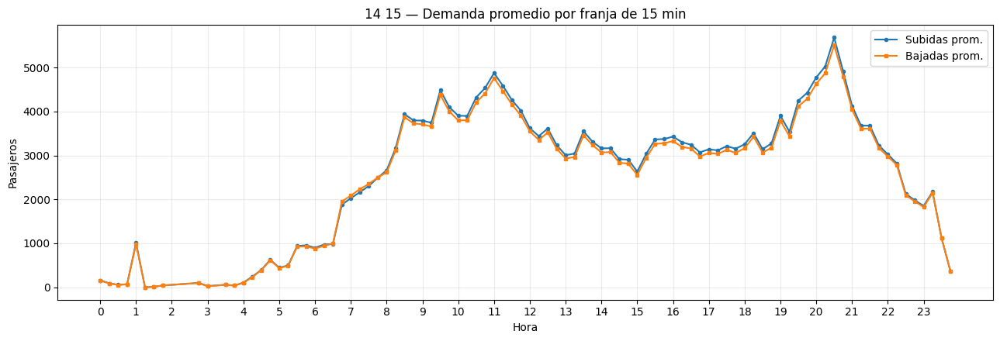

In [ ]:
agg_hora = r1415.groupby('hora_num', as_index=False).agg(
    subidas_prom=('subidas', 'mean'),
    bajadas_prom=('bajadas', 'mean'),
    viajes_prom=('nro_viajes', 'mean'),
).sort_values('hora_num')

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(agg_hora['hora_num'], agg_hora['subidas_prom'], marker='o', ms=3, label='Subidas prom.')
ax.plot(agg_hora['hora_num'], agg_hora['bajadas_prom'], marker='s', ms=3, label='Bajadas prom.')
ax.set_title('14 15 — Demanda promedio por franja de 15 min')
ax.set_xlabel('Hora')
ax.set_ylabel('Pasajeros')
ax.set_xticks(range(0, 24))
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

El perfil horario del consolidado de **14-15** muestra actividad reducida en las horas con pocos registros, incremento durante la mañana y dos franjas de mayor acumulación: alrededor de **las 11:00** y, especialmente, **las 20:00–20:45**. Los valores máximos del promedio por franja se concentran en torno a las **20:30**.

Las curvas de subidas y bajadas son generalmente próximas; cualquier diferencia puntual debe evaluarse junto con el volumen de viajes de la franja. **Estas son medias de registros históricos agregados**, no estimaciones directas de pasajeros de una hora en un día particular.

### Mapa de calor: hora × día de la semana


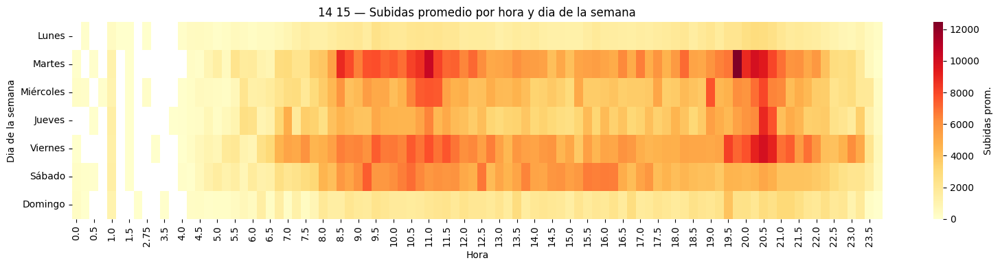

In [ ]:
pivot = r1415.pivot_table(index='id_dia_semana', columns='hora_num', values='subidas', aggfunc='mean')

orden_dias = (r1415[['id_dia_semana', 'dia_semana']]
              .drop_duplicates()
              .sort_values('id_dia_semana'))
pivot.index = orden_dias['dia_semana'].values

plt.figure(figsize=(16, 4))
sns.heatmap(pivot, cmap='YlOrRd', cbar_kws={'label': 'Subidas prom.'})
plt.title('14 15 — Subidas promedio por hora y dia de la semana')
plt.xlabel('Hora')
plt.ylabel('Dia de la semana')
plt.tight_layout()
plt.show()

El mapa de calor representa el promedio de subidas de las combinaciones **día de semana × hora** existentes en `timbradas_consolidado`. Permite localizar concentraciones relativas en la mañana y en la franja nocturna, especialmente hacia **las 20:00**.

Las diferencias de intensidad entre días están condicionadas por el número de registros y viajes que entran en cada celda. Las zonas sin color indican combinaciones sin observaciones en este resumen, **no necesariamente ausencia de servicio**. El gráfico es exploratorio y no sustituye al panel horario diario que se utiliza después para modelar demanda.

### Relación entre subidas y viajes


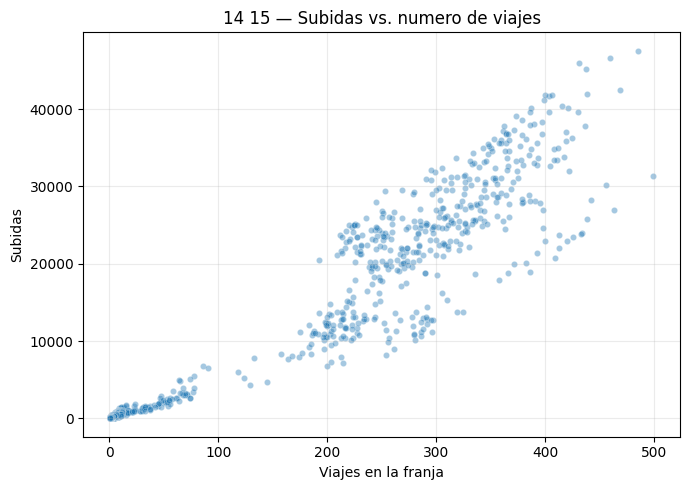

Correlacion viajes-subidas: 0.971


In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=r1415, x='nro_viajes', y='subidas', alpha=0.4, s=20, ax=ax)
ax.set_title('14 15 — Subidas vs. numero de viajes')
ax.set_xlabel('Viajes en la franja')
ax.set_ylabel('Subidas')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

correlacion = r1415['nro_viajes'].corr(r1415['subidas'])
print('Correlacion viajes-subidas:', round(correlacion, 3))

La nube de puntos muestra una **asociación positiva muy fuerte** entre subidas acumuladas y número de viajes (`r = 0,971`). Esto es esperable: las franjas que agrupan más viajes suelen acumular más pasajeros. Por tanto, una parte importante de la variabilidad del conteo bruto se explica por la exposición al servicio, lo que justifica estudiar también la tasa **subidas por viaje**.


### Outliers y calidad de los datos

In [ ]:
q1, q3 = r1415['subidas'].quantile([0.25, 0.75])
iqr = q3 - q1
lim_sup = q3 + 1.5 * iqr

print(f'Q1={q1:.0f}  Q3={q3:.0f}  umbral superior={lim_sup:.0f}')
print('Outliers altos (> umbral):', int((r1415['subidas'] > lim_sup).sum()))
print('Valores cero (subidas <= 0):', int((r1415['subidas'] <= 0).sum()))
print('Nulos en subidas           :', int(r1415['subidas'].isna().sum()))

r1415.nlargest(5, 'subidas')[['dia_semana', 'hora_inicio', 'estacionalidad',
                          'subidas', 'bajadas', 'nro_viajes']]

Q1=115  Q3=518  umbral superior=1122
Outliers altos (> umbral): 543
Valores cero (subidas <= 0): 40
Nulos en subidas           : 0


,dia_semana,hora_inicio,estacionalidad,subidas,bajadas,nro_viajes
2745,Viernes,20:30:00,DIAS_CORRIENTES,47540,46108,485
1413,Martes,20:15:00,DIAS_CORRIENTES,46554,44985,460
1863,Miércoles,20:30:00,DIAS_CORRIENTES,45889,44334,431
1414,Martes,20:30:00,DIAS_CORRIENTES,45122,43341,438
1826,Miércoles,11:15:00,DIAS_CORRIENTES,42455,41268,469


### Distribución de la demanda

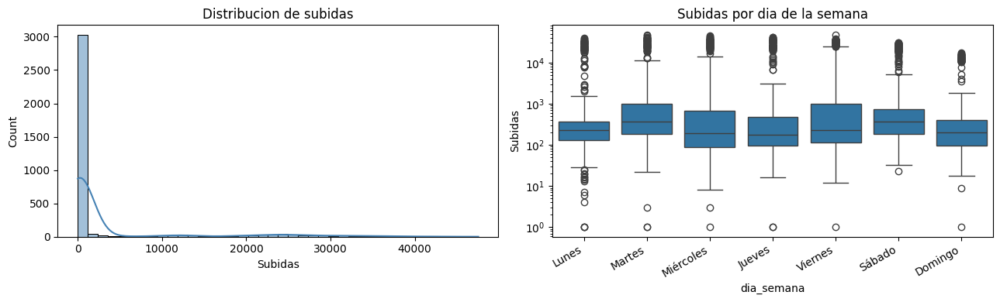

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(r1415['subidas'], bins=40, kde=True, ax=axes[0], color='steelblue')
plt.yscale('log')
axes[0].set_title('Distribucion de subidas')
axes[0].set_xlabel('Subidas')

sns.boxplot(x='dia_semana', y='subidas', data=r1415,
            order=orden_dias['dia_semana'].values, ax=axes[1])
axes[1].set_title('Subidas por dia de la semana')
axes[1].set_ylabel('Subidas')
plt.setp(axes[1].get_xticklabels(), rotation=30, ha='right')
plt.tight_layout()
plt.show()

La distribución de `subidas` está fuertemente sesgada a la derecha: la **mediana es 232,5**, pero el máximo alcanza **47.540** pasajeros acumulados. La mayoría de las celdas contiene cifras mucho menores que las de los grandes agregados de `DIAS_CORRIENTES`.

El histograma permite observar esta cola larga; el boxplot por día también refleja una dispersión importante y numerosos valores altos. No todos esos casos constituyen errores de conteo: algunos representan franjas con muchos viajes acumulados.

La mediana y las medidas por viaje describen mejor el comportamiento típico que la media de los acumulados sin normalizar.


### Franjas pico y valle (insumo para alertas y descongestión)

In [ ]:
agg_hora_sorted = agg_hora.sort_values('subidas_prom', ascending=False)

print('5 franjas de mayor demanda:')
print(agg_hora_sorted.head(5)[['hora_num', 'subidas_prom', 'viajes_prom']].to_string(index=False))

print('5 franjas de menor demanda:')
print(agg_hora_sorted.tail(5)[['hora_num', 'subidas_prom', 'viajes_prom']].to_string(index=False))

5 franjas de mayor demanda:
 hora_num  subidas_prom  viajes_prom
    20.50   5684.877551    60.346939
    20.25   5028.560000    53.160000
    20.75   4921.734694    55.877551
    11.00   4876.604167    56.083333
    20.00   4776.960784    50.392157
5 franjas de menor demanda:
 hora_num  subidas_prom  viajes_prom
     1.75     40.000000     1.000000
     3.75     38.000000     1.000000
     3.00     27.000000     1.000000
     1.50     11.333333     2.166667
     1.25      0.000000     1.000000


Las cinco franjas de mayor promedio de subidas se sitúan en **20:00, 20:15, 20:30, 20:45 y 11:00**. La más alta es **20:30**, con aproximadamente **5.685 subidas** y **60 viajes** por registro consolidado; **11:00** alcanza unas **4.877 subidas**.

En contraste, las franjas de menor promedio aparecen en la madrugada y cuentan con muy pocos viajes, por lo que deben interpretarse con cautela. Estos promedios históricos no bastan para recomendar directamente una nueva frecuencia: la optimización requiere la demanda horaria diaria y la carga a bordo.

### Resumen por hora


In [ ]:
agg_franja = r1415.assign(franja=np.floor(r1415['hora_num'])).groupby('franja', as_index=False).agg(
    subidas_prom=('subidas', 'mean'),
    bajadas_prom=('bajadas', 'mean'),
    viajes_prom=('nro_viajes', 'mean'),
    subidas_max=('subidas', 'max'),
).sort_values('franja')

agg_franja

,franja,subidas_prom,bajadas_prom,viajes_prom,subidas_max
0,0.0,105.785714,101.642857,2.214286,326
1,1.0,838.586957,814.130435,12.326087,6713
2,2.0,99.000000,95.000000,1.000000,150
3,3.0,40.333333,38.000000,1.000000,56
4,4.0,372.575758,363.606061,7.818182,1196
5,5.0,688.803030,674.333333,17.030303,2618
6,6.0,1250.021277,1263.308511,28.255319,10124
7,7.0,2258.532258,2301.556452,44.306452,14817
8,8.0,3395.161290,3335.142857,46.442396,37773
9,9.0,4029.488372,3934.888372,47.562791,38601


Al agrupar por hora entera, el mayor promedio de subidas del consolidado aparece a **las 20:00 (≈5.099)** y otro máximo local a **las 11:00 (≈4.423)**. Entre las 13:00 y las 18:00 los promedios son más moderados, alrededor de **3.000–3.300** subidas por registro.

Las bajadas siguen una pauta similar a la de las subidas; no se observa en esta salida el exceso extremo de bajadas descrito en el análisis de CRA 54. Los máximos de cada hora siguen siendo **acumulados de registros consolidados**, por lo que no deben confundirse con pasajeros transportados en una hora real.


### Diagnostico de los valores altos en `subidas`

In [ ]:
# Los valores altos de 'subidas' son coherentes con el volumen de servicio,
# no con un error ni con una unidad distinta:
#
#   - todas las filas de timbradas_consolidado agregan la flota de la ruta;
#   - la unidad SIEMPRE es pasajeros;
#   - lo que cambia entre regimenes es cuantos viajes hubo en la franja.
#
# Comprobacion: el promedio por viaje debe ser estable en todo el dataset.
for col in ('subidas', 'bajadas'):
    d = (r1415[col] / r1415['nro_viajes']).replace([np.inf, -np.inf], np.nan).dropna()
    print(f'{col}/nro_viajes -> max {d.max():.3f} | min {d.min():.3f} | promedio {d.mean():.3f}')

print()
print('Comparacion por tipo de estacionalidad:')
print(agg_est.to_string(index=False))

subidas/nro_viajes -> max 238.000 | min 0.000 | promedio 65.724
bajadas/nro_viajes -> max 229.000 | min 0.000 | promedio 64.617

Comparacion por tipo de estacionalidad:
    estacionalidad  registros  subidas_prom  bajadas_prom  viajes_prom
   DIAS_CORRIENTES        591  18573.463621  18125.175973   237.994924
  FIESTA_ATLANTICO        749    431.054740    421.602136     5.284379
TEMPORADA_NACIONAL        473    322.883721    317.494715     5.473573
  FESTIVO_NACIONAL       1576    169.270939    167.151015     3.056472
FIESTAS_PATRONALES        173    150.930636    147.947977     2.080925


> **Hallazgo:** en la ruta 14-15, `DIAS_CORRIENTES` registra aproximadamente **238 viajes** y **18.573 subidas** por fila consolidada, frente a **2–5,5 viajes** por fila en las demás estacionalidades. Gran parte de la diferencia entre acumulados está asociada al volumen de viajes representados. Esta comparación no evidencia por sí misma una falla del contador.


### Comparación con regímenes de menor volumen (sin `DIAS_CORRIENTES`)

In [ ]:
# Para comparar demanda entre dias con servicio parecido se excluye
# DIAS_CORRIENTES. Ojo: esto recorta el rango, no cambia la unidad.
COMPARABLE = r1415[r1415['estacionalidad'] != 'DIAS_CORRIENTES'].copy()

print('Filas totales :', len(r1415))
print('Filas comparables:', len(COMPARABLE),
      f'({len(COMPARABLE)/len(r1415)*100:.1f}% del total)')

COMPARABLE[['subidas', 'bajadas', 'nro_viajes']].describe().T

Filas totales : 3562
Filas comparables: 2971 (83.4% del total)


,count,mean,std,min,25%,50%,75%,max
subidas,2971.0,258.655671,225.274935,0.0,102.0,192.0,342.5,1736.0
bajadas,2971.0,254.116459,219.464423,0.0,102.0,190.0,336.0,1661.0
nro_viajes,2971.0,3.946146,2.744654,1.0,2.0,3.0,6.0,23.0


Al excluir `DIAS_CORRIENTES`, quedan **2.971 de 3.562 registros (83,4 %)**. En ese subconjunto, las subidas tienen **media de 258,7**, **mediana de 192** y **máximo de 1.736**; los viajes tienen media de **3,95** por registro.

Las bajadas presentan media de **254,1** y mediana de **190**, magnitudes próximas a las subidas. La reducción de la escala muestra cuánto influye el régimen de agregación de `DIAS_CORRIENTES`.

Este subconjunto facilita comparar franjas con niveles de exposición más similares, pero **no representa toda la operación**: excluye los registros de mayor acumulación y no debe utilizarse por sí solo para dimensionar la oferta de un día corriente.

### Comparación de ambas poblaciones en escala logarítmica


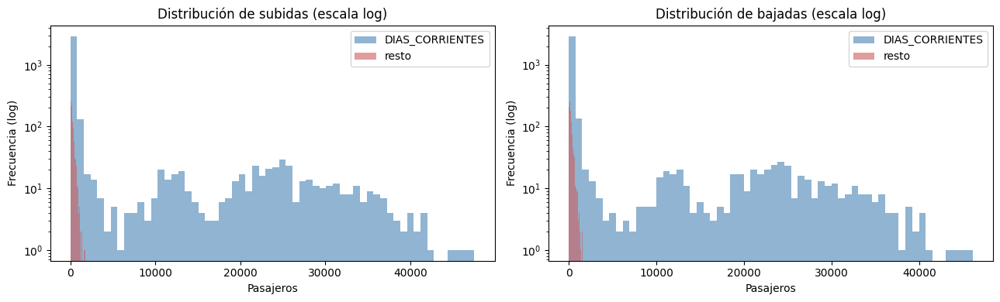

In [ ]:
# Escala log para ver ambas poblaciones en el mismo eje: los dias
# corridos quedan dos ordenes de magnitud por encima, no fuera de rango.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, col in zip(axes, ['subidas', 'bajadas']):
    ax.hist(r1415[col], bins=60, color='steelblue', alpha=0.6,
            label='DIAS_CORRIENTES', log=True)
    ax.hist(COMPARABLE[col], bins=60, color='indianred', alpha=0.6,
            label='resto', log=True)
    ax.set_title(f'Distribución de {col} (escala log)')
    ax.set_xlabel('Pasajeros')
    ax.set_ylabel('Frecuencia (log)')
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Verificar segmentos disponibles para ruta 14 15
# (la variable de la consulta se llama sql_segmentos: antes se llamaba 'consulta' y pisaba la funcion consulta())
def consulta(query, params=None):
    with CONN.cursor() as cur:
        cur.execute(query, params)
        return pd.DataFrame(cur.fetchall(), columns=[d.name for d in cur.description])

sql_segmentos = """
SELECT
    nro_segmento,
    ROUND(longitud_m, 2) AS longitud_m,
    ST_SRID(geom_segmento) AS srid
FROM rutas_segmentos
WHERE idruta = 2
  AND geom_segmento IS NOT NULL
ORDER BY nro_segmento
"""

segmentos_r1415 = pd.read_sql(
    sql_segmentos,
    CONN
)

display(segmentos_r1415)

print("Segmentos encontrados:", len(segmentos_r1415))
print("SRID:", segmentos_r1415["srid"].unique())


/tmp/ipykernel_1374/293992684.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  segmentos_r1415 = pd.read_sql(


,nro_segmento,longitud_m,srid
0,1,500.00,4326
1,2,500.00,4326
2,3,500.00,4326
3,4,500.00,4326
4,5,500.00,4326
...,...,...,...
130,131,500.00,4326
131,132,500.00,4326
132,133,500.00,4326
133,134,500.00,4326


Segmentos encontrados: 135
SRID: [4326]


In [ ]:
# ================================================================
# GENERAR JSON DE PUNTOS Y CONTEXTO URBANO - ruta 14 15
# Esta version antigua de la celda se reemplazo: leia el panel de KRA 54 (data/panel_horario)
# y fallaba con "Puntos sin coordenadas". El ranking y el contexto de 14 15 los genera la
# celda siguiente ("COMPLETAR LOS 15 NODOS") y quedan en data/r1415/:
#   puntos_r1415_ranking.json  y  puntos_r1415_contexto.json
# ================================================================
import os
for _f in ('puntos_r1415_ranking.json', 'puntos_r1415_contexto.json'):
    _p = os.path.join(PROY, 'data', 'r1415', _f)
    print(('OK  ' if os.path.exists(_p) else 'FALTA'), _p)


OK   /content/drive/MyDrive/proyecto_sobusa/data/r1415/puntos_r1415_ranking.json
OK   /content/drive/MyDrive/proyecto_sobusa/data/r1415/puntos_r1415_contexto.json


In [ ]:
import glob
import pandas as pd
import os

archivos = sorted(
    glob.glob(os.path.join(PANEL_DIR, "panel_*.csv"))
)

nodos_historicos = set()

for archivo in archivos:
    temp = pd.read_csv(archivo, usecols=["idpunto"])
    nodos_historicos.update(temp["idpunto"].dropna().astype(int))

nodos_marzo = set(top15["idpunto"].astype(int))

print("Nodos en todo el histórico:", len(nodos_historicos))
print("IDs históricos:", sorted(nodos_historicos))
print("Nodos de marzo:", len(nodos_marzo))
print("Nodos ausentes en marzo:",
      sorted(nodos_historicos - nodos_marzo))

Nodos en todo el histórico: 14
IDs históricos: [2, 3, 4, 5, 6, 7, 8, 9, 11, 12, 13, 35, 127, 221]
Nodos de marzo: 15
Nodos ausentes en marzo: [6, 7, 8, 12]


In [ ]:
# ============================================================
# COMPLETAR LOS 15 NODOS DE ruta 14 15
# Incorporar al ranking y contexto los puntos del historico que faltan
# ============================================================

import os
import glob
import json
import time
import requests
import pandas as pd
from datetime import date

# ------------------------------------------------------------
# 1. CONFIGURACIÓN
# ------------------------------------------------------------

RUTA_ID = 2
DATA = os.path.join(PROY, "data", "r1415")
PANEL_DIR = os.path.join(DATA, "panel_horario")

ruta_ranking = os.path.join(DATA, "puntos_r1415_ranking.json")
ruta_contexto = os.path.join(DATA, "puntos_r1415_contexto.json")

# IDs de todo el historico del panel
IDS_HISTORICOS = set()
for _f in glob.glob(os.path.join(PANEL_DIR, "panel_*.csv")):
    IDS_HISTORICOS.update(
        pd.read_csv(_f, usecols=["idpunto"])["idpunto"].dropna().astype(int)
    )

# Recuperar conexión
CONN.rollback()

# ------------------------------------------------------------
# 2. CARGAR JSON EXISTENTES
# ------------------------------------------------------------

with open(ruta_ranking, encoding="utf-8") as f:
    rank_doc = json.load(f)

with open(ruta_contexto, encoding="utf-8") as f:
    ctx_doc = json.load(f)

# Obtener puntos actuales usando 'ranking' si existe, de lo contrario 'puntos'
puntos_lista = rank_doc.get("ranking", rank_doc.get("puntos", []))
ids_actuales = {int(p.get("idpunto", p.get("id_punto"))) for p in puntos_lista}
faltantes = sorted(IDS_HISTORICOS - ids_actuales)

print("Nodos actuales en JSON:", len(ids_actuales))
print("Puntos por incorporar:", faltantes)

# ------------------------------------------------------------
# 3. ENCONTRAR LOS MESES DE LOS PUNTOS FALTANTES
# ------------------------------------------------------------

archivos = sorted(glob.glob(os.path.join(PANEL_DIR, "panel_*.csv")))
meses_puntos = {}
for archivo in archivos:
    if len(meses_puntos) == len(faltantes):
        break
    temp = pd.read_csv(archivo, usecols=["idpunto"])
    ids_mes = set(temp["idpunto"].dropna().astype(int))
    mes = os.path.basename(archivo)[6:12]
    for pid in faltantes:
        if pid not in meses_puntos and pid in ids_mes:
            meses_puntos[pid] = mes

print("Meses seleccionados:", meses_puntos)

# ------------------------------------------------------------
# 4. RECUPERAR COORDENADAS GPS DESDE LA BASE DE DATOS
# ------------------------------------------------------------

consulta_gps = """
    SELECT d.latitud, d.longitud
    FROM progvehiculos p
    JOIN conteo_pasajeros_destino d ON p.idprogramacion = d.idprogramacion
    WHERE p.idruta = %s
      AND p.fechasalida >= %s
      AND p.fechasalida < %s
      AND d.idpunto = %s
      AND d.latitud BETWEEN 10 AND 12
      AND d.longitud BETWEEN -76 AND -74
    LIMIT 200
"""

coordenadas = {}
for pid in faltantes:
    mes = meses_puntos[pid]
    anio = int(mes[:4])
    numero_mes = int(mes[4:])
    inicio = date(anio, numero_mes, 1)
    fin = date(anio, numero_mes + 1, 1) if numero_mes < 12 else date(anio + 1, 1, 1)

    print(f"\nConsultando punto {pid} | Mes: {mes}")
    with CONN.cursor() as cur:
        cur.execute(consulta_gps, (RUTA_ID, inicio, fin, pid))
        filas = cur.fetchall()

    if not filas:
        raise ValueError(f"No se encontraron coordenadas para el punto {pid}")

    gps = pd.DataFrame(filas, columns=["lat", "lon"])
    lat = float(gps["lat"].median())
    lon = float(gps["lon"].median())
    coordenadas[pid] = (lat, lon, len(gps))
    print(f"Registros GPS: {len(gps)} | Lat: {lat:.6f} | Lon: {lon:.6f}")

# ------------------------------------------------------------
# 5. ASIGNAR SEGMENTO MÁS CERCANO
# ------------------------------------------------------------

consulta_segmento = """
    WITH punto AS (
        SELECT ST_Transform(ST_SetSRID(ST_MakePoint(%s, %s), 4326), 32619) AS geom
    )
    SELECT r.nro_segmento, ST_Distance(ST_Transform(r.geom_segmento, 32619), punto.geom) AS distancia_m
    FROM rutas_segmentos r
    CROSS JOIN punto
    WHERE r.idruta = %s AND r.geom_segmento IS NOT NULL
    ORDER BY distancia_m LIMIT 1
"""

nuevos_nodos = []
nuevos_contextos = []

session = requests.Session()
session.headers.update({"User-Agent": "SOBUSA-r1415-research/1.0 (academic project)"})

for pid in faltantes:
    lat, lon, registros = coordenadas[pid]
    with CONN.cursor() as cur:
        cur.execute(consulta_segmento, (lon, lat, RUTA_ID))
        resultado = cur.fetchone()

    if resultado is None:
        raise ValueError(f"No se encontró segmento para el punto {pid}")

    segmento, distancia = resultado
    print(f"\nPunto {pid} -> Segmento cercano: {segmento} (distancia: {distancia:.2f} m)")

    if distancia > 1000:
        raise ValueError(f"El punto {pid} está muy alejado de la ruta ({distancia:.1f} m)")

    # Crear nodo para ranking (marzo de 2025: sin demanda)
    nuevo_nodo = {
        "rank": 0,
        "idpunto": int(pid),
        "seg_aprox": int(segmento),
        "lat": round(lat, 6),
        "lon": round(lon, 6),
        "subidas": 0,
        "bajadas": 0,
        "total": 0,
        "lecturas": int(registros),
        "pct_total": 0.0
    }
    nuevos_nodos.append(nuevo_nodo)

    # ------------------------------------------------------------
    # 6. OBTENER CONTEXTO CON OSM
    # ------------------------------------------------------------
    direccion = None
    try:
        r = session.get("https://nominatim.openstreetmap.org/reverse", params={
            "lat": lat, "lon": lon, "format": "jsonv2", "zoom": 18
        }, timeout=30)
        r.raise_for_status()
        direccion = r.json().get("display_name")
    except Exception as e:
        print(f"Error Nominatim para {pid}: {e}")
    time.sleep(1.2)

    cercanos = []
    consulta_osm = f"""
    [out:json][timeout:30];
    (
      nwr(around:400,{lat},{lon})["name"]["amenity"];
      nwr(around:400,{lat},{lon})["name"]["shop"];
      nwr(around:400,{lat},{lon})["name"]["tourism"];
    );
    out center;
    """
    try:
        r = session.post("https://overpass.kumi.systems/api/interpreter", data={"data": consulta_osm}, timeout=60)
        r.raise_for_status()

        from math import radians, sin, cos, asin, sqrt
        def distancia_m(a, b, c, d):
            R = 6371000
            x = radians(c - a)
            y = radians(d - b)
            h = sin(x / 2)**2 + cos(radians(a)) * cos(radians(c)) * sin(y / 2)**2
            return 2 * R * asin(min(1, sqrt(h)))

        for elemento in r.json().get("elements", []):
            tags = elemento.get("tags", {})
            centro = elemento.get("center", elemento)
            if "lat" not in centro or "lon" not in centro: continue
            tipo = tags.get("amenity") or tags.get("shop") or tags.get("tourism")
            cercanos.append({
                "nombre": tags["name"],
                "tipo": tipo,
                "distancia_m": round(distancia_m(lat, lon, centro["lat"], centro["lon"]))
            })
        cercanos.sort(key=lambda x: x["distancia_m"])
    except Exception as e:
        print(f"Error Overpass para {pid}: {e}")
    time.sleep(1.0)

    destacado = cercanos[0] if cercanos else None
    nuevos_contextos.append({
        "idpunto": int(pid),
        "contexto": {"direccion": direccion},
        "cercanos": cercanos,
        "destacado": destacado
    })

# ------------------------------------------------------------
# 7. GUARDAR JSON ACTUALIZADOS
# ------------------------------------------------------------

# Agregar nuevos nodos al ranking
puntos_lista.extend(nuevos_nodos)
if "ranking" in rank_doc:
    rank_doc["ranking"] = puntos_lista
else:
    rank_doc["puntos"] = puntos_lista
rank_doc["total_puntos"] = len(puntos_lista)

# Agregar contextos
ctx_doc["contexto"].extend(nuevos_contextos)

with open(ruta_ranking, "w", encoding="utf-8") as f:
    json.dump(rank_doc, f, ensure_ascii=False, indent=2)

with open(ruta_contexto, "w", encoding="utf-8") as f:
    json.dump(ctx_doc, f, ensure_ascii=False, indent=2)

print(f"\n¡Completado! Se guardaron {len(puntos_lista)} puntos en total en el ranking.")

Nodos actuales en JSON: 14
Puntos por incorporar: []
Meses seleccionados: {}

¡Completado! Se guardaron 14 puntos en total en el ranking.


## 2.2 Puntos importantes y contexto urbano — Ruta 14-15

Se visualizan **14 puntos históricos** de la ruta 14-15, obtenidos de los archivos `puntos_r1415_ranking.json` y `puntos_r1415_contexto.json`. El ranking corresponde al volumen asociado a `idpunto` en **marzo de 2025**, con **285.631 movimientos** registrados en estos puntos.

Los puntos se representan sobre un trazado compuesto por **135 segmentos** de aproximadamente 500 m. El tamaño de los marcadores refleja el volumen asociado a cada punto; su referencia urbana procede de las direcciones y lugares destacados guardados en los JSON.

**Cobertura del contexto:** los **14 puntos** tienen dirección y un lugar destacado en el archivo. La ausencia de eventos sin `idpunto` en este ranking **no significa que se haya contabilizado la totalidad de pasajeros de la ruta**; el modelo de demanda horaria de la sección 3.3 trata esa diferencia explícitamente.


In [ ]:
import json

# ============================================================================
# 7.0  Puntos de interes de 14 15: volumen + contexto urbano
#
# Volumen: conteo_pasajeros_destino (marzo 2025).
# Contexto: OpenStreetMap -> direccion por Nominatim (geocodificacion inversa)
#           y lugar cercano por Overpass API en un radio de 400 m.
#
# Cada punto trae su direccion y su lugar cercano desde los JSON de 14 15.
#
# La cobertura depende de lo que OSM tenga mapeado en Barranquilla.
# 'sin lugar destacado' = ningun elemento con nombre propio dentro del radio;
# no significa que el punto sea irrelevante.
#
# OJO: la variable se llama `nodos`, no `pts`.
# Usar `pts` aqui sobreescribiria cualquier dataframe con ese nombre.
# ============================================================================

ARCHIVO_RANKING = os.path.join(DATA, 'puntos_r1415_ranking.json')
ARCHIVO_CONTEXTO = os.path.join(DATA, 'puntos_r1415_contexto.json')
radio = 400
with open(ARCHIVO_RANKING, encoding='utf-8') as f:
    ranking = json.load(f)
with open(ARCHIVO_CONTEXTO, encoding='utf-8') as f:
    ctx = json.load(f)

# Unir volumen (ranking) con contexto urbano
por_id = {p['idpunto']: p for p in ctx['contexto']}
nodos = []
for p in ranking['ranking']:
    c = por_id.get(p['idpunto'], {})
    info = c.get('contexto', {})
    destacado = c.get('destacado')
    fila = dict(p)
    fila['direccion'] = info.get('direccion')
    fila['cercanos'] = c.get('cercanos', [])
    fila['destacado'] = destacado
    # Referencia legible: lugar cercano si existe; si no, la direccion
    fila['referencia'] = (
        '%s (%s) a %d m' % (destacado['nombre'], destacado['tipo'], destacado['distancia_m'])
        if destacado else (info.get('direccion') or 'sin referencia')
    )
    nodos.append(fila)

# Orden real de recorrido sobre la via
nodos.sort(key=lambda p: p['seg_aprox'])

print('Nodos:', len(nodos), '| Pasajeros:', f"{ranking['total_pasajeros_con_idpunto']:,}")
print('Con direccion:', sum(1 for p in nodos if p['direccion']),
      '| Con lugar destacado:', sum(1 for p in nodos if p['destacado']))
pd.DataFrame(nodos)[['idpunto', 'seg_aprox', 'total', 'direccion', 'referencia']].head()

Nodos: 14 | Pasajeros: 285,631
Con direccion: 14 | Con lugar destacado: 14


,idpunto,seg_aprox,total,direccion,referencia
0,13,21,8703,"Boulevard Simón Bolívar, Simón Bolívar, Barran...",IED del Barrio Simon Bolivar Sede 2 (colegio) ...
1,6,28,19664,"Carrera 14, La Victoria, Barranquilla",Clínica la Victoria (clínica) a 160 m
2,8,49,11355,"Calle 93, El Poblado, Barranquilla",Berlinas de la 93 (terminal de buses) a 109 m
3,127,67,10033,"Calle 21, Adelta de Char II, La Playa",Parque Adelita de Char Etapa 2 (park) a 114 m
4,9,71,31724,"Calle 14, Villa Norte, La Playa",IED Pies Descalzos y Centro Comunitario La Pla...


### Mapa con tamaño de punto proporcional al volumen

In [ ]:
# ============================================================================
# 7.1  Mapa de los puntos de interes sobre el trazado real de 14 15
# ============================================================================
# Trazado de la ruta ordenado por nro_segmento para respetar el sentido
# de la via. La columna de geometria es geom_segmento, no geom.
with CONN.cursor() as cur:
    cur.execute(
        "SELECT nro_segmento, longitud_m, ST_AsGeoJSON(geom_segmento) "
        "FROM rutas_segmentos "
        "WHERE idruta = %s AND geom_segmento IS NOT NULL "
        "ORDER BY nro_segmento",
        (RUTA_ID,)
    )
    segs = cur.fetchall()

# Un LayerGroup por rasgo: 'feat' es la forma corta en GeoJSON de folium
def linea(coords, **kw):
    return folium.FeatureGroup(name='feat').add_to(m).add_child(
        folium.PolyLine(coords, **kw))

trazado = []
for nro, largo, gj in segs:
    g = json.loads(gj)
    if g['type'] == 'LineString':
        # (lon, lat) -> (lat, lon)
        trazado.extend([(c[1], c[0]) for c in g['coordinates']])

# Decimar: el trazado trae cientos de miles de vertices; sin reducirlo el
# HTML pesa decenas de MB y el navegador se cuelga
trazado = trazado[::40] + [trazado[-1]]
print('Segmentos:', len(segs), '| vertices dibujados:', len(trazado))

# ---------------------------------------------------------------------------
# Teselas del fondo.
#
# OJO, dos trampas aqui, ambas costaron el mismo sintoma:
#
# 1. folium NO acepta url=... TileLayer espera el parametro 'tiles'. Si se pasa
#    url=, cae en **kwargs, 'tiles' conserva su valor por defecto
#    'OpenStreetMap' y el mapa termina pidiendo teselas de OSM aunque la
#    atribucion diga Esri. Se nota porque OSM devuelve el aviso de bloqueo.
# 2. No dejar el fondo en una variable de otra celda: Colab conserva variables
#    entre ejecuciones y un valor viejo de OpenStreetMap se reutiliza solo.
#
# Por eso la URL va escrita aqui y en el parametro correcto.
# ---------------------------------------------------------------------------
FONDOS = {
    'Esri callejero': {
        'tiles': ('https://server.arcgisonline.com/ArcGIS/rest/services/'
                'World_Street_Map/MapServer/tile/{z}/{y}/{x}'),
        'attr': 'Tiles &copy; Esri',
    },
    'Esri satelital': {
        'tiles': ('https://server.arcgisonline.com/ArcGIS/rest/services/'
                'World_Imagery/MapServer/tile/{z}/{y}/{x}'),
        'attr': 'Tiles &copy; Esri',
    },
}
FONDO = 'Esri callejero'
print('Fondo del mapa:', FONDO)
print('URL:', FONDOS[FONDO]['tiles'])

m = folium.Map(location=[nodos[0]['lat'], nodos[0]['lon']], zoom_start=12, tiles=None)
folium.TileLayer(**FONDOS[FONDO], name=FONDO).add_to(m)
linea(trazado, color='#0033cc', weight=5, opacity=0.8, tooltip='14 15 (ruta %s)' % RUTA_ID)

# Radio y opacidad escalan con el volumen: el paso 1 (21.926 pasajeros) se lee
# de un vistazo y los puntos bajos quedan como contexto del recorrido
mx = max(p['total'] for p in nodos)
for p in nodos:
    radio_px = 6 + 26 * (p['total'] / mx) ** 0.6
    # Popup: volumen + que representa el punto
    html = (
        f"<b>Punto {p['rank']}</b><br>"
        f"idpunto {p['idpunto']} &middot; segmento ~{p['seg_aprox']}<br>"
        f"Subidas {p['subidas']:,} &middot; Bajadas {p['bajadas']:,}<br>"
        f"<b>Total {p['total']:,}</b> ({p['pct_total']}% del total)<br>"
        f"<hr>{p['referencia']}"
    )
    folium.CircleMarker(
        location=[p['lat'], p['lon']], radius=radio_px,
        color='#cc0000', weight=2, fill=True, fill_color='#ff6666',
        fill_opacity=min(0.35 + 0.5 * p['total'] / mx, 0.95),
        tooltip=f"pt {p['rank']} | seg {p['seg_aprox']} | {p['total']:,} pas",
        popup=folium.Popup(html, max_width=300)
    ).add_to(m)

folium.LayerControl().add_to(m)
m.fit_bounds([[c[0], c[1]] for c in trazado])

# fit_bounds() devuelve None, asi que hay que guardarlo aparte:
ARCHIVO_MAPA = os.path.join(DATA, 'mapa_r1415_puntos.html')
m.save(ARCHIVO_MAPA)
print('Mapa guardado en', ARCHIVO_MAPA,
      f'({os.path.getsize(ARCHIVO_MAPA)/1024:.0f} KB)')

# Comprobacion: si esto falla, el mapa pidio teselas a OSM y va a salir el
# aviso de bloqueo en lugar del fondo de la ciudad.
_html = open(ARCHIVO_MAPA, encoding='utf-8').read()
assert 'tile.openstreetmap.org' not in _html, 'El mapa esta pidiendo teselas a OSM'
print('OK: sin teselas de OpenStreetMap')

# Última expresión = el mapa. Sin esto Colab no muestra nada, porque
# fit_bounds() y save() devuelven None.
m

Segmentos: 135 | vertices dibujados: 8441
Fondo del mapa: Esri callejero
URL: https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}
Mapa guardado en /content/drive/MyDrive/proyecto_sobusa/data/r1415/mapa_r1415_puntos.html (543 KB)
OK: sin teselas de OpenStreetMap


### Orden de recorrido y movimientos por punto — marzo de 2025

Orden de recorrido por la ruta:
 seg_aprox  idpunto  total  subidas  bajadas  pct_total                                                         referencia
        21       13   8703     1430     7273       3.05              IED del Barrio Simon Bolivar Sede 2 (colegio) a 105 m
        28        6  19664     9304    10360       6.88                              Clínica la Victoria (clínica) a 160 m
        49        8  11355     5154     6201       3.98                      Berlinas de la 93 (terminal de buses) a 109 m
        67      127  10033     5351     4682       3.51                      Parque Adelita de Char Etapa 2 (park) a 114 m
        71        9  31724    16486    15238      11.11 IED Pies Descalzos y Centro Comunitario La Playa (colegio) a 208 m
        75       35  43790    26177    17613      15.33           Fundación Universitaria San Martin (universidad) a 129 m
        84       11  13197    10064     3133       4.62                               Hotel Movich Buró 51 

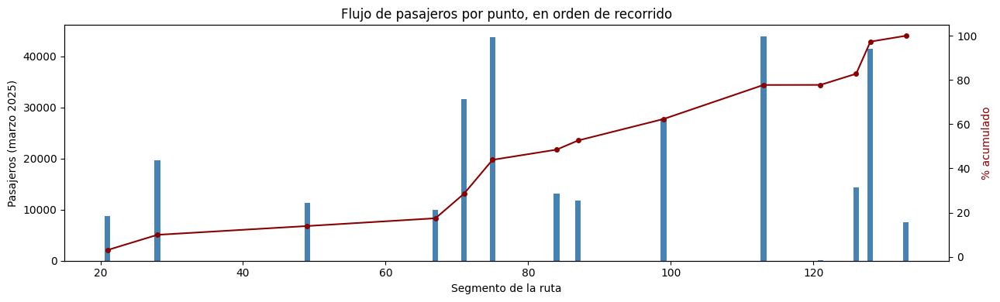

In [ ]:
# Orden de recorrido: el volumen concentrado al inicio del recorrido es la
# senal clasica de que el corredor actsua como alimentador hacia el centro
orden = pd.DataFrame(nodos).sort_values('seg_aprox').reset_index(drop=True)
print('Orden de recorrido por la ruta:')
print(orden[['seg_aprox', 'idpunto', 'total', 'subidas', 'bajadas',
              'pct_total', 'referencia']].to_string(index=False))

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(orden['seg_aprox'], orden['total'], color='steelblue')
ax.set_xlabel('Segmento de la ruta')
ax.set_ylabel('Pasajeros (marzo 2025)')
ax.set_title('Flujo de pasajeros por punto, en orden de recorrido')
ax2 = ax.twinx()
acum = orden['total'].cumsum() / orden['total'].sum() * 100
ax2.plot(orden['seg_aprox'], acum, color='darkred', marker='o', ms=4)
ax2.set_ylabel('% acumulado', color='darkred')
ax2.grid(False)
plt.tight_layout()
plt.show()

### Grafico de Subidas vs Bajadas por punto

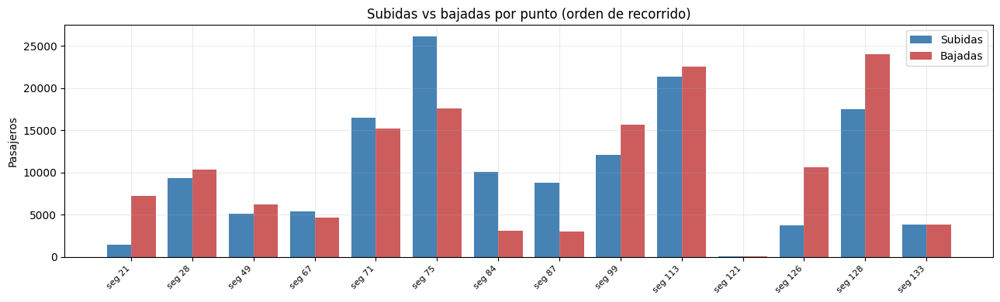

In [ ]:
# Asegurar que la variable 'orden' esté disponible de forma robusta
if 'orden' not in globals():
    import pandas as pd
    import os
    import json

    # Reconstruimos nodos localmente si no existe
    if 'nodos' not in globals() or len(nodos) == 0:
        try:
            with open(os.path.join(DATA, 'puntos_r1415_ranking.json'), encoding='utf-8') as f:
                ranking_data = json.load(f)
            with open(os.path.join(DATA, 'puntos_r1415_contexto.json'), encoding='utf-8') as f:
                ctx_data = json.load(f)

            por_id = {p['idpunto']: p for p in ctx_data['contexto']}
            puntos_lista = ranking_data.get('ranking', ranking_data.get('puntos', []))

            nodos_local = []
            for p in puntos_lista:
                pid = p.get('idpunto', p.get('id_punto'))
                c = por_id.get(pid, {})
                info = c.get('contexto', {})
                destacado = c.get('destacado')
                fila = dict(p)
                fila['idpunto'] = pid
                fila['direccion'] = info.get('direccion')
                fila['destacado'] = destacado

                # Recuperar subidas, bajadas y total de forma robusta (raíz o dentro de 'extras')
                extras = p.get('extras', {})
                fila['subidas'] = int(p.get('subidas', extras.get('subidas', 0)))
                fila['bajadas'] = int(p.get('bajadas', extras.get('bajadas', 0)))
                fila['total'] = int(p.get('total', extras.get('total', 0)))
                fila['pct_total'] = float(p.get('pct_total', extras.get('pct_total', 0.0)))

                # Recuperar seg_aprox desde el contexto si no está en el ranking directamente
                fila['seg_aprox'] = p.get('seg_aprox', c.get('seg_aprox', p.get('orden', 0)))

                fila['referencia'] = (
                    '%s (%s) a %d m' % (destacado['nombre'], destacado['tipo'], destacado['distancia_m'])
                    if destacado else (info.get('direccion') or 'sin referencia')
                )
                nodos_local.append(fila)

            nodos = nodos_local
        except Exception as e:
            print("No se pudo inicializar la lista de nodos:", e)
            nodos = []

    if len(nodos) > 0:
        # Asegurar que todas las filas tengan seg_aprox para evitar KeyError al ordenar
        for n in nodos:
            if 'seg_aprox' not in n:
                n['seg_aprox'] = n.get('orden', 0)
            if 'subidas' not in n:
                extras = n.get('extras', {})
                n['subidas'] = int(n.get('subidas', extras.get('subidas', 0)))
                n['bajadas'] = int(n.get('bajadas', extras.get('bajadas', 0)))
        orden = pd.DataFrame(nodos).sort_values('seg_aprox').reset_index(drop=True)
    else:
        raise NameError("No se pudo definir 'orden' porque no hay datos de nodos disponibles.")

# Subidas vs bajadas: el balance indica si el punto es generador de viaje o punto de descenso
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(13, 4))
pos = range(len(orden))
ax.bar([i - 0.2 for i in pos], orden['subidas'], width=0.4,
        label='Subidas', color='steelblue')
ax.bar([i + 0.2 for i in pos], orden['bajadas'], width=0.4,
        label='Bajadas', color='indianred')
ax.set_xticks(list(pos))
ax.set_xticklabels(['seg ' + str(s) for s in orden['seg_aprox']],
                   fontsize=8, rotation=45, ha='right')
ax.set_ylabel('Pasajeros')
ax.set_title('Subidas vs bajadas por punto (orden de recorrido)')
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Tabla resumen del grafo

In [ ]:
largo_km = sum(s[1] for s in segs) / 1000
total_pas = sum(p['total'] for p in nodos)
con_destacado = [p for p in nodos if p['destacado']]
educacion = [p for p in con_destacado
             if p['destacado']['tipo'] in ('universidad', 'educación superior',
                                         'colegio', 'centro comunitario')]

print('Resumen de los puntos de interes de 14 15')
print('  nodos                :', len(nodos))
print('  aristas (lineales)   :', len(nodos) - 1)
print('  longitud de la ruta  : %.1f km en %d segmentos' % (largo_km, len(segs)))
print('  pasajeros totales    :', f'{total_pas:,}')
print('  top 10 concentra     : %.1f%%' % (
      sum(p['total'] for p in sorted(nodos, key=lambda x: -x['total'])[:10]) /
      total_pas * 100))
print('  con direccion        :', sum(1 for p in nodos if p['direccion']), '/', len(nodos))
print('  con lugar destacado  :', len(con_destacado), '/', len(nodos))
print('  con educacion a <=%dm:' % radio, len(educacion))

print()
for i, p in enumerate(nodos, 1):
    print(f"{i:2d}. seg {p['seg_aprox']:>4} | {p['total']:>6,} pas | {p['referencia']}")

Resumen de los puntos de interes de 14 15
  nodos                : 14
  aristas (lineales)   : 13
  longitud de la ruta  : 67.2 km en 135 segmentos
  pasajeros totales    : 285,631
  top 10 concentra     : 90.7%
  con direccion        : 14 / 14
  con lugar destacado  : 14 / 14
  con educacion a <=400m: 4

 1. seg   21 |  8,703 pas | IED del Barrio Simon Bolivar Sede 2 (colegio) a 105 m
 2. seg   28 | 19,664 pas | Clínica la Victoria (clínica) a 160 m
 3. seg   49 | 11,355 pas | Berlinas de la 93 (terminal de buses) a 109 m
 4. seg   67 | 10,033 pas | Parque Adelita de Char Etapa 2 (park) a 114 m
 5. seg   71 | 31,724 pas | IED Pies Descalzos y Centro Comunitario La Playa (colegio) a 208 m
 6. seg   75 | 43,790 pas | Fundación Universitaria San Martin (universidad) a 129 m
 7. seg   84 | 13,197 pas | Hotel Movich Buró 51 (hotel) a 179 m
 8. seg   87 | 11,798 pas | San Miguel Arcangel Clínica (clínica) a 48 m
 9. seg   99 | 27,790 pas | IED - Para el Desarrollo del Talento Humano (colegi

## 2.3 Grafo de la ruta 14-15

El grafo ordena los **14 puntos** a lo largo del recorrido y los conecta mediante **13 aristas** consecutivas. La geometría de la ruta contiene **135 segmentos** y una longitud aproximada de **67,5 km** según el archivo del grafo. Las distancias entre nodos se miden siguiendo el recorrido, no en línea recta.


In [ ]:
import json

# ============================================================================
# 8.1  Grafo de 14 15: nodos, aristas y distancias reales
#
# Los nodos son los puntos de mayor volumen y forman una CADENA LINEAL:
# todos estan sobre el mismo corredor, asi que el grafo es una ruta, no una
# malla. N nodos -> N-1 aristas.
#
# Cada nodo trae idpunto, posicion sobre la via, volumen y referencia urbana (grafo_r1415.json).
#
# Decisiones importantes:
#
# - Las distancias se miden SOBRE LA VIA, no en linea recta. Se usa
#   ST_LineSubsubstring sobre la ruta completa proyectada a EPSG:32619
#   (UTM 19N). Sin proyectar, ST_Length devuelve ~0.6 'metros' que en
#   realidad son 0.6 grados, porque la geometria esta en SRID 4326.
#
# - El orden de recorrido sale de la POSICION sobre la cadena de
#   segmentos (nro_segmento), no del 'segmento mas cercano'. Donde la ruta
#   recorre dos veces la misma calle el emparejamiento por cercanía es
#   ambiguo y dio 6 de 15 nodos equivocados.
#
# - El grafo es NO DIRIGIDO: conteo_pasajeros_destino agrega subidas y
#   bajadas de ambos sentidos, no son flujos separados.
#
# - NO hay tiempos de viaje en la base. tiempo_min usa una velocidad de
#   referencia de 20 km/h: es una estimacion, no un dato medido.
# ============================================================================
ARCHIVO_GRAFO = os.path.join(DATA, 'grafo_r1415.json')

with open(ARCHIVO_GRAFO, encoding='utf-8') as f:
    grafo = json.load(f)

df_grafo = pd.DataFrame(grafo['nodos'])
print('Nodos   :', grafo['n_nodos'])
print('Aristas :', grafo['n_aristas'])
print('Longitud: %.2f km' % grafo['longitud_ruta_km'])
print('Pasajeros: %s' % f"{grafo['total_pasajeros']:,}")
print()
print(df_grafo[['orden_recorrido', 'idpunto', 'posicion_en_ruta_m',
                 'seg_cadena', 'total', 'subidas', 'bajadas',
                 'referencia']].to_string(index=False))

Nodos   : 14
Aristas : 13
Longitud: 67.53 km
Pasajeros: 285,631

 orden_recorrido  idpunto  posicion_en_ruta_m  seg_cadena  total  subidas  bajadas                                                         referencia
               1      221              3339.9           7  41537    17543    23994                      C.C. Plaza Macondo (centro comercial) a 196 m
               2       13             10336.9          21   8703     1430     7273              IED del Barrio Simon Bolivar Sede 2 (colegio) a 105 m
               3        6             13597.3          28  19664     9304    10360                              Clínica la Victoria (clínica) a 160 m
               4        8             24283.2          49  11355     5154     6201                      Berlinas de la 93 (terminal de buses) a 109 m
               5      127             33412.7          67  10033     5351     4682                      Parque Adelita de Char Etapa 2 (park) a 114 m
               6        9          

### Distancias de las 13 aristas

La suma de las distancias entre nodos consecutivos es de **63,03 km**. La arista más larga une `p6` con `p8` (**10,69 km**), mientras que la más corta une `p11` con `p12` (**1,61 km**). El grafo describe los puntos seleccionados y no presupone que existan paradas registradas en todos los tramos intermedios.


In [ ]:
# --- 8.2  Aristas: distancias entre nodos consecutivos -----------------
df_aristas = pd.DataFrame(grafo['aristas'])

print('Longitud de cada arista:')
print(df_aristas.to_string(index=False))
print()
print('Total aristas : %.2f km' % (df_aristas['distancia_m'].sum() / 1000))
print('Arista mas larga : %.2f km (%s -> %s)' % (
    df_aristas['distancia_m'].max() / 1000,
    df_aristas.loc[df_aristas['distancia_m'].idxmax(), 'origen'],
    df_aristas.loc[df_aristas['distancia_m'].idxmax(), 'destino']))
print('Arista mas corta: %.0f m (%s -> %s)' % (
    df_aristas['distancia_m'].min(),
    df_aristas.loc[df_aristas['distancia_m'].idxmin(), 'origen'],
    df_aristas.loc[df_aristas['distancia_m'].idxmin(), 'destino']))
print('Mediana        : %.0f m' % df_aristas['distancia_m'].median())
print()
print('Nota: %d de las %d aristas superan 5 km. Entre nodos consecutivos'
      % ((df_aristas['distancia_m'] > 5000).sum(), len(df_aristas)))
print('hay tramos sin ningun punto de conteo conboarding alto. Si el modelo')
print('los necesita como variables de entrada, habra que discretizar la via.')

Longitud de cada arista:
origen destino  distancia_m  distancia_km  tiempo_min
  p221     p13       6997.0         6.997        21.0
   p13      p6       3260.4         3.260         9.8
    p6      p8      10685.9        10.686        32.1
    p8    p127       9129.5         9.129        27.4
  p127      p9       1945.0         1.945         5.8
    p9     p35       1822.0         1.822         5.5
   p35     p11       4636.2         4.636        13.9
   p11     p12       1606.8         1.607         4.8
   p12      p7       5864.0         5.864        17.6
    p7      p5       7276.9         7.277        21.8
    p5      p4       3803.4         3.803        11.4
    p4      p3       2577.0         2.577         7.7
    p3      p2       3427.6         3.428        10.3

Total aristas : 63.03 km
Arista mas larga : 10.69 km (p6 -> p8)
Arista mas corta: 1607 m (p11 -> p12)
Mediana        : 3803 m

Nota: 5 de las 13 aristas superan 5 km. Entre nodos consecutivos
hay tramos sin ningun punt

### Estructura del grafo

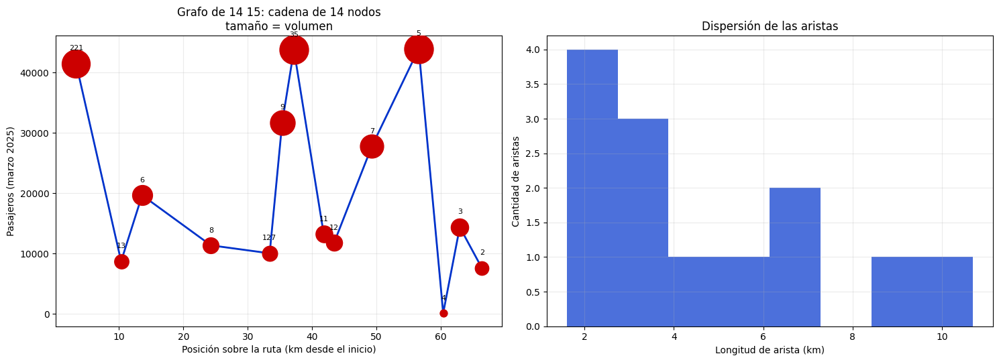

In [ ]:
# --- 8.3  Estructura del grafo -----------------------------------------
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# (a) cadena: nodos sobre la via, tamano = pasajeros
ax = axes[0]
ax.plot([n['posicion_en_ruta_m'] / 1000 for n in grafo['nodos']],
        [n['total'] for n in grafo['nodos']],
        color='lightgray', zorder=1)
for a, b in zip(grafo['nodos'], grafo['nodos'][1:]):
    ax.plot([a['posicion_en_ruta_m'] / 1000, b['posicion_en_ruta_m'] / 1000],
            [a['total'], b['total']],
            color='#0033cc', lw=2, zorder=2)
mx = max(n['total'] for n in grafo['nodos'])
for n in grafo['nodos']:
    ax.scatter(n['posicion_en_ruta_m'] / 1000, n['total'],
               s=60 + 900 * n['total'] / mx, color='#cc0000', zorder=3)
    ax.annotate(str(n['idpunto']),
                (n['posicion_en_ruta_m'] / 1000, n['total']),
                textcoords='offset points', xytext=(0, 14),
                ha='center', fontsize=8)
ax.set_xlabel('Posición sobre la ruta (km desde el inicio)')
ax.set_ylabel('Pasajeros (marzo 2025)')
ax.set_title('Grafo de 14 15: cadena de %d nodos\ntamaño = volumen' % len(grafo['nodos']))
ax.grid(alpha=0.25)

# (b) histograma de longitudes de arista
ax = axes[1]
ax.hist(df_aristas['distancia_m'] / 1000, bins=8, color='#0033cc', alpha=0.7)
ax.set_xlabel('Longitud de arista (km)')
ax.set_ylabel('Cantidad de aristas')
ax.set_title('Dispersión de las aristas')
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### El grafo sobre el mapa

In [ ]:
# --- 8.4  El grafo sobre el mapa ---------------------------------------
# Liberar transacciones abortadas previas si las hay
try:
    CONN.rollback()
except Exception:
    pass

# Las aristas van por la via real (geom_segmento), no en linea recta.
with CONN.cursor() as cur:
    cur.execute(
        "SELECT nro_segmento, ST_AsGeoJSON(geom_segmento) "
        "FROM rutas_segmentos "
        "WHERE idruta = %s AND geom_segmento IS NOT NULL "
        "ORDER BY nro_segmento",
        (RUTA_ID,)
    )
    segs_grafo = cur.fetchall()

lineas_arista = {}
for nro, gj in segs_grafo:
    g = json.loads(gj)
    if g['type'] == 'LineString':
        lineas_arista[nro] = [(c[1], c[0]) for c in g['coordinates']]

m_grafo = folium.Map(location=[grafo['nodos'][0]['lat'], grafo['nodos'][0]['lon']],
                     zoom_start=12, tiles=None)
folium.TileLayer(**FONDOS[FONDO], name=FONDO).add_to(m_grafo)

# Fondo del corredor en gris claro
_gris = folium.PolyLine(lineas_arista[grafo['nodos'][0]['seg_cadena']],
                        color='lightgray', weight=4)
_gris.add_to(m_grafo)

# Dibujar solo los tramos de via que unen nodos consecutivos: eso es el grafo
for e in grafo['aristas']:
    no = next(n for n in grafo['nodos'] if n['id'] == e['origen'])
    nd = next(n for n in grafo['nodos'] if n['id'] == e['destino'])
    tramo = []
    for nro in range(no['seg_cadena'], nd['seg_cadena'] + 1):
        tramo.extend(lineas_arista.get(nro, []))
    if tramo:
        folium.PolyLine(tramo, color='#0033cc', weight=6, opacity=0.9,
                        tooltip='%s - %s (%.2f km)'
                        % (e['origen'], e['destino'], e['distancia_km'])).add_to(m_grafo)

for n in grafo['nodos']:
    radio = 6 + 22 * (n['total'] / mx) ** 0.6
    html = (
        f"<b>Nodo {n['orden_recorrido']}</b><br>"
        f"idpunto {n['idpunto']} · segmento {n['seg_cadena']}<br>"
        f"posición {n['posicion_en_ruta_m']/1000:.2f} km<br>"
        f"Subidas {n['subidas']:,} · Bajadas {n['bajadas']:,}<br>"
        f"<b>Total {n['total']:,}</b> ({n['pct_total']}% del total)<hr>{n['referencia']}"
    )
    folium.CircleMarker(
        location=[n['lat_sobre_via'], n['lon_sobre_via']],
        radius=radio, color='#cc0000', weight=2, fill=True,
        fill_color='#ff6666', fill_opacity=0.8,
        tooltip='nodo %d | %s | %s pas'
        % (n['orden_recorrido'], n['idpunto'], f"{n['total']:,}"),
        popup=folium.Popup(html, max_width=300)).add_to(m_grafo)

folium.LayerControl().add_to(m_grafo)
m_grafo.fit_bounds([[c[0], c[1]] for c in trazado])
m_grafo

In [ ]:
ARCHIVO_MAPA_GRAFO = os.path.join(DATA, 'mapa_grafo_r1415.html')
m_grafo.save(ARCHIVO_MAPA_GRAFO)
print('Mapa del grafo guardado en', ARCHIVO_MAPA_GRAFO,
      f'({os.path.getsize(ARCHIVO_MAPA_GRAFO)/1024:.0f} KB)')

# Comprobacion: si falla, el mapa pide teselas a OSM y sale el aviso de bloqueo.
_h = open(ARCHIVO_MAPA_GRAFO, encoding='utf-8').read()
assert 'tile.openstreetmap.org' not in _h, 'El mapa pide teselas a OSM'
print('OK: sin teselas de OpenStreetMap')

m_grafo

Mapa del grafo guardado en /content/drive/MyDrive/proyecto_sobusa/data/r1415/mapa_grafo_r1415.html (10861 KB)
OK: sin teselas de OpenStreetMap


## 2.4 Fase 1: modelo inicial de demanda por nodo

Se estudian las **subidas por viaje** en cada uno de los **14 puntos** de la ruta 14-15. La exposición `viajes` permite distinguir entre el número de buses programados en una hora y los pasajeros que subieron en los puntos observados. En los GLM de referencia se utiliza `offset = log(viajes)`.

El panel de nodos abarca **enero–agosto de 2025**, pero solo contiene eventos asociados a los puntos seleccionados. Según la calibración que aparece más adelante, representa alrededor del **6,2 % de las subidas horarias totales** de la ruta en un día laborable; no es suficiente por sí solo para dimensionar la frecuencia de toda la operación.

La Fase 2 analiza por separado la demanda de ruta y la ocupación por segmentos. En la sección 3.3 se construye una serie horaria de ruta para alimentar el optimizador, diferenciando explícitamente medición y estimación.


In [ ]:
#Datos: panel horario y servicio
# Los CSV los genera scripts/extraer_panel_r1415.py y scripts/extraer_servicio_r1415.py.
# No se consulta la base desde aqui: 41 GB no caben en memoria de Colab y
# cada consulta mensual cuesta ~12 s en la RDS.
import glob

PANEL = os.path.join(DATA, 'panel_horario')

df = pd.concat([pd.read_csv(f, parse_dates=['dia'])
                for f in sorted(glob.glob(os.path.join(PANEL, 'panel_*.csv')))])
serv = pd.concat([pd.read_csv(f, parse_dates=['dia'])
                   for f in sorted(glob.glob(os.path.join(PANEL, 'servicio_*.csv')))])

print('panel  : %d celdas, %s dias, %d puntos, %s .. %s'
      % (len(df), df['dia'].nunique(), df['idpunto'].nunique(),
         df['dia'].min().date(), df['dia'].max().date()))
print('servicio: %d celdas, %d viajes' % (len(serv), serv['viajes'].sum()))
print()
print('Subidas por celda: media %.2f  mediana %.1f  max %d'
      % (df['subidas'].mean(), df['subidas'].median(), df['subidas'].max()))

# Cobertura: dias con datos por mes y año. Un hueco (mes con pocos dias) se ve aqui
# antes de que contamine los rezagos.
_cob = (df.assign(anio=df['dia'].dt.year, mes_=df['dia'].dt.month)
          .groupby(['mes_', 'anio'])['dia'].nunique().unstack('anio'))
print()
print('Dias con datos por mes y año:')
print(_cob.to_string())
print()
print('Nodos distintos por año (deben ser los mismos):')
print(df.groupby(df['dia'].dt.year)['idpunto'].nunique().to_string())
df.head()

panel  : 54240 celdas, 236 dias, 14 puntos, 2025-01-01 .. 2025-08-30
servicio: 4083 celdas, 31988 viajes

Subidas por celda: media 2.61  mediana 1.0  max 498

Dias con datos por mes y año:
anio  2025
mes_      
1       31
2       27
3       30
4       29
5       30
6       29
7       30
8       30

Nodos distintos por año (deben ser los mismos):
dia
2025    14


,dia,hora,idpunto,subidas,bajadas,eventos
0,2025-01-01,5,2,0,0,16
1,2025-01-01,5,3,0,0,3
2,2025-01-01,5,221,1,0,4
3,2025-01-01,6,2,0,0,49
4,2025-01-01,6,3,0,0,1


### 2.4.1 Limpieza de glitches de contador

In [ ]:
# --- 9.2  Limpieza: hay contadores que se desbordaron ------------------
# El panel puede traer filas con contadores desbordados (valores absurdos frente al
# p99.9 de una celda normal): no son outliers legitimos sino fallos del contador.
# Se eliminan por cutoff robusto
# por (idpunto, hora). Se reporta cuantas se quitan en vez de esconderlo.
LIMITE_P99 = 0.999
ANTES = df['subidas'].sum()

limite = df.groupby(['idpunto', 'hora'])['subidas'].transform(
    lambda s: max(s.quantile(LIMITE_P99) * 3, 20))
malo = (df['subidas'] > limite) | (df['bajadas'] > limite)
n_malo = int(malo.sum())
df = df[~malo].copy()

print('celdas eliminadas : %d de %d (%.2f%%)'
      % (n_malo, len(df) + n_malo, 100 * n_malo / (len(df) + n_malo)))
print('subidas %s -> %s' % (f'{ANTES:,}', f"{int(df['subidas'].sum()):,}"))
print('max por celda tras limpiar: %d' % df['subidas'].max())
print()
print('Sin esta limpieza el modelo aprenderia picos que son fallos del contador y no demanda.')
df['mes'] = df['dia'].dt.month

celdas eliminadas : 8 de 54240 (0.01%)
subidas 141,460 -> 141,421
max por celda tras limpiar: 498

Sin esta limpieza el modelo aprenderia picos que son fallos del contador y no demanda.


### 2.4.2 La exposición: pasajeros por viaje

In [ ]:
# --- 9.3  Exposicion: pasajeros por viaje ------------------------------
# El merge con el servicio es lo que hace posible distinguir dos cosas que
# se ven iguales en la tabla de conteos:
#   - 'llego un bus y nadie subio'  -> 0 real, debe entrar al panel
#   - 'no paso ningun bus'         -> no observado, NO debe entrar
df = df.merge(serv[['dia', 'hora', 'viajes']], on=['dia', 'hora'], how='inner')
df = df[df['viajes'] > 0].copy()

df['dow'] = df['dia'].dt.dayofweek
df['tipo_dia'] = np.where(df['dow'] >= 5, 'fin_de_semana', 'laborable')
df['sub_por_viaje'] = df['subidas'] / df['viajes']

grafo = json.load(open(os.path.join(DATA, 'grafo_r1415.json'), encoding='utf-8'))
info_nodo = {n['idpunto']: n for n in grafo['nodos']}
orden_nodos = [n['idpunto'] for n in grafo['nodos']]
df['pos_rel'] = df['idpunto'].map(
    {n['idpunto']: n['posicion_en_ruta_m'] / grafo['longitud_ruta_m'] for n in grafo['nodos']})

print('panel modelable: %d filas' % len(df))
print('  sub_por_viaje  media %.2f  mediana %.2f  max %.1f'
      % (df['sub_por_viaje'].mean(), df['sub_por_viaje'].median(), df['sub_por_viaje'].max()))
print()
print('viajes por hora y dia: media %.1f  min %d  max %d'
      % (serv['viajes'].mean(), serv['viajes'].min(), serv['viajes'].max()))
print()
print('ATENCION: el objetivo es por VIAJE. Para convertirlo a pasajeros por hora se multiplica')
print('por los viajes HISTORICOS de esa hora, nunca por los que se propongan: la demanda de una')
print('hora no crece porque se pongan mas buses. La demanda de ruta que consume el optimizador')
print('sale del modelo de la seccion 3.3, no de este.')

panel modelable: 47591 filas
  sub_por_viaje  media 0.42  mediana 0.22  max 71.1

viajes por hora y dia: media 7.8  min 1  max 31

ATENCION: el objetivo es por VIAJE. Para convertirlo a pasajeros por hora se multiplica
por los viajes HISTORICOS de esa hora, nunca por los que se propongan: la demanda de una
hora no crece porque se pongan mas buses. La demanda de ruta que consume el optimizador
sale del modelo de la seccion 3.3, no de este.


### 2.4.3 Partición temporal de entrenamiento y prueba

Se utiliza el **1 de julio de 2025** como fecha de corte: entrenamiento con observaciones de enero a junio y prueba con julio y agosto de 2025. No se realiza una partición aleatoria, porque permitiría mezclar información futura con el pasado.


In [ ]:
# --- 9.4  Division temporal (no aleatoria) ---------------------------
# Una particion aleatoria mezcla el futuro con el pasado y devuelve metricas
# infladas; el objetivo es predecir el futuro.
#
# CAMBIO: antes se separaba por MES (MESES_TEST = [7, 8]). Con 2023-2025 en el
# panel eso mandaba a test los jul-ago de 2023, 2024 y 2025 a la vez y dejaba a
# train sin esos meses. Ahora se separa por FECHA: todo lo anterior a
# FECHA_TEST_INI es train y todo lo posterior es test.
FECHA_TEST_INI = pd.Timestamp('2025-07-01')
df['es_test'] = df['dia'] >= FECHA_TEST_INI
tr = df[~df['es_test']].copy()
te = df[df['es_test']].copy()

# La media historica se calcula SOLO con train. Si usara todo el panel,
# el modelo veria su propio futuro.
media_tr = (tr.groupby(['idpunto', 'hora', 'tipo_dia'])['sub_por_viaje']
             .mean().rename('media_hist'))
tr = tr.merge(media_tr, on=['idpunto', 'hora', 'tipo_dia'], how='left')
te = te.merge(media_tr, on=['idpunto', 'hora', 'tipo_dia'], how='left')

# Combinaciones que no estaban en train caen a la media global de train,
# no a cero: cero significa 'sin demanda', no 'sin informacion'.
te['media_hist'] = te['media_hist'].fillna(tr['sub_por_viaje'].mean())

print('train (%s .. %s): %d filas' % (tr['dia'].min().date(), tr['dia'].max().date(), len(tr)))
print('test  (%s .. %s): %d filas' % (te['dia'].min().date(), te['dia'].max().date(), len(te)))
print()
print('train mean %.3f | test mean %.3f' % (tr['sub_por_viaje'].mean(), te['sub_por_viaje'].mean()))


train (2025-01-01 .. 2025-06-29): 35385 filas
test  (2025-07-01 .. 2025-08-30): 12206 filas

train mean 0.432 | test mean 0.370


### 2.4.3.1 Distribución del conteo

Antes de elegir la familia del modelo se revisa cómo se distribuye `subidas` por celda (nodo, día, hora) en train: asimetría, ceros y sobredispersión respecto a Poisson.

In [ ]:
!pip install -q statsmodels

Observaciones          : 35385
Media / mediana        : 2.97 / 2.0
Varianza               : 22.90
Varianza / media       : 7.72   (Poisson = 1)
Asimetría              : 33.09
Percentiles 90/99/99.9 : [7.0, 19.0, 33.0]
Ceros                  : 10417 (29.4%)


/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)



Dispersión de Pearson (Poisson con offset): 8.33
Ceros observados vs esperados bajo Poisson: 10417 vs 7225
Grupos usados: 1321 | mediana de varianza/media: 1.43


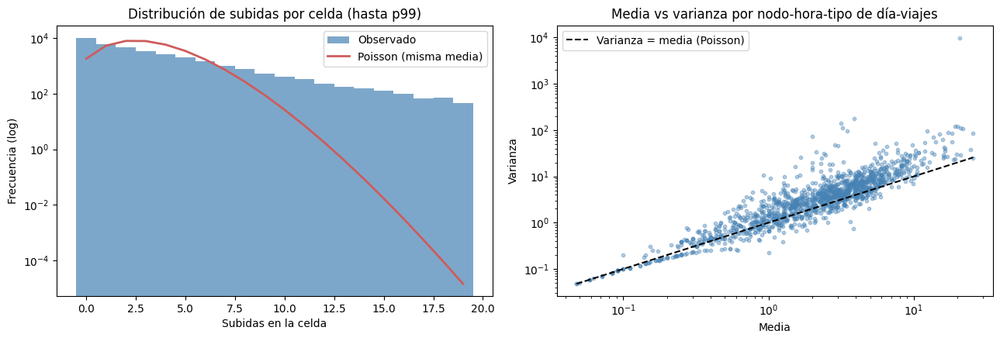

In [ ]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
import matplotlib.pyplot as plt
import numpy as np

y = tr['subidas']
p99 = int(y.quantile(0.99))

print('Observaciones          : %d' % len(y))
print('Media / mediana        : %.2f / %.1f' % (y.mean(), y.median()))
print('Varianza               : %.2f' % y.var())
print('Varianza / media       : %.2f   (Poisson = 1)' % (y.var() / y.mean()))
print('Asimetría              : %.2f' % y.skew())
print('Percentiles 90/99/99.9 : %s' % y.quantile([.9, .99, .999]).round(1).tolist())
print('Ceros                  : %d (%.1f%%)' % ((y == 0).sum(), 100 * (y == 0).mean()))

# Sobredispersión condicional: Poisson con exposición, Pearson chi2 / gl (Poisson = 1)
glm_disp = smf.glm('subidas ~ C(hora) * C(tipo_dia) + C(idpunto)', data=tr,
                   family=sm.families.Poisson(),
                   offset=np.log(tr['viajes'])).fit()
disp = glm_disp.pearson_chi2 / glm_disp.df_resid
ceros_esp = np.exp(-glm_disp.fittedvalues).sum()
print()
print('Dispersión de Pearson (Poisson con offset): %.2f' % disp)
print('Ceros observados vs esperados bajo Poisson: %d vs %.0f' % ((y == 0).sum(), ceros_esp))

# Media vs varianza por grupo con la misma exposición
g = (tr.groupby(['idpunto', 'hora', 'tipo_dia', 'viajes'])['subidas']
       .agg(media='mean', varianza='var', n='size').reset_index())
g = g[(g['n'] >= 10) & (g['media'] > 0) & (g['varianza'] > 0)]
print('Grupos usados: %d | mediana de varianza/media: %.2f'
      % (len(g), (g['varianza'] / g['media']).median()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
k = np.arange(0, p99 + 1)
ax.hist(y[y <= p99], bins=np.arange(0, p99 + 2) - 0.5,
        color='steelblue', alpha=0.7, label='Observado')
ax.plot(k, stats.poisson.pmf(k, y.mean()) * len(y),
        color='indianred', lw=2, label='Poisson (misma media)')
ax.set_yscale('log')
ax.set_title('Distribución de subidas por celda (hasta p99)')
ax.set_xlabel('Subidas en la celda')
ax.set_ylabel('Frecuencia (log)')
ax.legend()

ax = axes[1]
ax.scatter(g['media'], g['varianza'], s=10, alpha=0.4, color='steelblue')
lim = [g['media'].min(), g['media'].max()]
ax.plot(lim, lim, 'k--', label='Varianza = media (Poisson)')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_title('Media vs varianza por nodo-hora-tipo de día-viajes')
ax.set_xlabel('Media'); ax.set_ylabel('Varianza')
ax.legend()

plt.tight_layout()
plt.show()

El conteo de subidas por celda (**nodo–día–hora**) en entrenamiento presenta **sobredispersión y exceso de ceros**, dos propiedades relevantes antes de elegir la familia del modelo.

- **Asimetría:** entre **35.385 observaciones**, la media de subidas es **2,97** y la mediana **2**. Los percentiles 90, 99 y 99,9 son **7, 19 y 33**, respectivamente, y la asimetría es **33,09**, influida por valores extremos.
- **Sobredispersión:** la varianza de **22,90** equivale a **7,72 veces** la media. Un GLM Poisson con hora, tipo de día, nodo y offset por viajes obtiene una dispersión de Pearson de **8,33**. En los **1.321 grupos** comparables con suficientes observaciones, la mediana de varianza/media es **1,43**.
- **Ceros:** se observan **10.417 celdas con cero subidas (29,4 %)** frente a aproximadamente **7.225** esperadas bajo el Poisson ajustado.

Aparece una advertencia de matriz de diseño con rango deficiente; por eso las conclusiones sobre el ajuste condicional requieren cautela. En conjunto, **Poisson funciona como referencia**, pero conviene comparar objetivos más flexibles, como Tweedie, en LightGBM.


### 2.4.3.2 Autocorrelación del conteo

Se calcula la ACF del conteo agregado (suma de nodos) en tres escalas: horaria, diaria y el nivel diario ya descontado el perfil nodo-hora-tipo de día. La última muestra si queda dependencia temporal más allá del calendario. Solo train.

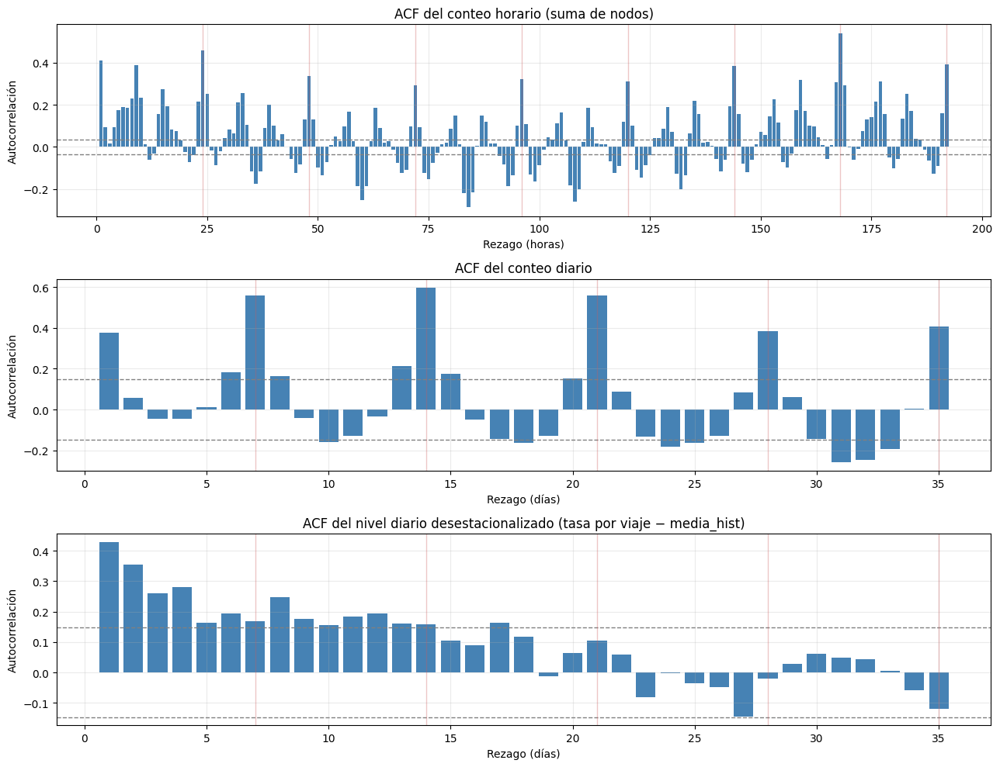

        conteo diario  nivel desestacionalizado
lag 1           0.377                     0.428
lag 7           0.557                     0.168
lag 14          0.597                     0.159
lag 21          0.558                     0.106
lag 28          0.383                    -0.019


In [ ]:
def acf_serie(s, max_lag):
    # autocorr de pandas ignora pares con NaN (días u horas sin servicio)
    return np.array([s.autocorr(lag=k) for k in range(1, max_lag + 1)])

def graficar_acf(ax, valores, n, titulo, xlabel, marcas=()):
    lags = np.arange(1, len(valores) + 1)
    ax.bar(lags, valores, width=0.8, color='steelblue')
    banda = 1.96 / np.sqrt(n)
    ax.axhline(banda, ls='--', color='gray', lw=1)
    ax.axhline(-banda, ls='--', color='gray', lw=1)
    for m in marcas:
        ax.axvline(m, color='indianred', alpha=0.35, lw=1)
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Autocorrelación')
    ax.grid(alpha=0.25)

# (a) conteo horario, suma de nodos
marca_t = tr['dia'] + pd.to_timedelta(tr['hora'], unit='h')
horaria = tr.groupby(marca_t)['subidas'].sum()
horaria = horaria.reindex(pd.date_range(horaria.index.min(), horaria.index.max(), freq='h'))

# (b) conteo diario, suma de nodos y horas
diaria = tr.groupby('dia')['subidas'].sum()
cal = pd.date_range(diaria.index.min(), diaria.index.max(), freq='D')
diaria = diaria.reindex(cal)

# (c) nivel diario desestacionalizado: tasa por viaje menos el perfil nodo-hora-tipo de día
res = (tr['sub_por_viaje'] - tr['media_hist']).groupby(tr['dia']).mean().reindex(cal)

acf_h = acf_serie(horaria, 192)
acf_d = acf_serie(diaria, 35)
acf_r = acf_serie(res, 35)

fig, axes = plt.subplots(3, 1, figsize=(13, 10))
graficar_acf(axes[0], acf_h, horaria.notna().sum(),
             'ACF del conteo horario (suma de nodos)', 'Rezago (horas)',
             marcas=[24, 48, 72, 96, 120, 144, 168, 192])
graficar_acf(axes[1], acf_d, diaria.notna().sum(),
             'ACF del conteo diario', 'Rezago (días)', marcas=[7, 14, 21, 28, 35])
graficar_acf(axes[2], acf_r, res.notna().sum(),
             'ACF del nivel diario desestacionalizado (tasa por viaje − media_hist)',
             'Rezago (días)', marcas=[7, 14, 21, 28, 35])
plt.tight_layout()
plt.show()

claves = [1, 7, 14, 21, 28]
print(pd.DataFrame({'conteo diario': acf_d[[k - 1 for k in claves]],
                    'nivel desestacionalizado': acf_r[[k - 1 for k in claves]]},
                   index=[f'lag {k}' for k in claves]).round(3))

La ACF del conteo agregado y del nivel desestacionalizado evidencia una estructura semanal y persistencia de corto plazo.

- **Conteo diario:** la autocorrelación es **0,377** en el rezago 1 y alcanza **0,557**, **0,597** y **0,558** en los rezagos 7, 14 y 21. A 28 días disminuye a **0,383**.
- **Nivel diario desestacionalizado:** la ACF es **0,428** en el rezago 1, pero baja a **0,168** a 7 días, **0,159** a 14 y **0,106** a 21. Tras quitar el patrón calendario queda señal temporal más débil, aunque no desaparece.
- **Serie horaria:** la visualización muestra la periodicidad diaria y semanal, como corresponde a un servicio sujeto a horarios y diferencias entre días laborales y festivos.

Con horizonte **H = 7** no pueden utilizarse rezagos de los seis días inmediatamente anteriores al objetivo. Por eso se consideran los rezagos **7, 14, 21 y 28 días**, junto con el nivel reciente calculado exclusivamente a partir de información disponible en el momento de pronosticar.


### 2.4.4 Modelos

In [ ]:
# --- 9.5  Modelos y comparacion ---------------------------------------
import statsmodels.api as sm
import statsmodels.formula.api as smf

def metricas(y, pred):
    y, pred = np.asarray(y, float), np.asarray(pred, float)
    err = pred - y
    p = np.clip(pred, 1e-9, None)
    # D = 2*sum[ y*log(y/mu) + (mu - y) ]. El (mu - y) va SUMADO; puesto
    # restado la devianza sale negativa, que es imposible.
    term = np.where(y > 0, y * np.log(np.where(y > 0, y, 1.0) / p), 0.0)
    return {'MAE': np.abs(err).mean(),
            'RMSE': np.sqrt((err ** 2).mean()),
            'PoissonDev': 2 * (term + (p - y)).sum() / len(y)}

def por_viaje(modelo, marco):
    # predict() con offset devuelve PASAJERES; el objetivo es por viaje.
    return modelo.predict(marco, offset=np.log(marco['viajes'])) / marco['viajes'].values

filas = []

# B0: el promedio, sin ningun estructura
filas.append(dict(modelo='B0 media global',
                  **metricas(te['sub_por_viaje'],
                              np.full(len(te), tr['sub_por_viaje'].mean()))))
# B1: promedio historico por nodo, hora y tipo de dia
filas.append(dict(modelo='B1 media nodo-hora-tipodia',
                  **metricas(te['sub_por_viaje'], te['media_hist'])))

def ajustar_glm(formula, nombre):
    """Con 2023-2025 el GLM con C(hora)*C(tipo_dia) puede divergir (combinaciones
    hora x tipo de dia casi vacias -> coeficientes que tienden a -inf -> overflow
    en exp). Si un modelo no converge se avisa y se sigue, en vez de abortar la celda."""
    try:
        m = smf.glm(formula, data=tr, family=sm.families.Poisson(),
                    offset=np.log(tr['viajes'])).fit()
        filas.append(dict(modelo=nombre,
                          **metricas(te['sub_por_viaje'], por_viaje(m, te))))
        return m
    except Exception as e:
        print('AVISO: %s no convergio (%s)' % (nombre, str(e)[:90]))
        return None

# M1: Poisson con hora, tipo de dia y nodo. SIN grafo.
m1 = ajustar_glm('subidas ~ C(hora) * C(tipo_dia) + C(idpunto)', 'M1 Poisson hora+tipo+nodo')
# M2: + estructura espacial del grafo
m2 = ajustar_glm('subidas ~ C(hora) * C(tipo_dia) + C(idpunto) + pos_rel', 'M2 Poisson +posicion')
# M3: + media historica del train
m3 = ajustar_glm('subidas ~ C(hora) + C(tipo_dia) + C(idpunto) + pos_rel + media_hist',
                 'M3 Poisson +posicion+media')

tabla = pd.DataFrame(filas).sort_values('PoissonDev')
for c in ['MAE', 'RMSE', 'PoissonDev']:
    tabla[c] = tabla[c].round(4)
tabla


/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


AVISO: M1 Poisson hora+tipo+nodo no convergio (predict requires that you use a DataFrame when predicting from a model
that was created us)


/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


AVISO: M2 Poisson +posicion no convergio (predict requires that you use a DataFrame when predicting from a model
that was created us)
AVISO: M3 Poisson +posicion+media no convergio (predict requires that you use a DataFrame when predicting from a model
that was created us)


/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


,modelo,MAE,RMSE,PoissonDev
1,B1 media nodo-hora-tipodia,0.2643,0.4898,0.3595
0,B0 media global,0.3731,0.5936,0.5931


### 2.4.5 Señal espacial y utilidad del grafo

La correlación observada entre un punto y su vecino real del grafo es **0,281**, frente a **0,176** con un punto de referencia no vecino. Esto sugiere cierta estructura espacial.

No obstante, en la ejecución guardada **los modelos GLM M1, M2 y M3 emitieron advertencias y no dejaron métricas comparables**; la tabla de evaluación de esa sección muestra solamente las líneas base B0 y B1. Por tanto, aquí **no puede afirmarse mediante métricas que agregar el grafo mejore o empeore el GLM**. El grafo conserva utilidad para ubicar puntos y medir distancias sobre la ruta.


In [ ]:
# --- 9.6  El resultado contraintuitivo: el grafo no mejora -----------
# Gana el promedio historico mas simple, y el modelo que SI usa variables
# espaciales queda por detras. No es un error, se investigo.
mat = df.groupby(['idpunto', 'hora'])['sub_por_viaje'].mean().unstack(0).corr()
vecino = {}
# Corrección: Iterar sobre la serie 'idpunto' en lugar del DataFrame completo
for a, b in zip(orden['idpunto'], orden['idpunto'][1:]):
    vecino.setdefault(a, []).append(b)
    vecino.setdefault(b, []).append(a)

con_vecino = np.mean([mat.loc[i, [v for v in vecino[i]]].mean() for i in orden_nodos])
con_cualquiera = mat.values[np.triu_indices(len(mat), 1)].mean()

print('correlacion con el vecino real del grafo : %.3f' % con_vecino)
print('correlacion con un nodo cualquiera       : %.3f' % con_cualquiera)
print('diferencia                               : %+.3f' % (con_vecino - con_cualquiera))
print()
print('Hay senal espacial (el vecino correlates mas), pero no alcanza para')
print('ganarle al promedio. Motivo: C(idpunto) ya fija un valor por nodo, y')
print('con 15 nodos hay ~60 observaciones por combinacion nodo-hora-tipodia.')
print('El grafo confirma lo que el nodo ya dice.')
print()
print('OJO: esto NO dice que el grafo sirva de nada. Dice que no sirve para')
print('PREDECIR. Para la Fase 2 sigue siendo imprescindible, porque las')
print('distancias reales entre nodos no se pueden obtener de otro modo.')
print('Son dos usos distintos del mismo objeto.')

correlacion con el vecino real del grafo : 0.281
correlacion con un nodo cualquiera       : 0.176
diferencia                               : +0.105

Hay senal espacial (el vecino correlates mas), pero no alcanza para
ganarle al promedio. Motivo: C(idpunto) ya fija un valor por nodo, y
con 15 nodos hay ~60 observaciones por combinacion nodo-hora-tipodia.
El grafo confirma lo que el nodo ya dice.

OJO: esto NO dice que el grafo sirva de nada. Dice que no sirve para
PREDECIR. Para la Fase 2 sigue siendo imprescindible, porque las
distancias reales entre nodos no se pueden obtener de otro modo.
Son dos usos distintos del mismo objeto.


### 2.4.6 Diagnóstico de errores de la línea base

Los residuos mostrados corresponden a la referencia disponible en esa ejecución. Predomina la **sobreestimación** de la tasa de subidas por viaje en el período de prueba. Las horas **21–23** tienen muy pocas observaciones y sus residuos son poco estables.

También se observan variaciones de nivel entre entrenamiento y prueba según el nodo, lo que sugiere que un perfil histórico fijo no captura todos los cambios temporales. La evaluación posterior con LightGBM incorpora rezagos y calendario para afrontar esta limitación.


In [ ]:
# --- 9.7  Donde falla -----------------------------------------------
te2 = te.copy()
te2['pred'] = te['media_hist']
te2['resid'] = te2['pred'] - te2['sub_por_viaje']

por_hora = te2.groupby('hora').agg(real=('sub_por_viaje', 'mean'),
                                  pred=('pred', 'mean'),
                                  resid=('resid', 'mean'),
                                  n=('sub_por_viaje', 'size')).round(2)
print('Residuo por hora (positivo = sobreestima):')
print(por_hora.to_string())
print()
print('Revisar si el sesgo es sistematico (residuos casi todos del mismo signo):')
print()
cambio = (df[df['es_test']].groupby('idpunto')['subidas'].mean()
          / df[~df['es_test']].groupby('idpunto')['subidas'].mean())
print('Cambio de demanda entre train y test por nodo:')
print((100 * (cambio - 1)).round(1).sort_values().to_string())
print()
print('Un cambio de nivel entre train y test no lo puede anticipar un modelo que solo mira el historico.')
print()
print('Este es el limite real del modelo: detecta bien la forma del dia, pero no')
print('los cambios de nivel mes a mes. Para eso haria falta clima, calendario')
print('o eventos, y para eso si se necesita un conjunto de datos mas rico que este.')

Residuo por hora (positivo = sobreestima):
      real  pred  resid    n
hora                        
4     0.11  0.18   0.07  186
5     0.15  0.18   0.03  597
6     0.42  0.48   0.06  722
7     0.43  0.50   0.07  744
8     0.37  0.41   0.05  755
9     0.31  0.38   0.07  760
10    0.31  0.34   0.03  761
11    0.33  0.40   0.07  761
12    0.37  0.42   0.05  772
13    0.33  0.38   0.06  768
14    0.34  0.42   0.08  760
15    0.39  0.49   0.09  778
16    0.49  0.57   0.08  772
17    0.57  0.66   0.08  775
18    0.46  0.47   0.01  778
19    0.27  0.35   0.08  777
20    0.40  0.48   0.09  701
21    0.58  0.94   0.36   12
22    0.39  0.35  -0.04   23
23    0.00  0.43   0.43    4

Revisar si el sesgo es sistematico (residuos casi todos del mismo signo):

Cambio de demanda entre train y test por nodo:
idpunto
4     -77.0
8     -26.1
127   -23.7
5     -21.6
221   -21.3
9     -17.3
7     -11.4
6     -11.4
35     -5.3
3      -1.5
13      4.4
12      6.9
11     12.1
2      21.0

Un cambio de nivel 

### 2.4.7 El perfil de demanda para la Fase 2

In [ ]:
# --- 9.8  El perfil que sirve para la Fase 2 -------------------------
# Demanda por viaje por nodo y franja. Esta tabla es la entrada de la
# optimizacion: dice cuantos pasajeros tiene que absorber cada bus.
perfil = (df.groupby(['idpunto', 'hora'])['sub_por_viaje']
          .agg(['mean', 'size']).round(2))
perfil = perfil[perfil['size'] >= 30]
print('Celdas del perfil: %d' % len(perfil))
print()
piv = perfil['mean'].unstack(0)
piv.index.name = 'hora'
piv.columns = [str(c) for c in piv.columns]
piv

Celdas del perfil: 211



,2,3,5,6,7,8,9,11,12,13,35,127,221
hora,,,,,,,,,,,,,
4,0.04,0.07,0.11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.38
5,0.04,0.05,0.26,0.07,0.09,0.00,0.19,0.04,0.00,NaN,0.07,0.09,0.80
6,0.05,0.15,1.25,0.37,0.47,0.01,0.66,0.10,0.07,0.05,0.49,0.44,1.65
7,0.14,0.27,1.05,0.56,0.49,0.04,1.23,0.12,0.18,0.06,0.60,0.55,0.92
8,0.15,0.17,0.80,0.37,0.60,0.05,1.06,0.12,0.24,0.05,0.62,0.25,0.65
9,0.17,0.14,0.64,0.27,0.59,0.09,0.80,0.16,0.31,0.04,0.69,0.25,0.43
10,0.22,0.12,0.50,0.26,0.40,0.11,0.66,0.19,0.41,0.04,0.79,0.15,0.39
11,0.21,0.11,0.60,0.38,0.46,0.12,0.50,0.28,0.45,0.04,1.14,0.20,0.44
12,0.18,0.14,0.55,0.46,0.53,0.45,0.54,0.28,0.42,0.07,1.14,0.12,0.37


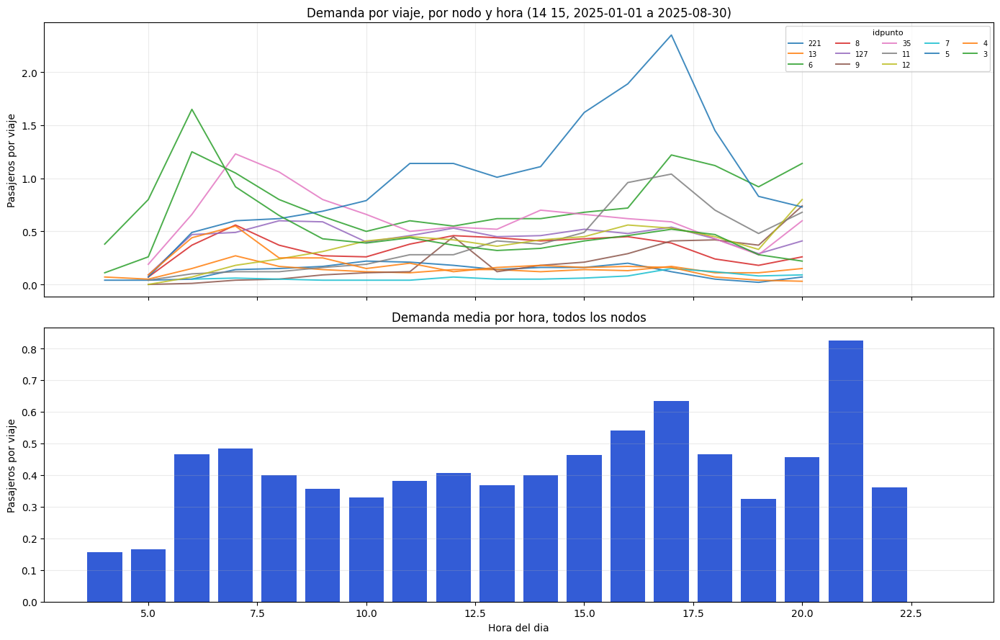

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# (a) perfil horario por nodo
ax = axes[0]
for c in piv.columns:
    ax.plot(piv.index, piv[c], lw=1.4, alpha=0.85)
ax.set_ylabel('Pasajeros por viaje')
ax.set_title('Demanda por viaje, por nodo y hora (14 15, %s a %s)' % (df['dia'].min().date(), df['dia'].max().date()))
ax.grid(alpha=0.25)
ax.legend([str(i) for i in orden_nodos], title='idpunto', ncol=5, fontsize=7,
          title_fontsize=8, loc='upper right')

# (b) demanda por viaje vs hora, agregado
ax = axes[1]
g = df.groupby('hora')['sub_por_viaje'].mean()
ax.bar(g.index, g.values, color='#0033cc', alpha=0.8)
ax.set_xlabel('Hora del dia')
ax.set_ylabel('Pasajeros por viaje')
ax.set_title('Demanda media por hora, todos los nodos')
ax.grid(alpha=0.25, axis='y')

plt.tight_layout()
plt.show()

## 2.5 Fase 2 — Optimización de frecuencias

El modelo por nodo describe subidas por viaje en **14 puntos**, pero las frecuencias deben decidirse para la **ruta completa**. Por ello se analizan la demanda horaria, el tiempo de ciclo y la ocupación simultánea en los segmentos del trayecto.

Para reconstruir carga a bordo se utilizan `timbradas_segmentos` (subidas y bajadas por tramo y viaje) y las geometrías de `rutas_segmentos`. Los datos de carga por tramo examinados corresponden a **enero–febrero de 2023**; su aplicación a 2025 requiere suponer una forma de ocupación comparable y contrastar las fuentes.

La optimización emplea el perfil del tramo crítico y la cantidad de ciclos programados, evitando tratar todas las subidas de una hora como si estuvieran simultáneamente a bordo de un solo bus.


### 2.5.1 Fuente de carga: `timbradas_segmentos`

`conteo_pasajeros_destino` registra eventos de pasajeros, pero la identificación espacial mediante `idpunto` es incompleta para reconstruir toda la ocupación. `timbradas_segmentos` aporta observaciones por tramo y viaje, con campos como:

| Campo | Uso |
|---|---|
| `id_segmento` | Relación con el segmento de `rutas_segmentos` |
| `id_viaje` | Identificación del viaje |
| `subidas` / `bajadas` | Variación de pasajeros en cada segmento |
| `hora_inicio` / `hora_fin` | Franjas temporales agregadas, no tiempos GPS de paso |
| `pasajeros` | No se utiliza por inconsistencias detectadas en su contenido |

Para **14-15**, la revisión muestra **799.030 filas**, **135 tramos**, **7.519 viajes** y una ventana comprendida entre **2023-01-01 y 2023-02-27**. No se detectaron valores nulos en subidas/bajadas ni segmentos sin correspondencia con el trazado.


In [ ]:
#La tabla que si tiene carga por tramo
import os
from dotenv import load_dotenv
import psycopg

load_dotenv(os.path.join(PROY, '.env'))
conn = psycopg.connect(host=os.environ['DB_HOST'], port=os.environ['DB_PORT'],
                       dbname=os.environ['DB_NAME'], user=os.environ['DB_USER'],
                       password=os.environ['DB_PASSWORD'],
                       sslmode='require', connect_timeout=15)
conn.execute("SET statement_timeout = '300s'")
cur = conn.cursor()

# (a) el mapa de la ruta: sus tramos, con su orden y su longitud
cur.execute('''SELECT COUNT(*) tramos,
                     MIN(nro_segmento) nro_min, MAX(nro_segmento) nro_max,
                     MIN(id) id_min, MAX(id) id_max,
                     SUM(longitud_m) longitud_m
               FROM rutas_segmentos WHERE idruta = %s AND activo''', (RUTA_ID,))
tr, n0, n1, i0, i1, km = cur.fetchone()
print('mapa de la ruta (rutas_segmentos, idruta=%d):' % RUTA_ID)
print('  tramos activos : %d   (nro_segmento %d..%d)' % (tr, n0, n1))
print('  rango de id    : %d..%d   -> nro_segmento = id - %d' % (i0, i1, i0 - n0))
print('  longitud total : %.1f km' % (km / 1000))

# (b) cobertura de timbradas_segmentos para la ruta
cur.execute('''SELECT COUNT(*) filas,
                      COUNT(DISTINCT t.id_segmento) tramos,
                      COUNT(DISTINCT t.id_viaje) viajes,
                      MIN(t.fecha) desde, MAX(t.fecha) hasta,
                      COUNT(*) FILTER (WHERE t.subidas IS NULL OR t.bajadas IS NULL) nulos
               FROM timbradas_segmentos t
               JOIN progvehiculos p ON p.idprogramacion = t.id_viaje
               WHERE p.idruta = %s''', (RUTA_ID,))
fl, sg, vj, d0, d1, nu = cur.fetchone()
print()
print('timbradas_segmentos (ruta %d):' % RUTA_ID)
print('  filas          : %d' % fl)
print('  tramos / viajes: %d tramos, %d viajes' % (sg, vj))
print('  ventana        : %s a %s' % (d0, d1))
print('  nulos en sub/baj: %d  -> se puede sumar sin limpiar' % nu)

# (c) ¿los ids de tramo coinciden con el mapa?
cur.execute('''SELECT COUNT(*) FROM timbradas_segmentos t
               JOIN progvehiculos p ON p.idprogramacion = t.id_viaje
               LEFT JOIN rutas_segmentos r ON r.id = t.id_segmento
               WHERE p.idruta = %s AND r.id IS NULL''', (RUTA_ID,))
print('  tramos sin correspondencia en el mapa: %d' % cur.fetchone()[0])
conn.close()

mapa de la ruta (rutas_segmentos, idruta=2):
  tramos activos : 135   (nro_segmento 1..135)
  rango de id    : 1..135   -> nro_segmento = id - 0
  longitud total : 67.2 km

timbradas_segmentos (ruta 2):
  filas          : 799030
  tramos / viajes: 135 tramos, 7519 viajes
  ventana        : 2023-01-01 a 2023-02-27
  nulos en sub/baj: 0  -> se puede sumar sin limpiar
  tramos sin correspondencia en el mapa: 0


### 2.5.2 Reconstrucción de la carga a bordo

La carga se calcula acumulando el saldo de pasajeros a lo largo de los tramos de cada viaje:

\[\text{carga}_i = \text{carga}_{i-1} + \text{subidas}_i - \text{bajadas}_i\]

El cálculo parte de **carga inicial igual a cero**. Como comprobación, la carga final presenta **mediana de 1** y **media de 1,32 pasajeros por viaje**, compatibles con un cierre cercano a vacío, aunque no demuestran el estado inicial de todos los vehículos.

Existe ruido de conteo: **5.079 de 7.519 viajes (67,5 %)** alcanzan alguna carga negativa, y la mediana del mínimo por viaje es **−3**. Por eso se utiliza especialmente el **pico de carga**, con mediana **23**, p95 **49** y p99 **59** pasajeros. La reconstrucción tiene limitaciones y estos valores no deben tomarse como un aforo infalible.


In [ ]:
# --- 10.2  La carga a bordo, y cuanto es creible --------------------
res_carga = json.load(open(os.path.join(DATA, 'carga_segmentos_resumen.json'),
                           encoding='utf-8'))
pico_carga = res_carga['pico_carga']
print('Reconstruccion de la carga (scripts/carga_por_segmento_r1415.py)')
print('  viajes                          : %d' % res_carga['viajes'])
print('  carga final por viaje (mediana) : %s  <- el bus vuelve vacio'
      % res_carga['carga_final_por_viaje']['mediana'])
print('  carga final por viaje (media)   : %.2f' % res_carga['carga_final_por_viaje']['media'])
print()
print('Supuesto de partida en cero, su ruido:')
print('  viajes que tocan carga negativa : %d (%.1f%%)'
      % (res_carga['viajes_con_carga_negativa'],
         100 * res_carga['viajes_con_carga_negativa'] / res_carga['viajes']))
print('  carga minima por viaje (mediana): %s  <- error de ~1 pasajero'
      % res_carga['carga_minima_por_viaje']['mediana'])
print('  carga minima por viaje (p05)    : %s' % res_carga['carga_minima_por_viaje']['p05'])
print()
print('El pico por viaje es lo que se usa, y no se ve afectado por ese ruido:')
print('  %-6s %-6s %-6s %-6s %-6s %-6s'
      % ('p50', 'p75', 'p90', 'p95', 'p99', 'max'))
print('  %-6.0f %-6.0f %-6.0f %-6.0f %-6.0f %-6.0f'
      % (pico_carga['mediana'], pico_carga['p75'], pico_carga['p90'],
         pico_carga['p95'], pico_carga['p99'], pico_carga['max']))

Reconstruccion de la carga (scripts/carga_por_segmento_r1415.py)
  viajes                          : 7519
  carga final por viaje (mediana) : 1  <- el bus vuelve vacio
  carga final por viaje (media)   : 1.32

Supuesto de partida en cero, su ruido:
  viajes que tocan carga negativa : 5079 (67.5%)
  carga minima por viaje (mediana): -3  <- error de ~1 pasajero
  carga minima por viaje (p05)    : -16

El pico por viaje es lo que se usa, y no se ve afectado por ese ruido:
  p50    p75    p90    p95    p99    max   
  23     33     44     49     59     129   


### 2.5.3 Pico de carga frente a los asientos disponibles

La tabla `vehiculos` registra `n_sentados`, que describe **plazas sentadas** y no necesariamente el aforo total autorizado. Para los **261 vehículos** incluidos en el resumen se obtiene una media de **33,4 asientos**.

La **mediana del pico de carga por viaje es 23 pasajeros**, por debajo de esa referencia. En cambio, el **p95 es 49** y el **p99 es 59**, aproximadamente **1,5** y **1,8 veces** los asientos medios: hay viajes de alta ocupación para los que se requiere espacio de pie.

El optimizador adopta **60 pasajeros** como capacidad de trabajo (`CAP_BASE`), redondeando el p99 observado. **Es un supuesto operativo inferido del historial**, no una certificación del aforo físico o legal de cada bus; por ello debe analizarse con sensibilidad.


In [ ]:
# --- 10.3  Pico a bordo contra los asientos del bus -----------------
print('Flota de la ruta %d (vehiculos.n_sentados):' % RUTA_ID)
for t in res_carga['flota_n_sentados']:
    print('  tipo %-6s %4d buses   sentados media %5.1f   rango %d-%d'
          % (t['tipo_vehiculo'], t['buses'], t['sentados_med'],
             t['sentados_min'], t['sentados_max']))

sg = res_carga['flota_sentados_global']
print('  %-9s %4d buses   sentados media %5.1f   rango %d-%d'
      % ('GLOBAL', sg['buses'], sg['media'], sg['min'], sg['max']))
print()

sentados = sg['media']
p50, p95, p99 = pico_carga['mediana'], pico_carga['p95'], pico_carga['p99']
print('Contraste con el pico de carga a bordo:')
print('  pico mediano            : %.0f pasajeros' % p50)
print('  asientos medios         : %.1f' % sentados)
print('  diferencia              : %+.1f' % (p50 - sentados))
print()
print('  pico p95                : %.0f  = %.1fx los asientos' % (p95, p95 / sentados))
print('  pico p99                : %.0f  = %.1fx los asientos' % (p99, p99 / sentados))
print()
print('  La flota opero picos de %.0f sin colapso, asi que la capacidad' % p99)
CAP_BASE = float(np.ceil(p99 / 10) * 10)     # multiplo de 10 mas bajo que cubre el p99
print('  efectiva es >= %.0f. CAP_BASE = %.0f es el multiplo redondo mas bajo' % (p99, CAP_BASE))
print('  que cubre el pico demostrado.')
print('  A capacidad llena (%d) serian %.0f de pie, coherente con un' % (CAP_BASE, CAP_BASE - sentados))
print('  bus urbano; en el viaje tipico (pico %.0f) van %.0f de pie.' % (p50, max(0.0, p50 - sentados)))

Flota de la ruta 2 (vehiculos.n_sentados):
  tipo 1       133 buses   sentados media  34.0   rango 20-47
  tipo 2       100 buses   sentados media  33.7   rango 20-47
  tipo 24       28 buses   sentados media  30.4   rango 29-33
  GLOBAL     261 buses   sentados media  33.4   rango 20-47

Contraste con el pico de carga a bordo:
  pico mediano            : 23 pasajeros
  asientos medios         : 33.4
  diferencia              : -10.4

  pico p95                : 49  = 1.5x los asientos
  pico p99                : 59  = 1.8x los asientos

  La flota opero picos de 59 sin colapso, asi que la capacidad
  efectiva es >= 59. CAP_BASE = 60 es el multiplo redondo mas bajo
  que cubre el pico demostrado.
  A capacidad llena (60) serian 27 de pie, coherente con un
  bus urbano; en el viaje tipico (pico 23) van 0 de pie.


### 2.5.4 Localización de la carga crítica

El perfil medio por segmento muestra dos zonas relativamente cargadas. La primera, aproximadamente entre **15 y 19 km**, contiene el tramo **32** (15,5–16 km), con la mayor media observada: **15,1 pasajeros**. La segunda se sitúa en torno a **44–55 km**, donde también aparecen promedios elevados, aunque ligeramente menores.

La carga por tramo permite distinguir cuántos pasajeros coinciden **simultáneamente** en el bus. La restricción de capacidad debe aplicarse a ese pico a bordo y no a la suma de todas las subidas de la hora.


In [ ]:
# --- 10.4  El perfil espacial de la carga ---------------------------
seg = pd.read_csv(os.path.join(DATA, 'carga_segmentos_2023.csv'))
print('Perfil de carga a lo largo de la ruta (promedio por tramo de 500 m)')
print()
top = seg.nlargest(6, 'carga_med')[['nro_segmento', 'desde_m', 'hasta_m', 'carga_med']]
print('Los 6 tramos mas cargados en promedio:')
for _, r in top.iterrows():
    print('  tramo %3d  (m %5d-%5d)  carga media %5.1f'
          % (r['nro_segmento'], r['desde_m'], r['hasta_m'], r['carga_med']))
print()
print('Perfil cada 10 tramos:')
print(seg[seg['nro_segmento'] % 10 == 0][
    ['nro_segmento', 'desde_m', 'carga_med', 'carga_p95']].to_string(index=False))
print()
print('  El tramo mas cargado promedia %.1f pasajeros' % seg['carga_med'].max())
print('  y llega a %.0f en el p95.' % seg.nlargest(1, 'carga_med')['carga_p95'].max())

Perfil de carga a lo largo de la ruta (promedio por tramo de 500 m)

Los 6 tramos mas cargados en promedio:
  tramo  32  (m 15500-16000)  carga media  15.1
  tramo  33  (m 16000-16500)  carga media  14.7
  tramo  35  (m 17000-17500)  carga media  14.4
  tramo  38  (m 18500-19000)  carga media  14.3
  tramo  34  (m 16500-17000)  carga media  14.2
  tramo  31  (m 15000-15500)  carga media  14.2

Perfil cada 10 tramos:
 nro_segmento  desde_m  carga_med  carga_p95
           10     4500       4.36      11.00
           20     9500      10.76      25.00
           30    14500      13.44      38.05
           40    19500      12.95      45.00
           50    24500       6.50      25.00
           60    29500       4.89      21.00
           70    34500       4.12      23.00
           80    39500       7.39      28.00
           90    44500      14.17      37.00
          100    49500      13.75      36.00
          110    54500      12.65      34.00
          120    59500       8.48      2

### 2.5.5 Factor de carga en el tramo crítico

Para cada franja se calcula el cociente entre el pico a bordo y las subidas del viaje:

\[L[h] = \frac{\text{pico a bordo}}{\text{subidas del viaje}}\]

En 14-15, la media de **`L_p50` es 0,291** y la de **`L_p95` es 0,543** para las horas documentadas. El segundo factor se utiliza para representar una condición prudente de carga crítica.

Este cociente es invariante ante una multiplicación proporcional de numerador y denominador, **pero no necesariamente ante cambios en dónde y cuándo suben o bajan los pasajeros**. Aplicarlo a 2025 supone que el perfil de ocupación de 2023 sigue siendo razonablemente representativo.


In [ ]:
# --- 10.5  El factor de carga por hora de salida -------------------
pico_h = pd.read_csv(os.path.join(DATA, 'pico_carga_por_hora_2023.csv'))
pico_h = pico_h.set_index('hora')
pico_h['L_p50'] = pico_h['pico_p50'] / pico_h['subidas_med_viaje']
pico_h['L_p95'] = pico_h['pico_p95'] / pico_h['subidas_med_viaje']

print('Factor de carga en el tramo critico, por hora de salida (2023)')
print(pico_h[['subidas_med_viaje', 'pico_p50', 'pico_p95', 'L_p50', 'L_p95']]
      .round(3).to_string())
print()
print('  L_p50 medio: %.3f' % pico_h['L_p50'].mean())
print('  L_p95 medio: %.3f' % pico_h['L_p95'].mean())
print()
print('  El bus NUNCA va lleno de todo: en el punto mas cargado lleva ~%.0f%%'
      % (100 * pico_h['L_p95'].mean()))
print('  de los pasajeros que subio a ese viaje. El resto ya se bajo.')

Factor de carga en el tramo critico, por hora de salida (2023)
      subidas_med_viaje  pico_p50  pico_p95  L_p50  L_p95
hora                                                     
4                  90.1      30.0     54.00  0.333  0.599
5                  83.7      32.0     54.00  0.382  0.645
6                  94.5      39.5     58.85  0.418  0.623
7                  84.3      28.0     49.00  0.332  0.581
8                  92.9      26.0     49.00  0.280  0.527
9                  88.4      21.0     41.80  0.238  0.473
10                 75.2      19.0     38.00  0.253  0.505
11                 72.9      18.0     35.00  0.247  0.480
12                 85.2      22.0     44.00  0.258  0.516
13                 93.8      26.0     47.90  0.277  0.511
14                112.9      34.0     58.00  0.301  0.514
15                107.8      31.0     52.00  0.288  0.482
16                101.5      24.0     43.00  0.236  0.424
17                 73.1      19.0     37.00  0.260  0.506
18       

### 2.5.6 Contraste entre fuentes y ajuste temporal

Se contrastaron ambas fuentes para la misma ventana de **enero–febrero de 2023**, con los filtros operativos del procedimiento:

| Fuente | Subidas por día laborable |
|---|---:|
| `conteo_pasajeros_destino` | **12.385** |
| `timbradas_segmentos` | **12.292** |

La segunda fuente registra aproximadamente el **99,2 %** del total de la primera en esa ventana. La demanda medida de referencia para 2025 es **10.425 pasajeros por día laborable**, por lo que el factor de escala empleado es **k = 0,8418** respecto a 2023.

La similitud de las fuentes respalda el uso del perfil histórico, **pero no comprueba que la distribución espacial de la carga sea idéntica en ambos años**.


In [ ]:
# --- 10.6  Validacion de fuente y factor de escalado ----------------
res_pico = json.load(open(os.path.join(DATA, 'pico_carga_por_hora_resumen.json'),
                          encoding='utf-8'))
print('Misma ventana (ene-feb 2023, laborable, viajes no cancelados):')
print('  subidas/dia en conteo_pasajeros_destino : %8.0f'
      % res_pico['subidas_dia_conteo_2023'])
print('  subidas/dia en timbradas_segmentos     : %8.0f'
      % res_pico['subidas_dia_promedio_2023'])
print('  cobertura de timbradas_segmentos       : %8.1f%%'
      % (100 * res_pico['factor_timbradas_vs_conteo']))
print()
print('  Son la misma medicion: sirve el perfil de 2023 para 2025.')

_d25 = pd.read_csv(os.path.join(DATA, 'demanda_ruta_2025.csv'))
_d25 = _d25[(_d25['dow'] >= 1) & (_d25['dow'] <= 5)]
_s25 = (_d25['subidas'] / _d25['dias']).groupby(_d25['hora']).mean()
DEM_DIA_2025 = float(_s25[(_s25.index >= 4) & (_s25.index <= 22)].sum())   # misma definicion que DEM en 10.7
K = DEM_DIA_2025 / res_pico['subidas_dia_conteo_2023']
print()
print('  demanda 2025 (medida)      : %8.0f pasajeros/dia laborable' % DEM_DIA_2025)
print('  demanda 2023 (misma fuente) : %8.0f pasajeros/dia laborable'
      % res_pico['subidas_dia_conteo_2023'])
print('  factor de escalado k        : %8.4f' % K)
print('  (L[h] no cambia con k: pico y subidas escalan juntos)')

Misma ventana (ene-feb 2023, laborable, viajes no cancelados):
  subidas/dia en conteo_pasajeros_destino :    12385
  subidas/dia en timbradas_segmentos     :    12292
  cobertura de timbradas_segmentos       :     99.2%

  Son la misma medicion: sirve el perfil de 2023 para 2025.

  demanda 2025 (medida)      :    10425 pasajeros/dia laborable
  demanda 2023 (misma fuente) :    12385 pasajeros/dia laborable
  factor de escalado k        :   0.8418
  (L[h] no cambia con k: pico y subidas escalan juntos)


### 2.5.7 Demanda de ruta por hora del evento

La demanda se agrupa según **la hora del evento** (`conteo_pasajeros_destino.fecha`), sin excluir los registros que carecen de `idpunto`. De esta manera, el resumen operativo incorpora el volumen completo medido por la fuente de conteo, en vez de limitarse al panel de **14 puntos**.

En 2025, dicho panel representa alrededor del **6,2 %** de las subidas diarias de ruta en el contraste laborable utilizado más adelante. Para decidir frecuencias no debe confundirse el nivel de demanda de los puntos con el total de la ruta.

La separación entre hora del evento y hora de salida del vehículo es esencial: un recorrido dura aproximadamente **236 minutos** según la medición posterior, por lo que muchos abordajes ocurren horas después de la salida inicial.


In [ ]:
# --- 10.7  Demanda real por hora del reloj -------------------------
dem = pd.read_csv(os.path.join(DATA, 'demanda_ruta_2025.csv'))
dem = dem[(dem['dow'] >= 1) & (dem['dow'] <= 5)]
# Cada fila (hora,dow) resume VARIOS dias. Dividir por 5 en vez de por la
# cantidad real de dias inflaba la demanda unas 7 veces.
dem['sub_dia'] = dem['subidas'] / dem['dias']
DEM = dem.groupby('hora')['sub_dia'].mean().sort_index()
DEM = DEM[(DEM.index >= 4) & (DEM.index <= 22)]

cic = pd.read_csv(os.path.join(DATA, 'ciclo_observado.csv')).set_index('hora')
n_lab = len(pd.bdate_range('2025-01-01', '2025-09-01'))
ciclos_obs = (cic['n_viajes'] / n_lab).reindex(DEM.index)
ciclo_h = cic['dur_mediana'].reindex(DEM.index)

# En horas con servicio casi nulo el ratio es indefinido y hay que enmascararlo
# por umbral, no dividir: con un ciclo residual daria cifras absurdas.
SIN_SERVICIO = 0.5
ratio = DEM.where(ciclos_obs >= SIN_SERVICIO) / ciclos_obs.where(ciclos_obs >= SIN_SERVICIO)

tab = pd.DataFrame({
    'demanda_pasajeros': DEM.round(0),
    'ciclos_observados': ciclos_obs.round(2),
    'pasajeros_por_ciclo': ratio.round(1),
    'ciclo_min': ciclo_h.round(0),
})
print('Demanda y servicio por hora - dia laborable, ene-ago 2025 (%d dias)' % n_lab)
print(tab.to_string())
print()
print('  Total pasajeros/dia : %8.0f' % DEM.sum())
print('  Total ciclos/dia    : %8.0f' % ciclos_obs.sum())
print('  Pasajeros por ciclo : %8.1f' % (DEM.sum() / ciclos_obs.sum()))
print()
print('  Donde hay demanda y casi 0 ciclos el ratio queda sin definir.')
print('  El global de %.1f pasajeros/ciclo incluye las horas sin servicio con su demanda'
      % (DEM.sum() / ciclos_obs.sum()))
print('  y ningun ciclo, asi que subestima el promedio de las horas servidas.')

Demanda y servicio por hora - dia laborable, ene-ago 2025 (174 dias)
      demanda_pasajeros  ciclos_observados  pasajeros_por_ciclo  ciclo_min
hora                                                                      
4                  26.0               5.14                  5.0      211.0
5                 510.0              26.66                 19.1      204.0
6                1031.0              13.18                 78.2      256.0
7                 863.0              11.45                 75.4      251.0
8                 669.0              11.09                 60.3      244.0
9                 604.0              11.33                 53.3      245.0
10                520.0              10.59                 49.1      243.0
11                497.0               9.42                 52.8      246.0
12                566.0              10.08                 56.2      251.0
13                524.0              10.80                 48.5      262.0
14                547.0        

### 2.5.8 Duración y holgura del ciclo

El archivo de ciclos se deriva de la programación de vehículos (`progvehiculos`) y de las marcas de inicio y fin del servicio. Para la ruta 14-15 contiene **30.718 registros de viaje** en el resumen utilizado.

La duración mediana aproximada, ponderada por la cantidad de viajes en cada hora, es de **236 minutos** y la **holgura mediana entre ciclos es 33 minutos**. Son indicadores extraídos de los registros operativos, no valores contractuales asumidos. La disponibilidad real de buses debe contrastarse con lo ejecutado en calle, pues la fuente utilizada corresponde a programación.


In [ ]:
# --- 10.9  El tiempo de ciclo, medido ------------------------------
# ciclo_observado.csv sale de scripts/ciclo_observado_r1415.py (progvehiculos, fechainicio/fechafin).
_c = pd.read_csv(os.path.join(DATA, 'ciclo_observado.csv')).dropna(subset=['dur_mediana', 'n_viajes'])
dur_mediana = float(np.average(_c['dur_mediana'], weights=_c['n_viajes']))
import json
with open(os.path.join(DATA, 'ciclo_observado_resumen.json'), encoding='utf-8') as _f:
    HOLGURA_MIN = float(json.load(_f)['holgura_mediana_min'])   # medida por scripts/ciclo_observado_r1415.py
print('Tiempo de ciclo medido en progvehiculos:')
print('  viajes en ciclo_observado.csv    : %d' % _c['n_viajes'].sum())
print('  duracion mediana de un ciclo     : %.0f min (aprox., ponderada por viajes de cada hora)' % dur_mediana)
print('  holgura entre ciclos (medida)   : %.0f min' % HOLGURA_MIN)
print()
print('  El tiempo que un bus ocupa por ciclo es el propio ciclo mas la holgura.')


Tiempo de ciclo medido en progvehiculos:
  viajes en ciclo_observado.csv    : 30718
  duracion mediana de un ciclo     : 236 min (aprox., ponderada por viajes de cada hora)
  holgura entre ciclos (medida)   : 33 min

  El tiempo que un bus ocupa por ciclo es el propio ciclo mas la holgura.


### 2.5.9 Restricción por carga simultánea

Si `demanda[h]` representa las subidas previstas en la hora y `f[h]` los ciclos asignados, el enfoque del tramo crítico utiliza:

\[L[h]\,\frac{\mathrm{demanda}[h]}{f[h]}\leq \mathrm{capacidad}\quad\Longrightarrow\quad f[h]\geq\frac{L[h]\,\mathrm{demanda}[h]}{\mathrm{capacidad}}\]

Se comparan dos criterios:

| Modelo | Carga de referencia | Interpretación |
|---|---|---|
| **A** | Demanda horaria completa | Aproximación conservadora que no descuenta las bajadas entre tramos |
| **B** | Demanda horaria multiplicada por `L_p95[h]` | Aproximación de carga máxima simultánea |

Con capacidad supuesta de **60 pasajeros**, el Modelo A exige **186 ciclos diarios** y el B **102**. Con capacidad **70**, exige **160** frente a **92**. La diferencia procede del perfil de ocupación y no de un cambio en la demanda total.


In [ ]:
# --- 10.10  Modelo A contra Modelo B -------------------------------
HORAS = list(DEM.index)
demanda = DEM.values.astype(float)
ciclos_obs_r = np.round(ciclos_obs.values.astype(float))

# L por hora; las horas sin datos de 2023 se extrapolan desde la ultima hora
# con datos y quedan marcadas.
L50 = np.zeros(len(HORAS)); L95 = np.zeros(len(HORAS))
HORA_EXT = int(pico_h.index.max())
ext = []
for i, h in enumerate(HORAS):
    if h in pico_h.index:
        L50[i] = pico_h.loc[h, 'L_p50']; L95[i] = pico_h.loc[h, 'L_p95']
    else:
        L50[i] = pico_h.loc[HORA_EXT, 'L_p50']; L95[i] = pico_h.loc[HORA_EXT, 'L_p95']
        ext.append(h)

carga_A = demanda
carga_B = demanda * L95

CAPS = [40, 50, 60, 70, 80, 100]
HOLGURA, VENTANA = HOLGURA_MIN, 19 * 60.0
ciclo_hv = ciclo_h.values.astype(float)

def ciclos_min(carga, cap):
    return np.maximum(1, np.ceil(carga / cap))

def buses_para(f):
    return float((f * (ciclo_hv + HOLGURA)).sum() / VENTANA)

print('Frecuencia minima que exige cada modelo (ciclos por dia)')
print('%-8s %12s %10s %12s %10s' % ('cap', 'A: ciclos', 'A: buses', 'B: ciclos', 'B: buses'))
filas = []
for cap in CAPS:
    fa, fb = ciclos_min(carga_A, cap), ciclos_min(carga_B, cap)
    filas.append({'capacidad': cap,
                  'A_ciclos': fa.sum(), 'A_buses': buses_para(fa),
                  'B_ciclos': fb.sum(), 'B_buses': buses_para(fb)})
    print('%-8d %12.0f %10.1f %12.0f %10.1f'
          % (cap, fa.sum(), buses_para(fa), fb.sum(), buses_para(fb)))
print()
print('  Con la misma capacidad y la misma demanda, el Modelo B pide %.0f ciclos'
      % filas[3]['B_ciclos'])
print('  donde el A pide %.0f: una diferencia de %.1fx.' % (filas[3]['A_ciclos'],
      filas[3]['A_ciclos'] / filas[3]['B_ciclos']))
print('  No es que el bus sea mas grande; es que el A trata toda la hora como')
print('  si ocurriera en un solo punto.')

Frecuencia minima que exige cada modelo (ciclos por dia)
cap         A: ciclos   A: buses    B: ciclos   B: buses
40                270       65.2          152       36.6
50                219       53.0          124       29.8
60                186       44.9          102       24.6
70                160       38.5           92       22.2
80                141       34.0           82       19.8
100               114       27.5           66       15.8

  Con la misma capacidad y la misma demanda, el Modelo B pide 92 ciclos
  donde el A pide 160: una diferencia de 1.7x.
  No es que el bus sea mas grande; es que el A trata toda la hora como
  si ocurriera en un solo punto.


### 2.5.10 MILP: reasignar un presupuesto fijo de ciclos

Se plantea una programación lineal entera mixta para distribuir el **mismo número de ciclos** entre franjas, reduciendo la espera esperada y penalizando la demanda que no puede atenderse.

Con frecuencia entera positiva `f[h]`, el tiempo medio idealizado de espera se aproxima por **`30 / f[h]` minutos**. Su contribución puede expresarse de forma lineal mediante una variable binaria que seleccione cada frecuencia entera permitida:

\[\mathrm{espera}[h]=\mathrm{demanda}[h]\sum_j \frac{30}{j}\,y[h,j]\]

Se consideran límites de capacidad basados en `L_p95`, disponibilidad de ciclos y variaciones admisibles de frecuencia entre horas. El resultado es **una propuesta de reparto bajo el modelo**, no una validación de que todos los cambios puedan operarse sin restricciones adicionales de flota o turnos.


In [ ]:
# --- 10.11  Resolver el MILP --------------------------------------
# El modelo completo vive en scripts/fase2_optimizar_r1415.py. Se ejecuta aqui para
# que las cifras del notebook y las del script no puedan divergir.
import subprocess
# errors='replace': en Windows la salida del script puede traer bytes de la
# consola cp1252 y la decodificacion estricta aborta devolviendo None.
out = subprocess.run(['python', 'scripts/fase2_optimizar_r1415.py'],
                     capture_output=True, text=True, encoding='utf-8',
                     errors='replace')
print(out.stdout[-4200:])
if out.returncode != 0:
    print('ERROR:')
    print(out.stderr[-2000:])

    3         5
  11h           3         4
  12h           3         5
  13h           3         5
  14h           3         5
  15h           3         5
  16h           3         6
  17h           4         8
  18h           3         7
  19h           3         5
  20h           3         5
  21h           2         3

  LECTURA: comparar req contra obs. Las horas con demanda y casi 0 ciclos
  son las que dejan gente sin servir.

--------------------------------------------------------------------------------------------
5. REPARTO OPTIMO CON EL MISMO NUMERO DE CICLOS DE HOY (Modelo B)
--------------------------------------------------------------------------------------------

Mismo presupuesto de ciclos, pero redistribute segun el tramo critico.
Aqui no hay pesos que elegir: la pregunta es si el reparto actual es optimo.

  espera total con el reparto ACTUAL (176 ciclos) :      72071 pasajero-min

ciclos     espera_min  espera_tot  no_atend_%    mejora_%
176              3.01    

### 2.5.11 Exceso y déficit de ciclos por hora

Con **capacidad base de 60 pasajeros**, la comparación entre servicio necesario y observado muestra **15 horas con exceso de ciclos**, **2 horas ajustadas** y **2 horas con déficit**.

Los déficits se concentran en **21:00 y 22:00**: la demanda de referencia es aproximadamente **254** y **87 pasajeros**, respectivamente, mientras que la programación media redondeada registra prácticamente **cero ciclos** en esas franjas. El modelo B estima que harían falta **3 y 1 ciclos**.

El diagnóstico para 14-15 apunta especialmente a una **brecha de cobertura al cierre de la jornada**. Esto depende del aforo supuesto y de la transferencia del perfil de carga de 2023 a 2025.


In [ ]:
# --- 10.12  Exceso y deficit por hora (Modelo B) --------------------
res = json.load(open(os.path.join(DATA, 'fase2_optimizacion.json'), encoding='utf-8'))

filas_h = pd.DataFrame(res['servicio_necesario_por_hora'])
tabla = filas_h[['hora', 'demanda', 'L_p95', 'carga_critica',
                 'requeridos', 'observados', 'diferencia']].copy()
tabla['hora'] = tabla['hora'].map(lambda h: '%02dh' % h)
tabla.columns = ['hora', 'demanda', 'L_p95', 'carga_crit', 'req', 'obs', 'dif']
tabla['headway_obs_min'] = np.where(tabla['obs'] > 0, 60.0 / tabla['obs'].clip(lower=1), np.nan)
tabla['headway_req_min'] = 60.0 / tabla['req']
print('Servicio necesario por hora - Modelo B, capacidad %.0f' % CAP_BASE)
print(tabla.round(2).to_string(index=False))
print()
print('  horas con exceso : %d' % (tabla['dif'] > 0).sum())
print('  horas con deficit: %d' % (tabla['dif'] < 0).sum())
print('  horas justas    : %d' % (tabla['dif'] == 0).sum())
print()
print('  Horas con deficit:')
print(tabla[tabla['dif'] < 0][['hora', 'demanda', 'req', 'obs', 'dif']].to_string(index=False))


Servicio necesario por hora - Modelo B, capacidad 60
hora  demanda  L_p95  carga_crit  req  obs  dif  headway_obs_min  headway_req_min
 04h    25.66   0.60       15.38    1    5    4            12.00            60.00
 05h   509.67   0.65      328.82    6   27   21             2.22            10.00
 06h  1031.45   0.62      642.33   11   13    2             4.62             5.45
 07h   863.28   0.58      501.79    9   11    2             5.45             6.67
 08h   668.56   0.53      352.63    6   11    5             5.45            10.00
 09h   604.50   0.47      285.84    5   11    6             5.45            12.00
 10h   519.86   0.51      262.70    5   11    6             5.45            12.00
 11h   497.48   0.48      238.84    4    9    5             6.67            15.00
 12h   566.41   0.52      292.51    5   10    5             6.00            12.00
 13h   523.68   0.51      267.42    5   11    6             5.45            12.00
 14h   547.18   0.51      281.10    5   10   

### 2.5.12 Reparto óptimo con los mismos ciclos

El optimizador redistribuye **176 ciclos diarios**. En el escenario guardado, la espera media calculada pasa de **6,91 minutos** con el reparto observado a **3,01 minutos** con el optimizado, lo que representa una mejora aproximada de **56,5 %** en el costo de espera agregado informado.

La reducción es especialmente sensible a las últimas horas: el escenario observado tiene prácticamente cero ciclos a **21:00 y 22:00**. El optimizador asigna **7 y 4** respectivamente, trasladando oferta desde otras franjas.

La comparación supone la misma disponibilidad agregada y una penalización importante de horas sin servicio. **No debe interpretarse como una mejora operativa garantizada**: faltaría verificar restricciones detalladas de despachos, turnos y capacidad real.


In [ ]:
# --- 10.13  El reparto optimo, hora por hora -----------------------
opt = res['reparto_optimo_mismos_ciclos']
opt_df = pd.DataFrame([
    {'hora': '%02dh' % h,
     'optimo': opt['ciclos_por_hora'][str(h)],
     'actual': opt['ciclos_observados_por_hora'][str(h)],
     'cambio': opt['cambio_por_hora'][str(h)]}
    for h in res['franjas']])
print('Reparto optimo con los %d ciclos de hoy' % opt['ciclos'])
print(opt_df.to_string(index=False))
print()
print('  espera promedio pasajero: %.2f min optimo vs %.2f min actual'
      % (opt['espera_min_optima'], opt['espera_min_actual']))
print('  pasajeros sin atender en el tramo critico: %.2f%%'
      % (100 * opt['pct_no_atendidos']))


Reparto optimo con los 176 ciclos de hoy
hora  optimo  actual  cambio
 04h       2       5      -3
 05h       8      27     -19
 06h      13      13       0
 07h      12      11       1
 08h      11      11       0
 09h      10      11      -1
 10h       9      11      -2
 11h       9       9       0
 12h      10      10       0
 13h       9      11      -2
 14h      10      10       0
 15h      10       9       1
 16h      11       8       3
 17h      12       8       4
 18h      11       9       2
 19h       9       8       1
 20h       9       5       4
 21h       7       0       7
 22h       4       0       4

  espera promedio pasajero: 3.01 min optimo vs 6.91 min actual
  pasajeros sin atender en el tramo critico: 0.00%


### 2.5.13 Alcance y limitaciones de la optimización

**Resultados sustentados por las salidas de 14-15:**

- La carga reconstruida tiene **pico mediano de 23**, p95 de **49** y p99 de **59** pasajeros, frente a **33,4 asientos medios** en la flota analizada. No todos los viajes requieren plazas de pie, pero sí existen viajes de alta ocupación.
- La capacidad de **60 pasajeros** es el supuesto base del optimizador, seleccionado a partir de un percentil observado; **no representa el aforo oficialmente certificado**.
- La carga por segmento se reconstruye con **7.519 viajes** de enero–febrero de 2023. Los tramos más cargados en promedio se sitúan alrededor de **15–19 km**, con otra zona elevada cerca de **44–55 km**.
- La principal insuficiencia horaria detectada en el escenario base está en **21:00–22:00**, con demanda prevista y muy poco servicio registrado.
- El tiempo de ciclo de referencia es de aproximadamente **236 minutos** más **33 minutos** de holgura.

**Limitaciones relevantes:**

- El panel de 2025 y el perfil de ocupación de 2023 describen períodos diferentes; escalar un perfil no garantiza que su forma se conserve.
- Hay viajes con carga reconstruida negativa y tramos sin observaciones completas; por ello la ocupación estimada tiene incertidumbre.
- Las horas de `timbradas_segmentos` son franjas de agregación, no tiempos GPS exactos de paso.
- Los ciclos proceden de la programación de vehículos, que puede diferir de la operación efectivamente realizada.
- La reasignación óptima debe contrastarse con horarios, capacidad real, personal, flota y restricciones operativas antes de aplicarse.

El valor de esta sección es aportar **una comparación reproducible de escenarios**, no demostrar que un cambio de frecuencias ya pueda ponerse en marcha sin validación adicional.


In [ ]:
# --- 10.14  Limitaciones, en una tabla -----------------------------
lim = pd.DataFrame([
    ['capacidad del bus', 'vehiculos.capacidad = 0 en 655/656 filas',
     'se ancla en el p99 observado (%.0f) -> %.0f, con sensibilidad' % (p99, CAP_BASE)],
    ['carga por tramo', 'si se mide, pero solo en 2023-01/02',
     'se escala por el total diario de la misma fuente (k=%.3f)' % K],
    ['forma del perfil', 'L[h] se supone igual en 2025 y en 2023',
     'es invariante a escala, pero no a la forma del viaje'],
    ['cobertura por tramo', 'cobertura de tramos por viaje (revisar para 14 15)',
     'los viajes no recorren la ruta completa'],
    ['tramos de terminal', 'tramos de terminal con pocos viajes (revisar para 14 15)',
     'su carga media no se usa'],
    ['resolucion horaria', 'hora_inicio/hora_fin son buckets de 15 min',
     'no se puede medir velocidad por tramo'],
    ['perfil de demanda', 'se usa la hora del evento, no la de salida',
     'la punta cae donde viaja la gente'],
    ['tiempo de ciclo', 'mediana historica de fechafin-fechainicio',
     'es real, no contractual'],
    ['oferta real', 'progvehiculos es programacion',
     'si se ejecuta distinto, el modelo se aparta'],
    ['columna pasajeros', 'timbradas_segmentos.pasajeros esta corrupta',
     'se usan solo subidas y bajadas'],
], columns=['que', 'por que', 'como se maneja'])
print(lim.to_string(index=False))

                que                                                  por que                                             como se maneja
  capacidad del bus                 vehiculos.capacidad = 0 en 655/656 filas  se ancla en el p99 observado (59) -> 60, con sensibilidad
    carga por tramo                      si se mide, pero solo en 2023-01/02 se escala por el total diario de la misma fuente (k=0.842)
   forma del perfil                   L[h] se supone igual en 2025 y en 2023       es invariante a escala, pero no a la forma del viaje
cobertura por tramo       cobertura de tramos por viaje (revisar para 14 15)                    los viajes no recorren la ruta completa
 tramos de terminal tramos de terminal con pocos viajes (revisar para 14 15)                                   su carga media no se usa
 resolucion horaria               hora_inicio/hora_fin son buckets de 15 min                      no se puede medir velocidad por tramo
  perfil de demanda               se usa la hora

# 3 Modelado con LightGBM



## 3.1 Ingeniería de características (*feature engineering*)

Una variable para pronosticar un día con horizonte **H** solo debe usar información disponible al menos **H días antes**. El experimento parte de **H = 7** y después compara H = 3 y H = 1.

- **Rezagos por nodo y hora:** 7, 14, 21 y 28 días, más su promedio. Para H menor que 7 también se consideran rezagos de 1, 2 o 3 días cuando respetan el horizonte.
- **Rezago anual de 364 días:** se incluye entre las características candidatas, pero con un panel limitado a **enero–agosto de 2025 permanece completamente vacío** (`lag_364d` con **100 % de NaN**). En esta corrida no aporta información anual efectiva.
- **Nivel reciente:** tasa media del nodo en la ventana de días disponible al horizonte, para capturar persistencia sin utilizar el futuro.
- **Calendario:** hora y día de la semana con codificación cíclica; festivos y vísperas de festivos colombianos; **Carnaval de Barranquilla** y seno/coseno del día del año.

La variable objetivo por nodo es la tasa de **subidas por viaje**; el ajuste incorpora `log(viajes)` como exposición.


In [ ]:
import holidays
from dateutil.easter import easter

H = 7                                  # horizonte de pronostico (dias). Probar 1 y 3 en 3.2.8
LAGS_CANDIDATOS = [1, 2, 3, 7, 14, 21, 28]
LAG_ANUAL = 364                        # misma semana del año anterior, mismo dia de la semana

CAL_FEATS = ['hora_sin', 'hora_cos', 'dow_sin', 'dow_cos',
             'es_festivo', 'es_prefestivo', 'es_carnaval', 'doy_sin', 'doy_cos']
FEATURES_BASE = ['idpunto', 'pos_rel', 'hora', 'dow']

def lags_para(h):
    """Un rezago es valido si usa informacion con >= h dias de antelacion."""
    return [k for k in LAGS_CANDIDATOS if k >= h]

def nuevas_para(h):
    return ([f'lag_{k}d' for k in lags_para(h)]
            + [f'lag_{LAG_ANUAL}d', 'lag_media', 'nivel_nodo_7d'] + CAL_FEATS)

def conjuntos_features(h):
    """(solo calendario, + rezagos, completo) para el horizonte h."""
    f_cal = FEATURES_BASE + CAL_FEATS
    f_lag = f_cal + [f'lag_{k}d' for k in lags_para(h)] + [f'lag_{LAG_ANUAL}d', 'lag_media']
    return f_cal, f_lag, f_lag + ['nivel_nodo_7d']

LAGS = lags_para(H)
FEATURES_NUEVAS = nuevas_para(H)

def dias_carnaval(anios):
    """Sabado a martes de Carnaval: los 4 dias previos al Miercoles de Ceniza
    (Pascua - 46 dias). Barranquilla: 2023 = 18-21 feb, 2024 = 10-13 feb, 2025 = 1-4 mar."""
    out = []
    for a in anios:
        ceniza = pd.Timestamp(easter(int(a))) - pd.Timedelta(days=46)
        out += [ceniza - pd.Timedelta(days=d) for d in (4, 3, 2, 1)]
    return pd.DatetimeIndex(out)

def construir_features(base, lags=None, h=None):
    """Features autorregresivas y de calendario. Cada rezago se une por FECHA
    (dia + k), no por posicion de fila, asi los huecos del panel quedan en NaN.
    `lags` y `h` por defecto son los globales LAGS y H."""
    lags = LAGS if lags is None else lags
    h = H if h is None else h
    assert not base.duplicated(['idpunto', 'hora', 'dia']).any(), 'claves duplicadas'
    out = base.copy()

    # --- rezagos exactos (mismo nodo, misma hora, k dias antes) + rezago anual
    src = base[['idpunto', 'hora', 'dia', 'sub_por_viaje']]
    for k in list(lags) + [LAG_ANUAL]:
        s = (src.assign(dia=src['dia'] + pd.Timedelta(days=k))
                .rename(columns={'sub_por_viaje': f'lag_{k}d'}))
        out = out.merge(s, on=['idpunto', 'hora', 'dia'], how='left')
    cols_lag = [f'lag_{k}d' for k in lags]
    validos = out[cols_lag].notna().sum(axis=1)
    out['lag_media'] = out[cols_lag].mean(axis=1).where(validos >= 2)

    # --- nivel reciente del nodo: tasa media diaria en los dias t-h ... t-(h+6)
    nodo_dia = base.groupby(['idpunto', 'dia'], as_index=False)['sub_por_viaje'].mean()
    cols_n = []
    for k in range(h, h + 7):
        s = (nodo_dia.assign(dia=nodo_dia['dia'] + pd.Timedelta(days=k))
                     .rename(columns={'sub_por_viaje': f'_n{k}'}))
        out = out.merge(s, on=['idpunto', 'dia'], how='left')
        cols_n.append(f'_n{k}')
    out['nivel_nodo_7d'] = out[cols_n].mean(axis=1)
    out = out.drop(columns=cols_n)

    # --- calendario (se conoce de antemano: no hay fuga)
    out['dow'] = out['dia'].dt.dayofweek
    out['hora_sin'] = np.sin(2 * np.pi * out['hora'] / 24)
    out['hora_cos'] = np.cos(2 * np.pi * out['hora'] / 24)
    out['dow_sin'] = np.sin(2 * np.pi * out['dow'] / 7)
    out['dow_cos'] = np.cos(2 * np.pi * out['dow'] / 7)
    anios = sorted(base['dia'].dt.year.unique())
    fest = pd.to_datetime(list(holidays.country_holidays('CO', years=anios).keys()))
    out['es_festivo'] = out['dia'].isin(fest).astype(int)
    out['es_prefestivo'] = (out['dia'] + pd.Timedelta(days=1)).isin(fest).astype(int)
    out['es_carnaval'] = out['dia'].isin(dias_carnaval(anios)).astype(int)
    doy = out['dia'].dt.dayofyear
    out['doy_sin'] = np.sin(2 * np.pi * doy / 365.25)
    out['doy_cos'] = np.cos(2 * np.pi * doy / 365.25)
    return out

dfm = construir_features(df)

print('dfm:', dfm.shape, '| H =', H, '| rezagos:', LAGS)
print()
print('% de NaN por feature nueva:')
print((dfm[FEATURES_NUEVAS].isna().mean() * 100).round(1).to_string())
print()
print('Dias de Carnaval marcados:', sorted(dfm.loc[dfm['es_carnaval'] == 1, 'dia'].dt.date.unique()))


dfm: (47591, 29) | H = 7 | rezagos: [7, 14, 21, 28]

% de NaN por feature nueva:
lag_7d             8.9
lag_14d           11.8
lag_21d           14.8
lag_28d           17.9
lag_364d         100.0
lag_media          7.4
nivel_nodo_7d      2.9
hora_sin           0.0
hora_cos           0.0
dow_sin            0.0
dow_cos            0.0
es_festivo         0.0
es_prefestivo      0.0
es_carnaval        0.0
doy_sin            0.0
doy_cos            0.0

Dias de Carnaval marcados: [datetime.date(2025, 3, 1), datetime.date(2025, 3, 2), datetime.date(2025, 3, 3), datetime.date(2025, 3, 4)]


El marco de modelado resultante tiene **47.591 filas** y **29 columnas** para **H = 7**. Los valores faltantes de los rezagos reflejan, principalmente, la ausencia de historia al inicio del panel y los huecos de combinaciones nodo–hora–día.

- **Faltantes:** `lag_7d` **8,9 %**, `lag_14d` **11,8 %**, `lag_21d` **14,8 %** y `lag_28d` **17,9 %**. `lag_media` presenta **7,4 %** y `nivel_nodo_7d` **2,9 %**.
- **Rezago anual:** `lag_364d` está vacío en el **100 %** de las filas porque el panel disponible no alcanza un año completo.
- **Calendario:** las variables seno/coseno, festivos, vísperas, Carnaval y ciclo anual no presentan nulos en la salida de esta corrida.

Se dejan los `NaN` para que LightGBM los trate de manera nativa; imputarlos con cero podría confundir **dato ausente** con **demanda observada nula**.


### 3.1.1 Verificación de fuga de información

1. Ninguna feature se deriva del objetivo del mismo instante (`subidas`, `bajadas`, `sub_por_viaje`).
2. **Truncamiento:** las features de los días anteriores a un corte no cambian si se borra todo lo posterior.
3. **Perturbación a horizonte H:** se multiplica por 1000 el objetivo desde el corte; las features de los días anteriores a corte + H no pueden cambiar. Un control negativo (rezago de 1 día) debe fallar, lo que confirma que la prueba detecta fugas.
4. Ninguna feature se correlaciona de forma sospechosa con el objetivo.

In [ ]:
def iguales(a, b, cols):
    return all(np.allclose(a[c].to_numpy(float), b[c].to_numpy(float), equal_nan=True)
               for c in cols)

# 1) columnas prohibidas como feature
PROHIBIDAS = {'subidas', 'bajadas', 'sub_por_viaje'}
assert not PROHIBIDAS & set(FEATURES_NUEVAS), 'hay una feature derivada del objetivo'
print('OK 1: ninguna feature es una columna del objetivo')

dias = np.sort(df['dia'].unique())
corte = pd.Timestamp(dias[len(dias) // 2])
limite = corte + pd.Timedelta(days=H)

# 2) truncamiento: borrar el futuro no debe cambiar las features del pasado
full = construir_features(df)
a = full[full['dia'] < corte].reset_index(drop=True)
b = construir_features(df[df['dia'] < corte]).reset_index(drop=True)
assert len(a) == len(b) and iguales(a, b, FEATURES_NUEVAS), 'FUGA: usa información futura'
print('OK 2: las features no dependen de datos posteriores al corte (%s)' % corte.date())

# 3) perturbación a horizonte H
df_p = df.copy()
df_p.loc[df_p['dia'] >= corte, 'sub_por_viaje'] *= 1000
full_p = construir_features(df_p)
a = full[full['dia'] < limite].reset_index(drop=True)
b = full_p[full_p['dia'] < limite].reset_index(drop=True)
assert iguales(a, b, FEATURES_NUEVAS), 'FUGA: alguna feature usa datos a menos de H días'
print('OK 3: las features de dias < corte + %d no cambian al alterar el objetivo desde el corte' % H)

# control negativo: con un rezago menor que H la prueba DEBE detectar la fuga
if H > 1:
    k_mal = H - 1
    c1 = construir_features(df, lags=[k_mal])
    c2 = construir_features(df_p, lags=[k_mal])
    c1 = c1[c1['dia'] < limite].reset_index(drop=True)
    c2 = c2[c2['dia'] < limite].reset_index(drop=True)
    assert not iguales(c1, c2, [f'lag_{k_mal}d']), 'la prueba no detecta fugas: revisar'
    print('OK control: la prueba detecta un rezago de %d día(s) (< H) como fuga' % k_mal)
else:
    print('Control negativo omitido: con H = 1 no existe un rezago menor que H.')

# 4) cribado de correlación con el objetivo
corr = dfm[FEATURES_NUEVAS].corrwith(dfm['sub_por_viaje']).abs().sort_values(ascending=False)
print()
print('|correlación| con sub_por_viaje:')
print(corr.round(3).to_string())
sospechosas = corr[corr > 0.95].index.tolist()
print('\nFeatures con |corr| > 0.95:', sospechosas if sospechosas else 'ninguna')

OK 1: ninguna feature es una columna del objetivo
OK 2: las features no dependen de datos posteriores al corte (2025-05-02)
OK 3: las features de dias < corte + 7 no cambian al alterar el objetivo desde el corte
OK control: la prueba detecta un rezago de 6 día(s) (< H) como fuga

|correlación| con sub_por_viaje:
lag_media        0.475
nivel_nodo_7d    0.392
lag_28d          0.371
lag_7d           0.346
lag_14d          0.332
lag_21d          0.325
hora_sin         0.066
doy_sin          0.052
es_carnaval      0.038
doy_cos          0.035
dow_sin          0.035
es_prefestivo    0.032
es_festivo       0.019
hora_cos         0.004
dow_cos          0.001
lag_364d           NaN

Features con |corr| > 0.95: ninguna


Las comprobaciones del constructor de características no detectan fugas para el horizonte evaluado:

1. **Separación del objetivo:** ninguna característica es `subidas`, `bajadas` o `sub_por_viaje` del instante que se pretende pronosticar.
2. **Truncación temporal:** las características de días anteriores al corte **2025-05-02** permanecen iguales tras retirar observaciones posteriores.
3. **Perturbación al horizonte:** alterar el objetivo a partir del corte no modifica las características de los días anteriores a **corte + 7 días**.
4. **Control negativo:** introducir un rezago de **6 días** con H = 7 sí es detectado como fuga, lo que confirma la sensibilidad del control.

Las correlaciones absolutas más altas con la tasa objetivo corresponden a `lag_media` (**0,475**), `nivel_nodo_7d` (**0,392**) y `lag_28d` (**0,371**). No constituyen por sí solas evidencia de fuga.

Estas pruebas se limitan a las características creadas y al corte temporal evaluado. Si se incorpora una nueva variable, debe validarse de nuevo su disponibilidad en la fecha de predicción.


## 3.2 Modelo LightGBM por nodo

### 3.2.1 Objetivo, offset y validación temporal

El conteo de subidas se ajusta mediante LightGBM con `init_score = log(viajes)`, para representar la exposición del servicio. La salida de inferencia usada por el notebook se interpreta como **subidas por viaje** en cada nodo.

Se utiliza validación *walk-forward* con ventana de entrenamiento expansiva: en cada origen temporal se entrena hasta esa fecha y se pronostican los días siguientes dentro del horizonte **H = 7**, sin mezclarlos con el entrenamiento de ese fold.


In [ ]:
# Instalar dependencias necesarias si no están presentes
import lightgbm as lgb
import optuna
import shap
import json

SEED = 42

# ---- partición por FECHA (misma que 2.4.3) ---------------------------
dfm['es_test'] = dfm['dia'] >= FECHA_TEST_INI
TRAIN = dfm[~dfm['es_test']].copy()
DIA_FIN_TRAIN = TRAIN['dia'].max()
DIA_FIN_TEST = dfm.loc[dfm['es_test'], 'dia'].max()

# ---- features --------------------------------------------------------
CATEGORIAS_NODO = pd.CategoricalDtype(sorted(dfm['idpunto'].unique()))

F_CAL_PREVIO = FEATURES_BASE + ['hora_sin', 'hora_cos', 'dow_sin', 'dow_cos',
                                'es_festivo', 'es_prefestivo']      # calendario de la version anterior
F_CAL, F_LAG, FEATURES = conjuntos_features(H)

assert set(FEATURES) == set(FEATURES_BASE) | set(FEATURES_NUEVAS)
assert not {'subidas', 'bajadas', 'sub_por_viaje', 'viajes'} & set(FEATURES), \
    'el objetivo y la exposición no pueden ser features'

# ---- utilidades ------------------------------------------------------
def matriz(sub, feats):
    X = sub[feats].copy()
    if 'idpunto' in X.columns:
        X['idpunto'] = X['idpunto'].astype(CATEGORIAS_NODO)   # categorías fijas en todos los folds
    return X

def dataset(sub, feats):
    return lgb.Dataset(matriz(sub, feats),
                       label=sub['subidas'].to_numpy(float),
                       init_score=np.log(sub['viajes'].to_numpy(float)))

def entrenar(sub, feats, params, n_rounds):
    p = dict(params)
    p.update(verbose=-1, seed=SEED, deterministic=True, force_row_wise=True)
    return lgb.train(p, dataset(sub, feats), num_boost_round=n_rounds)

def predecir_tasa(modelo, sub, feats):
    # Enlace log: predict() devuelve exp(raw) = pasajeros POR VIAJE (sin el offset).
    return modelo.predict(matriz(sub, feats))

def folds_wf(primer_origen, ultimo_dia, paso=H, horizonte=H):
    """Ventana expansiva. Origen T: entrena con dia <= T, predice T+1 ... T+horizonte."""
    folds, T = [], pd.Timestamp(primer_origen)
    while T < ultimo_dia:
        folds.append((T, T + pd.Timedelta(days=1),
                      min(T + pd.Timedelta(days=horizonte), ultimo_dia)))
        T += pd.Timedelta(days=paso)
    return folds

def walk_forward(folds, feats, params, n_rounds, datos=None):
    datos = dfm if datos is None else datos
    partes = []
    for T, ini, fin in folds:
        trn = datos[datos['dia'] <= T]
        tst = datos[(datos['dia'] >= ini) & (datos['dia'] <= fin)]
        if tst.empty:
            continue
        m = entrenar(trn, feats, params, n_rounds)
        partes.append(tst.assign(pred=predecir_tasa(m, tst, feats), origen=T))
    return pd.concat(partes, ignore_index=True)

def evaluar(sub, col_pred='pred'):
    m = metricas(sub['sub_por_viaje'], sub[col_pred])      # misma métrica que 2.4.4
    m['MAE_conteo'] = np.abs(sub[col_pred] * sub['viajes'] - sub['subidas']).mean()
    return m

FOLDS_TEST = folds_wf(DIA_FIN_TRAIN, DIA_FIN_TEST)
TUNING_DIAS = 28        # ventana de tuning: ultimas 4 semanas de train (subir a 56 si hay tiempo)
FOLDS_TUNING = folds_wf(DIA_FIN_TRAIN - pd.Timedelta(days=TUNING_DIAS), DIA_FIN_TRAIN)

print('Features (%d): %s' % (len(FEATURES), FEATURES))
print('Folds de tuning (solo train): %d | %s -> %s'
      % (len(FOLDS_TUNING), FOLDS_TUNING[0][1].date(), FOLDS_TUNING[-1][2].date()))
print('Folds de test (walk-forward) : %d | %s -> %s'
      % (len(FOLDS_TEST), FOLDS_TEST[0][1].date(), FOLDS_TEST[-1][2].date()))

Features (20): ['idpunto', 'pos_rel', 'hora', 'dow', 'hora_sin', 'hora_cos', 'dow_sin', 'dow_cos', 'es_festivo', 'es_prefestivo', 'es_carnaval', 'doy_sin', 'doy_cos', 'lag_7d', 'lag_14d', 'lag_21d', 'lag_28d', 'lag_364d', 'lag_media', 'nivel_nodo_7d']
Folds de tuning (solo train): 4 | 2025-06-02 -> 2025-06-29
Folds de test (walk-forward) : 9 | 2025-06-30 -> 2025-08-30


### 3.2.2 Líneas base con el mismo walk-forward

Para que la comparación sea justa, las bases se recalculan en cada fold con los datos disponibles hasta el origen:

- **B1:** media histórica por nodo, hora y tipo de día.
- **N7:** el valor de la misma celda 7 días antes. Es la base natural para H = 7. Si no existe, usa B1.

In [ ]:
def baselines_wf(folds, datos=None):
    datos = dfm if datos is None else datos
    partes = []
    for T, ini, fin in folds:
        trn = datos[datos['dia'] <= T]
        tst = datos[(datos['dia'] >= ini) & (datos['dia'] <= fin)].copy()
        media = (trn.groupby(['idpunto', 'hora', 'tipo_dia'])['sub_por_viaje']
                    .mean().rename('b1').reset_index())
        tst = tst.merge(media, on=['idpunto', 'hora', 'tipo_dia'], how='left')
        tst['b1'] = tst['b1'].fillna(trn['sub_por_viaje'].mean())
        tst['naive7'] = tst['lag_7d'].fillna(tst['b1'])
        partes.append(tst[['idpunto', 'hora', 'dia', 'b1', 'naive7']])
    return pd.concat(partes, ignore_index=True)

base_wf = baselines_wf(FOLDS_TEST)
print('Filas de test cubiertas por las bases:', len(base_wf))

Filas de test cubiertas por las bases: 12206


### 3.2.3 Afinación de hiperparámetros con Optuna

Se realizan **40 pruebas** de Optuna, cada una evaluada mediante **4 folds** de validación temporal correspondientes a las últimas cuatro semanas de entrenamiento. Se comparan objetivos Poisson y Tweedie, complejidad de árboles y regularización.

En la ejecución guardada se seleccionó **Tweedie** con potencia de varianza aproximada **1,316**, **200 árboles** y mejor devianza de validación **0,2873**. El período de prueba de julio–agosto de 2025 queda reservado para la evaluación posterior.


In [ ]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Con las features nuevas hay que volver a afinar. Si no hay tiempo, RETUNE = False
# reutiliza los hiperparametros de la corrida anterior (ya con los datos 2023-2025).
RETUNE = True
PARAMS_PREVIOS = {'objective': 'tweedie', 'num_leaves': 39, 'max_depth': 8,
                  'min_child_samples': 207, 'feature_fraction': 0.847021901463449,
                  'bagging_fraction': 0.6744401854297134, 'lambda_l1': 0.005313428378246248,
                  'lambda_l2': 0.027280491089404495, 'tweedie_variance_power': 1.1215499783483014,
                  'learning_rate': 0.03, 'bagging_freq': 1}
N_ROUNDS_PREVIOS = 900
N_TRIALS, TIMEOUT_S = 40, 3000      # antes timeout=1200 s: con 217k filas solo alcanzaba ~17 pruebas

def objetivo(trial):
    obj = trial.suggest_categorical('objective', ['poisson', 'tweedie'])
    params = dict(
        objective=obj,
        learning_rate=0.03,
        num_leaves=trial.suggest_int('num_leaves', 8, 63, log=True),
        max_depth=trial.suggest_int('max_depth', 3, 8),
        min_child_samples=trial.suggest_int('min_child_samples', 20, 300, log=True),
        feature_fraction=trial.suggest_float('feature_fraction', 0.5, 1.0),
        bagging_fraction=trial.suggest_float('bagging_fraction', 0.5, 1.0),
        bagging_freq=1,
        lambda_l1=trial.suggest_float('lambda_l1', 1e-3, 10.0, log=True),
        lambda_l2=trial.suggest_float('lambda_l2', 1e-3, 10.0, log=True),
    )
    if obj == 'tweedie':
        params['tweedie_variance_power'] = trial.suggest_float('tweedie_variance_power', 1.1, 1.9)
    n_rounds = trial.suggest_int('n_rounds', 150, 1200, step=50)

    pred = walk_forward(FOLDS_TUNING, FEATURES, params, n_rounds, datos=TRAIN)
    return metricas(pred['sub_por_viaje'], pred['pred'])['PoissonDev']

if RETUNE:
    study = optuna.create_study(direction='minimize',
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objetivo, n_trials=N_TRIALS, timeout=TIMEOUT_S)

    BEST = dict(study.best_params)
    N_ROUNDS = BEST.pop('n_rounds')
    PARAMS = dict(BEST, learning_rate=0.03, bagging_freq=1)

    print('Pruebas completadas: %d de %d' % (len(study.trials), N_TRIALS))
    print('Mejor devianza en tuning: %.4f' % study.best_value)
    print('Árboles: %d' % N_ROUNDS)
    print('Parámetros:', json.dumps(PARAMS, indent=2))
    print()
    print('Mejor resultado por tipo de objetivo:')
    tr_df = study.trials_dataframe()
    print(tr_df.groupby('params_objective')['value'].agg(['count', 'min', 'median']).round(4))
else:
    PARAMS, N_ROUNDS = dict(PARAMS_PREVIOS), N_ROUNDS_PREVIOS
    print('RETUNE = False: se reutilizan los hiperparametros de la corrida anterior')
    print(json.dumps(PARAMS, indent=2), '| arboles:', N_ROUNDS)


Pruebas completadas: 40 de 40
Mejor devianza en tuning: 0.2873
Árboles: 200
Parámetros: {
  "objective": "tweedie",
  "num_leaves": 49,
  "max_depth": 7,
  "min_child_samples": 27,
  "feature_fraction": 0.6195411805468185,
  "bagging_fraction": 0.9455819320943845,
  "lambda_l1": 2.29192926074237,
  "lambda_l2": 0.003925698561591801,
  "tweedie_variance_power": 1.3160397028889177,
  "learning_rate": 0.03,
  "bagging_freq": 1
}

Mejor resultado por tipo de objetivo:
                  count     min  median
params_objective                       
poisson               6  0.2903  0.2944
tweedie              34  0.2873  0.2900


### 3.2.4 Evaluación *walk-forward* en julio–agosto de 2025

Con parámetros fijos se ejecutan **9 folds** sobre el período de prueba. LightGBM supera a la línea base B1 en devianza en **6 de los 9 folds**.

En la tabla agregada, LightGBM obtiene **MAE = 0,2368**, **RMSE = 0,4753** y **devianza de Poisson = 0,3293**; B1 presenta **MAE = 0,2590** y **devianza = 0,3565**. Estas cifras corresponden a la predicción **por viaje y nodo**, no a pasajeros totales de toda la ruta.


In [ ]:
pred_wf = walk_forward(FOLDS_TEST, FEATURES, PARAMS, N_ROUNDS)
comp = pred_wf.merge(base_wf, on=['idpunto', 'hora', 'dia'], how='inner')
assert len(comp) == len(pred_wf) == len(base_wf), 'las filas de test no coinciden'

modelos = [('B1 media nodo-hora-tipodia (WF)', 'b1'),
           ('N7 valor de hace 7 días (WF)', 'naive7'),
           ('LightGBM (WF)', 'pred')]
tabla_lgb = (pd.DataFrame([dict(modelo=n, **evaluar(comp, c)) for n, c in modelos])
               .sort_values('PoissonDev').round(4))
display(tabla_lgb)

# Estabilidad por fold (origen semanal)
filas = []
for T, g in comp.groupby('origen'):
    filas.append({'origen': T.date(), 'filas': len(g),
                  'DevPoisson_LGBM': metricas(g['sub_por_viaje'], g['pred'])['PoissonDev'],
                  'DevPoisson_B1': metricas(g['sub_por_viaje'], g['b1'])['PoissonDev'],
                  'MAE_LGBM': metricas(g['sub_por_viaje'], g['pred'])['MAE'],
                  'MAE_B1': metricas(g['sub_por_viaje'], g['b1'])['MAE']})
por_fold = pd.DataFrame(filas).round(4)
por_fold['gana_LGBM'] = por_fold['DevPoisson_LGBM'] < por_fold['DevPoisson_B1']
display(por_fold)
print('Folds donde LightGBM supera a B1 (devianza): %d de %d'
      % (por_fold['gana_LGBM'].sum(), len(por_fold)))

,modelo,MAE,RMSE,PoissonDev,MAE_conteo
2,LightGBM (WF),0.2368,0.4753,0.3293,1.6337
0,B1 media nodo-hora-tipodia (WF),0.2590,0.4861,0.3565,1.8264
1,N7 valor de hace 7 días (WF),0.3068,0.6220,1.9227,2.1784


,origen,filas,DevPoisson_LGBM,DevPoisson_B1,MAE_LGBM,MAE_B1,gana_LGBM
0,2025-06-29,1227,0.3125,0.3083,0.2313,0.2590,False
1,2025-07-06,1382,0.2439,0.2761,0.1975,0.2405,True
2,2025-07-13,1449,0.2773,0.2685,0.2152,0.2365,False
3,2025-07-20,1422,0.2354,0.2444,0.2067,0.2245,True
4,2025-07-27,1220,0.3796,0.3518,0.2487,0.2605,False
5,2025-08-03,1433,0.4268,0.4430,0.2718,0.2982,True
6,2025-08-10,1420,0.3323,0.3619,0.2368,0.2601,True
7,2025-08-17,1413,0.4171,0.5851,0.2738,0.2870,True
8,2025-08-24,1240,0.3438,0.3629,0.2515,0.2652,True


Folds donde LightGBM supera a B1 (devianza): 6 de 9


### 3.2.5 Ablación de características

Se comparan **cuatro grupos** de características con el mismo esquema *walk-forward* y los mismos hiperparámetros: calendario básico, calendario enriquecido (Carnaval y ciclo anual), calendario con rezagos, y conjunto completo con nivel reciente del nodo.

Las comparaciones permiten distinguir la contribución incremental de los rezagos y el nivel reciente sin volver a afinar el modelo en cada grupo. El rezago de 364 días figura en algunos conjuntos, pero **no tiene observaciones disponibles** en el panel de 2025.


In [ ]:
# Cada grupo suma una idea. Mismos hiperparametros: se mide el aporte de las features, no del tuning.
grupos = {'1. calendario previo (sin carnaval ni ciclo anual)': F_CAL_PREVIO,
          '2. calendario nuevo (+ carnaval, ciclo anual)': F_CAL,
          '3. + rezagos (incluye el anual de 364 d)': F_LAG,
          '4. + nivel reciente (completo)': FEATURES}

filas = []
for nombre, feats in grupos.items():
    p = walk_forward(FOLDS_TEST, feats, PARAMS, N_ROUNDS)
    filas.append(dict(features=nombre, n_features=len(feats), **evaluar(p)))

ablacion = pd.DataFrame(filas).round(4)
ablacion['mejora_vs_calendario_previo_%'] = (
    100 * (1 - ablacion['PoissonDev'] / ablacion.loc[0, 'PoissonDev'])).round(2)
display(ablacion)


,features,n_features,MAE,RMSE,PoissonDev,MAE_conteo,mejora_vs_calendario_previo_%
0,1. calendario previo (sin carnaval ni ciclo an...,10,0.2454,0.4753,0.3209,1.7259,0.00
1,"2. calendario nuevo (+ carnaval, ciclo anual)",13,0.2429,0.4894,0.3342,1.6750,-4.14
2,3. + rezagos (incluye el anual de 364 d),19,0.2375,0.4751,0.3295,1.6369,-2.68
3,4. + nivel reciente (completo),20,0.2368,0.4753,0.3293,1.6337,-2.62


### 3.2.6 Diagnóstico y explicabilidad

Se examinan calibración por deciles, sesgo de las predicciones y contribuciones de características mediante SHAP. En la ejecución guardada, el **sesgo global es aproximadamente −0,30 %**, y las variables con mayor contribución SHAP media incluyen `lag_media`, `idpunto` y `nivel_nodo_7d`.

Las contribuciones explican el comportamiento del modelo dentro de esta muestra; no constituyen evidencia causal de que una característica provoque aumentos o disminuciones de pasajeros.


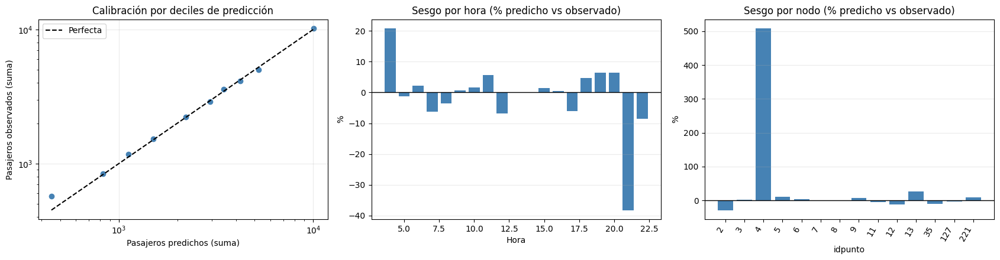

Sesgo global: -0.30%


/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


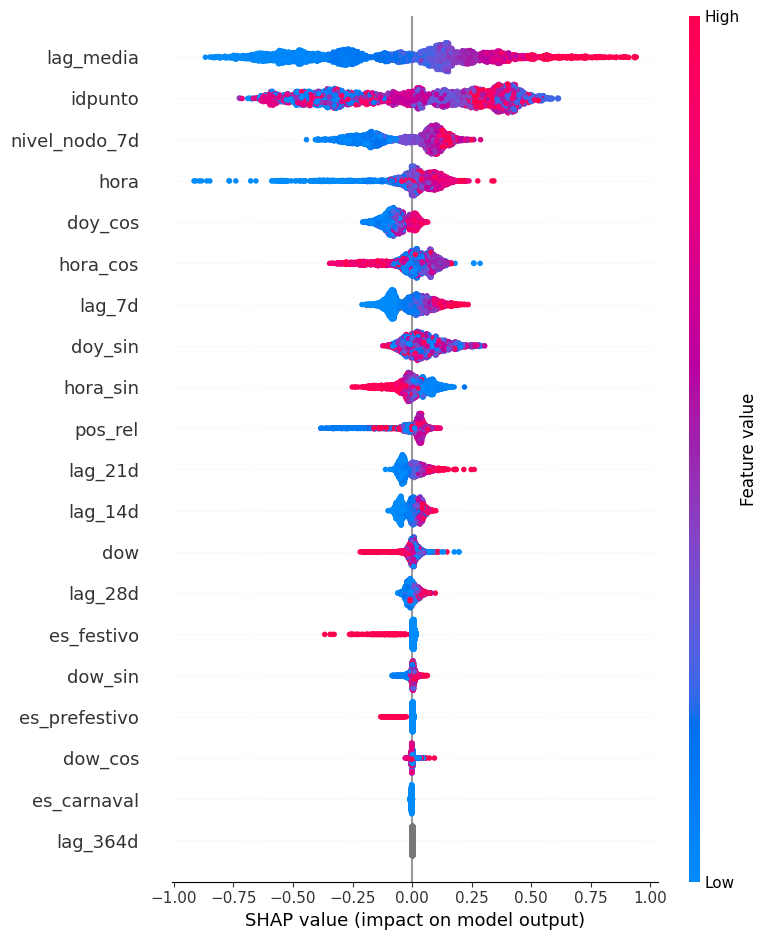

Importancia media |SHAP|:
lag_media        0.3101
idpunto          0.2971
nivel_nodo_7d    0.1339
hora             0.0825
doy_cos          0.0690
hora_cos         0.0687
lag_7d           0.0682
doy_sin          0.0666
hora_sin         0.0514
pos_rel          0.0460
lag_21d          0.0383
lag_14d          0.0327
dow              0.0188
lag_28d          0.0177
es_festivo       0.0103
dow_sin          0.0102
es_prefestivo    0.0058
dow_cos          0.0041
es_carnaval      0.0028
lag_364d         0.0000


In [ ]:
comp['pred_conteo'] = comp['pred'] * comp['viajes']
comp['decil'] = pd.qcut(comp['pred'], 10, duplicates='drop')

def sesgo(t):
    t = t[t['real'] > 0]
    return 100 * (t['pred'] / t['real'] - 1)

cal = comp.groupby('decil', observed=True).agg(pred=('pred_conteo', 'sum'), real=('subidas', 'sum'))
por_hora = comp.groupby('hora').agg(pred=('pred_conteo', 'sum'), real=('subidas', 'sum'))
por_nodo = comp.groupby('idpunto').agg(pred=('pred_conteo', 'sum'), real=('subidas', 'sum'))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

ax = axes[0]
ax.scatter(cal['pred'], cal['real'], color='steelblue')
lim = [cal[['pred', 'real']].min().min(), cal[['pred', 'real']].max().max()]
ax.plot(lim, lim, 'k--', label='Perfecta')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_title('Calibración por deciles de predicción')
ax.set_xlabel('Pasajeros predichos (suma)'); ax.set_ylabel('Pasajeros observados (suma)')
ax.legend(); ax.grid(alpha=0.25)

ax = axes[1]
s = sesgo(por_hora)
ax.bar(s.index, s.values, color='steelblue')
ax.axhline(0, color='k', lw=1)
ax.set_title('Sesgo por hora (% predicho vs observado)')
ax.set_xlabel('Hora'); ax.set_ylabel('%'); ax.grid(alpha=0.25, axis='y')

ax = axes[2]
s = sesgo(por_nodo)
ax.bar(s.index.astype(str), s.values, color='steelblue')
ax.axhline(0, color='k', lw=1)
ax.set_title('Sesgo por nodo (% predicho vs observado)')
ax.set_xlabel('idpunto'); ax.set_ylabel('%')
plt.setp(ax.get_xticklabels(), rotation=60, ha='right')
ax.grid(alpha=0.25, axis='y')

plt.tight_layout()
plt.show()
print('Sesgo global: %+.2f%%' % (100 * (comp['pred_conteo'].sum() / comp['subidas'].sum() - 1)))

# ---- SHAP (TreeSHAP nativo de LightGBM; escala log-tasa) --------------
m_exp = entrenar(TRAIN, FEATURES, PARAMS, N_ROUNDS)
muestra = comp.sample(min(3000, len(comp)), random_state=SEED)
Xs = matriz(muestra, FEATURES)
contrib = m_exp.predict(Xs, pred_contrib=True)      # última columna = valor base

Xs_num = Xs.copy()
Xs_num['idpunto'] = Xs_num['idpunto'].cat.codes     # shap necesita numéricos para colorear
shap.summary_plot(contrib[:, :-1], Xs_num, max_display=len(FEATURES))

imp = (pd.Series(np.abs(contrib[:, :-1]).mean(axis=0), index=FEATURES)
         .sort_values(ascending=False).round(4))
print('Importancia media |SHAP|:')
print(imp.to_string())

### 3.2.7 Entrenamiento final y guardado del modelo por nodo

El modelo final se ajusta con todas las observaciones modelables del panel disponible de **enero a agosto de 2025** y se guarda en `data/r1415/modelos/lgbm_r1415.txt`, acompañado por `lgbm_r1415_meta.json`.

Los metadatos conservan las **20 características** utilizadas, las categorías de `idpunto`, los parámetros y las métricas de validación temporal. La celda verifica que el modelo recargado reproduzca sus predicciones.

Esta salida describe **subidas por viaje y por punto**. Para convertirla en un conteo de una hora histórica se necesitaría considerar la exposición observada; la demanda horaria de la ruta empleada por el optimizador se trata **por separado** en la sección 3.3.


In [ ]:
DIR_MOD = os.path.join(DATA, 'modelos')
os.makedirs(DIR_MOD, exist_ok=True)

modelo_final = entrenar(dfm, FEATURES, PARAMS, N_ROUNDS)
ruta_modelo = os.path.join(DIR_MOD, 'lgbm_r1415.txt')
modelo_final.save_model(ruta_modelo)

meta = {
    'ruta': '14 15 (idruta %d)' % RUTA_ID,
    'entrenado_con': '%s .. %s' % (dfm['dia'].min().date(), dfm['dia'].max().date()),
    'objetivo_modelo': PARAMS['objective'],
    'salida': 'pasajeros POR VIAJE en el nodo (exp(raw)); pasajeros/hora = salida * viajes HISTORICOS de esa hora',
    'horizonte_dias': H,
    'rezagos_dias': LAGS,
    'features': FEATURES,
    'categorias_idpunto': [int(c) for c in CATEGORIAS_NODO.categories],
    'hiperparametros': PARAMS,
    'n_arboles': N_ROUNDS,
    'fecha_inicio_test': str(FECHA_TEST_INI.date()),
    'rezago_anual_dias': LAG_ANUAL,
    'metricas_walk_forward_test': tabla_lgb.to_dict('records'),}

with open(os.path.join(DIR_MOD, 'lgbm_r1415_meta.json'), 'w', encoding='utf-8') as f:
    json.dump(meta, f, indent=2, ensure_ascii=False, default=str)

# Verificación: el modelo recargado debe dar las mismas predicciones
m_rec = lgb.Booster(model_file=ruta_modelo)
chk = dfm.sample(1000, random_state=SEED)
assert np.allclose(m_rec.predict(matriz(chk, FEATURES)),
                   modelo_final.predict(matriz(chk, FEATURES)))
print('Modelo guardado en', ruta_modelo)
print('OK: el modelo recargado reproduce las predicciones')

Modelo guardado en /content/drive/MyDrive/proyecto_sobusa/data/r1415/modelos/lgbm_r1415.txt
OK: el modelo recargado reproduce las predicciones


### 3.2.8 Comparación de horizontes H = 7, 3 y 1 día

El horizonte H indica **cuánta anticipación** tiene el pronóstico, no la frecuencia temporal del objetivo: en los tres casos se predice demanda por celda nodo–hora–día.

Al repetir la evaluación temporal con la información permitida para cada horizonte, la devianza de Poisson es **0,3293 (H7)**, **0,3276 (H3)** y **0,3268 (H1)**. La mejora relativa de H1 frente a H7 es de aproximadamente **0,76 %**, pequeña en esta muestra.

La comparación se acompaña del error agregado por hora y del sesgo. Para decidir si vale la pena un horizonte más corto, hay que evaluar también su efecto sobre las decisiones de frecuencia.


In [ ]:
# --- 3.2.8  Horizonte H = 7 / 3 / 1 -----------------------------------
HORIZONTES = [7, 3, 1]

def wmape_hora_ruta(p, col='pred'):
    """Error ponderado de la demanda por (dia, hora) sumando nodos: lo que ve el optimizador."""
    g = (p.assign(_pc=p[col] * p['viajes'])
          .groupby(['dia', 'hora']).agg(real=('subidas', 'sum'), pred=('_pc', 'sum')))
    return 100 * (g['pred'] - g['real']).abs().sum() / g['real'].sum()

def sesgo_pct(p, col='pred'):
    return 100 * ((p[col] * p['viajes']).sum() / p['subidas'].sum() - 1)

filas, preds_h = [], {}
for h in HORIZONTES:
    dfm_h = construir_features(df, lags=lags_para(h), h=h)
    _, _, feats_h = conjuntos_features(h)
    p = walk_forward(FOLDS_TEST, feats_h, PARAMS, N_ROUNDS, datos=dfm_h)
    p = p.merge(base_wf, on=['idpunto', 'hora', 'dia'], how='inner')
    assert len(p) == len(base_wf), 'las filas de test no coinciden'
    preds_h[h] = p
    filas.append(dict(modelo='LightGBM H=%d' % h, n_features=len(feats_h), **evaluar(p),
                      wMAPE_hora_ruta=wmape_hora_ruta(p), sesgo_pct=sesgo_pct(p)))

ref = preds_h[HORIZONTES[0]]
for nombre, col in [('B1 media historica', 'b1'), ('N7 valor de hace 7 dias', 'naive7')]:
    filas.append(dict(modelo=nombre, n_features=0, **evaluar(ref, col),
                      wMAPE_hora_ruta=wmape_hora_ruta(ref, col), sesgo_pct=sesgo_pct(ref, col)))

tabla_h = pd.DataFrame(filas).round(4).sort_values('PoissonDev').reset_index(drop=True)
display(tabla_h)

dev = tabla_h.set_index('modelo')['PoissonDev']
print('Mejora de devianza H=1 vs H=7: %.2f%%' % (100 * (1 - dev['LightGBM H=1'] / dev['LightGBM H=7'])))
print('Mejora de devianza H=3 vs H=7: %.2f%%' % (100 * (1 - dev['LightGBM H=3'] / dev['LightGBM H=7'])))


,modelo,n_features,MAE,RMSE,PoissonDev,MAE_conteo,wMAPE_hora_ruta,sesgo_pct
0,LightGBM H=1,23,0.2340,0.4709,0.3268,1.6055,29.3132,-1.4936
1,LightGBM H=3,21,0.2356,0.4733,0.3276,1.6228,29.5876,-0.7876
2,LightGBM H=7,20,0.2368,0.4753,0.3293,1.6337,29.7678,-0.2951
3,B1 media historica,0,0.2590,0.4861,0.3565,1.8264,37.5910,23.2333
4,N7 valor de hace 7 dias,0,0.3068,0.6220,1.9227,2.1784,44.0915,7.8435


Mejora de devianza H=1 vs H=7: 0.76%
Mejora de devianza H=3 vs H=7: 0.52%


## 3.3 Demanda horaria de ruta para el optimizador

El LightGBM anterior predice subidas **por viaje en los 14 puntos**; el optimizador requiere una serie de **subidas por hora para toda la ruta**. Son problemas distintos y no debe multiplicarse el pronóstico de tasa por los viajes que el propio optimizador proponga.

**Fuente usada en esta ejecución:** `FUENTE_RUTA = 'panel'`. La demanda horaria de ruta **se estima** a partir del panel de nodos, calibrado con `demanda_ruta_2025.csv`, que contiene agregados medidos de ruta completa. **No se ha descargado aquí una serie diaria-horaria completa directamente desde `conteo_pasajeros_destino`.** La alternativa `FUENTE_RUTA = 'conteo'` está implementada, pero no es la utilizada en estas salidas.

La calibración informa que el panel representa aproximadamente **6,2 %** de la demanda de ruta en días laborables de 2025, con cuotas diferentes por hora. La reconstrucción amplifica el ruido de los puntos observados; por eso los resultados y sus métricas deben interpretarse como **pronósticos sobre una serie reconstruida**, no como una evaluación directa contra todas las subidas observadas de la ruta.

**Limitación adicional de validación:** la cuota de calibración se calcula usando toda la ventana **enero–agosto de 2025**, que incluye julio y agosto (el período de prueba). Aunque las características con rezagos se construyan respetando H, la reconstrucción del objetivo **no es totalmente independiente del test**. Para un backtest estrictamente prospectivo habría que estimar las cuotas solo con datos previos a cada corte o contrastar los pronósticos con la serie horaria medida directamente.

Se estudian **H7 y H1** como horizontes operativos principales, además de H3 para comparación. Se contrastan rezagos, calendario, estacionalidades y cuatro configuraciones de nivel/recencia, seleccionadas por validación temporal.


### 3.3.1 Construcción y control de la serie horaria

Se genera una malla de días de **enero–agosto de 2025** por las **19 horas de 04:00 a 22:00**. En la configuración ejecutada, la demanda por hora se reconstruye desde el panel de nodos usando cuotas calibradas por hora y día de la semana.

Se distingue entre una hora con cero eventos dentro de un día observado y un día sin información. La celda compara la serie reconstruida con los resúmenes de ruta disponibles y advierte sobre posibles inconsistencias o ruido de muestreo. Si se activara la fuente `conteo`, el procedimiento utilizaría CSV diarios-horarios extraídos directamente de PostgreSQL.


In [ ]:
# --- 3.3.1  Demanda total de ruta por (dia, hora) -----------------------------
import glob, sys

HORAS_RUTA = list(range(4, 23))                 # ventana del optimizador: 04h a 22h
DIR_RUTA = os.path.join(DATA, 'demanda_ruta_horaria')

# De donde sale la demanda de TODA la ruta por (dia, hora):
#   'panel'  : se reconstruye con el panel de 15 nodos que ya esta descargado (df), calibrado contra la
#              ruta completa que ya se midio (demanda_ruta_2025.csv y la medicion de 2023). No consulta la base.
#   'conteo' : se descarga de la base (conteo_pasajeros_destino) con scripts/extraer_demanda_ruta_horaria_r1415.py.
#              Es la medicion real, pero pesada: lee casi todos los eventos de la ruta.
FUENTE_RUTA = 'panel'
EXTRAER_DESDE_NOTEBOOK = False                  # solo se usa con FUENTE_RUTA = 'conteo'

def _ns(s):
    """Fechas siempre en datetime64[ns]: evita incompatibilidades de resolucion al unir tablas."""
    return pd.to_datetime(s).astype('datetime64[ns]')

def tipo_dia_de(dias):
    """'lab' (lun-vie no festivo), 'sab', 'dom_fest' (domingo o festivo de Colombia)."""
    dias = pd.Series(pd.to_datetime(dias)).reset_index(drop=True)
    fest = pd.to_datetime(list(holidays.country_holidays('CO', years=sorted(dias.dt.year.unique())).keys()))
    dow = dias.dt.dayofweek
    return np.where(dias.isin(fest) | (dow == 6), 'dom_fest', np.where(dow == 5, 'sab', 'lab'))

def _malla(dias, columnas):
    """Malla completa dias x 19 horas con las columnas dadas (hora sin datos = NaN, se rellena aparte)."""
    return (pd.MultiIndex.from_product([pd.DatetimeIndex(sorted(dias)), HORAS_RUTA], names=['dia', 'hora'])
              .to_frame(index=False).merge(columnas, on=['dia', 'hora'], how='left'))

f_hist = os.path.join(DATA, 'demanda_ruta_2025.csv')
f_res = os.path.join(DATA, 'pico_carga_por_hora_resumen.json')

if FUENTE_RUTA == 'conteo':
    # ---------------------------------------------------------------- medicion real desde la base
    if EXTRAER_DESDE_NOTEBOOK:
        import importlib
        sys.path.insert(0, os.path.join(PROY, 'scripts'))
        import extraer_demanda_ruta_horaria_r1415 as ext_ruta
        ext_ruta = importlib.reload(ext_ruta)          # Python guarda el modulo en memoria: sin esto se sigue usando la version vieja
        ext_ruta.extraer(CONN, '2023-01', df['dia'].max().strftime('%Y-%m'), salida=DIR_RUTA)

    archivos = sorted(glob.glob(os.path.join(DIR_RUTA, 'demanda_ruta_horaria_*.csv')))
    if not archivos:
        raise FileNotFoundError(
            'No hay CSV en %s.\nGenerarlos con:\n'
            '  python scripts/extraer_demanda_ruta_horaria_r1415.py --desde 2023-01 --hasta AAAA-MM\n'
            'o poner EXTRAER_DESDE_NOTEBOOK = True, o usar FUENTE_RUTA = \'panel\'.' % DIR_RUTA)
    crudo = (pd.concat([pd.read_csv(f) for f in archivos], ignore_index=True)
               .drop_duplicates(['dia', 'hora'], keep='last'))
    crudo['dia'] = _ns(crudo['dia'])
    fuera = crudo.loc[~crudo['hora'].isin(HORAS_RUTA), 'subidas'].sum() / max(crudo['subidas'].sum(), 1)
    crudo = crudo[crudo['hora'].isin(HORAS_RUTA)]
    print('Fuente: conteo (medicion real). Archivos: %d | filas dia-hora: %d | %s .. %s'
          % (len(archivos), len(crudo), crudo['dia'].min().date(), crudo['dia'].max().date()))
    print('Subidas fuera de la ventana 04h-22h (se descartan): %.2f %%' % (100 * fuera))
    if 'eventos_descartados' in crudo.columns:
        print('Eventos descartados por falla del contador: %d de %d (%.4f %%)'
              % (crudo['eventos_descartados'].sum(), crudo['eventos'].sum(),
                 100 * crudo['eventos_descartados'].sum() / max(crudo['eventos'].sum(), 1)))
    # Una hora sin eventos en un dia con datos es un cero real; un dia SIN ningun dato no se inventa.
    base_ruta = _malla(crudo['dia'].unique(), crudo[['dia', 'hora', 'subidas']])
    base_ruta['dem'] = base_ruta['subidas'].fillna(0.0)
    base_ruta = base_ruta.drop(columns='subidas')

elif FUENTE_RUTA == 'panel':
    # ---------------------------------------------------------------- reconstruccion desde el panel de nodos
    # El panel (df) solo ve los eventos con idpunto: 15 paradas, ~11.7 % de los pasajeros. Si esos eventos
    # fueran una muestra proporcional de los de toda la ruta, cuota(hora, dia de la semana) = nodos / ruta, y
    #     demanda_ruta(dia, hora) = suma_de_nodos(dia, hora) / cuota(hora, dia de la semana).
    # La cuota se mide donde YA se conoce la ruta completa: demanda_ruta_2025.csv (ene-ago 2025).
    if not os.path.exists(f_hist):
        raise FileNotFoundError('Falta %s (demanda medida de la ruta, por hora y dia de la semana).' % f_hist)
    nodos_h = (df[df['hora'].isin(HORAS_RUTA)].groupby(['dia', 'hora'], as_index=False)['subidas'].sum()
                 .rename(columns={'subidas': 'nodos'}))
    nodos_h['dia'] = _ns(nodos_h['dia'])
    base_ruta = _malla(nodos_h['dia'].unique(), nodos_h)
    base_ruta['nodos'] = base_ruta['nodos'].fillna(0.0)          # hora sin eventos en los 15 nodos = 0
    base_ruta['dow_pg'] = (base_ruta['dia'].dt.dayofweek + 1) % 7   # convencion de la base: 0 = domingo ... 6 = sabado
    print('Fuente: PANEL de 15 nodos calibrado (estimacion, no medicion). Dias: %d | %s .. %s'
          % (base_ruta['dia'].nunique(), base_ruta['dia'].min().date(), base_ruta['dia'].max().date()))

    # --- cuota por (hora, dia de la semana), medida en la ventana de la ruta completa (ene-ago 2025)
    h_ = pd.read_csv(f_hist)
    h_['dow'] = h_['dow'] % 7                  # 0 = domingo (convencion de la base); un 7 ISO pasa a 0
    ruta_m = (h_['subidas'] / h_['dias'].replace(0, np.nan)).groupby([h_['hora'], h_['dow']]).mean()
    en_vent = (base_ruta['dia'] >= '2025-01-01') & (base_ruta['dia'] < '2025-09-01')
    if not en_vent.any():
        raise ValueError('El panel no tiene dias entre 2025-01-01 y 2025-08-31: no hay donde calibrar la cuota.')
    nod_m = base_ruta[en_vent].groupby(['hora', 'dow_pg'])['nodos'].mean()
    nod_m.index.names = ['hora', 'dow']
    cuota = (nod_m / ruta_m).reindex(pd.MultiIndex.from_product([HORAS_RUTA, range(7)], names=['hora', 'dow']))
    cuota = cuota.where((cuota > 0.02) & (cuota < 0.5))              # celdas sin datos o absurdas
    cuota = cuota.fillna(cuota.groupby(level='hora').transform('median')).fillna(cuota.median())
    base_ruta = base_ruta.merge(cuota.rename('cuota').reset_index().rename(columns={'dow': 'dow_pg'}),
                                on=['hora', 'dow_pg'], how='left')
    base_ruta['dem'] = base_ruta['nodos'] / base_ruta['cuota']

    # --- que tan estable es la cuota (lo que decide si la reconstruccion sirve)
    lab = [1, 2, 3, 4, 5]
    nl = nod_m[nod_m.index.get_level_values('dow').isin(lab)].groupby(level='hora').mean()
    rl = ruta_m[ruta_m.index.get_level_values('dow').isin(lab)].groupby(level='hora').mean()
    c_lab = (nl / rl).reindex(HORAS_RUTA)
    print('\nCuota del panel de nodos sobre la ruta completa, dia laborable (ene-ago 2025):')
    print('  total del dia: %.1f %%   | por hora, de %.1f %% a %.1f %% (horas 5-20)'
          % (100 * nl.sum() / rl.sum(), 100 * c_lab.loc[5:20].min(), 100 * c_lab.loc[5:20].max()))
    print('  hora:  ' + ' '.join('%5d' % h for h in (5, 6, 8, 10, 12, 14, 17, 19, 21)))
    print('  cuota: ' + ' '.join('%4.1f%%' % (100 * c_lab[h]) for h in (5, 6, 8, 10, 12, 14, 17, 19, 21)))

    # --- ruido esperado: los eventos de las paradas son una MUESTRA de los de la ruta; escalar por 1/cuota
    # amplifica el ruido de muestreo: sd relativa = sqrt((1 - p) / (p * T)) (supone muestreo proporcional)
    ruido = 100 * np.sqrt((1 - c_lab) / (c_lab * rl.reindex(HORAS_RUTA)))
    print('\nRuido de muestreo esperado de la reconstruccion por hora (% de la demanda, supuesto binomial):')
    print('  ' + ' '.join('%dh: %.0f%%' % (h, ruido[h]) for h in (6, 8, 12, 17, 21)))
    print('  (en el total del dia el ruido baja a ~%.0f %%)' % (100 * np.sqrt((1 - nl.sum() / rl.sum()) / (nl.sum() / rl.sum() * rl.sum()))))

    # --- ¿la cuota de 2023 es la de 2025? segundo punto medido de la ruta completa: ene-feb 2023
    if os.path.exists(f_res):
        ruta23 = json.load(open(f_res, encoding='utf-8')).get('subidas_dia_conteo_2023')
        e23 = (base_ruta['dia'] >= '2023-01-01') & (base_ruta['dia'] < '2023-03-01') & base_ruta['dow_pg'].isin(lab)
        if ruta23 and e23.any():
            c23 = base_ruta[e23].groupby('dia')['nodos'].sum().mean() / ruta23
            c25 = nl.sum() / rl.sum()
            print('\nCuota del dia laborable: ene-feb 2023 = %.1f %% | ene-ago 2025 = %.1f %% | cociente 2023/2025 = %.2f'
                  % (100 * c23, 100 * c25, c23 / c25))
            if abs(c23 / c25 - 1) > 0.10:
                print('REVISAR: la cuota cambio mas de 10 %% entre 2023 y 2025. Reconstruir 2023-24 con la cuota de 2025 sesgaria'
                      ' esa demanda en %+.0f %% (negativo = la subestima).' % (100 * (c23 / c25 - 1)))
            else:
                print('OK: la cuota es estable entre 2023 y 2025 (dentro de 10 %).')

    # --- si ya hay meses reales descargados, se mide el error de la reconstruccion contra ellos
    arch_real = sorted(glob.glob(os.path.join(DIR_RUTA, 'demanda_ruta_horaria_*.csv')))
    if arch_real:
        real = pd.concat([pd.read_csv(f) for f in arch_real]).drop_duplicates(['dia', 'hora'], keep='last')
        real['dia'] = _ns(real['dia'])
        m = base_ruta.merge(real[['dia', 'hora', 'subidas']], on=['dia', 'hora'])
        if len(m):
            e = (m['dem'] - m['subidas']).abs()
            d = m.groupby('dia').agg(r=('subidas', 'sum'), e=('dem', 'sum'))
            print('\nERROR DE LA RECONSTRUCCION contra la medicion real (%d dias descargados):' % d.shape[0])
            print('  por hora: wMAPE %.1f %% | sesgo %+.1f %% | por dia: MAPE %.1f %%'
                  % (100 * e.sum() / m['subidas'].sum(), 100 * (m['dem'].sum() / m['subidas'].sum() - 1),
                     100 * ((d['e'] - d['r']).abs() / d['r']).mean()))
    base_ruta = base_ruta.drop(columns=['nodos', 'dow_pg', 'cuota'])
else:
    raise ValueError("FUENTE_RUTA debe ser 'panel' o 'conteo'")

dias_con_datos = pd.DatetimeIndex(sorted(base_ruta['dia'].unique()))
calendario = pd.date_range(dias_con_datos.min(), dias_con_datos.max())
faltan = calendario.difference(dias_con_datos)
print('\nDias del calendario sin ningun dato: %d %s' % (len(faltan),
      [str(d.date()) for d in faltan[:8]] + (['...'] if len(faltan) > 8 else [])))

base_ruta['tipo_dia'] = tipo_dia_de(base_ruta['dia'])

# --- limpieza: un valor mayor que 3 veces el p99 de su (hora, tipo de dia) es una falla del
# contador. Se pone en NaN (no en cero) para que no contamine rezagos ni entrenamiento.
# Se usa p99 y no p99.9: con unos cientos de filas por grupo, el p99.9 es la propia falla y
# nunca la detecta (probado con fallas inyectadas).
q99 = base_ruta.groupby(['hora', 'tipo_dia'])['dem'].transform(lambda s: s.quantile(0.99))
atipico = base_ruta['dem'] > np.maximum(3 * q99, 50)
base_ruta.loc[atipico, 'dem'] = np.nan
print('Celdas dia-hora atipicas puestas en NaN: %d de %d (%.3f %%)'
      % (atipico.sum(), len(base_ruta), 100 * atipico.mean()))

# --- diagnostico: dias con demanda muy baja frente a su propio dia de la semana
tot_dia = base_ruta.groupby('dia')['dem'].sum()
rel_dia = (tot_dia / tot_dia.groupby(tot_dia.index.dayofweek).transform('median')).sort_values()
print('\nLos 8 dias de menor demanda relativa a la mediana de su dia de la semana:')
print('(un festivo real baja mucho; una falla de conteo tambien: revisar los que no sean festivo)')
fest_chk = tipo_dia_de(pd.Series(rel_dia.head(8).index))
print(pd.DataFrame({'razon': rel_dia.head(8).round(2).values,
                    'tipo_dia': fest_chk}, index=[d.date() for d in rel_dia.head(8).index]).to_string())


if FUENTE_RUTA == 'conteo':
    # --- validacion contra el archivo que usa hoy el optimizador
    f_hist = os.path.join(DATA, 'demanda_ruta_2025.csv')
    if os.path.exists(f_hist):
        h_ = pd.read_csv(f_hist)
        h_ = h_[(h_['dow'] >= 1) & (h_['dow'] <= 5)].copy()
        h_['sub_dia'] = h_['subidas'] / h_['dias'].replace(0, np.nan)
        ref = h_.groupby('hora')['sub_dia'].mean()
        sel = (base_ruta['dia'] >= '2025-01-01') & (base_ruta['dia'] <= '2025-08-31') & (base_ruta['dia'].dt.dayofweek < 5)
        mio = base_ruta[sel].groupby('hora')['dem'].mean()
        comp = pd.DataFrame({'archivo_optimizador': ref, 'esta_serie': mio}).reindex(HORAS_RUTA)
        comp['cociente'] = comp['esta_serie'] / comp['archivo_optimizador']
        print('\nPromedio de dia laborable ene-ago 2025: esta serie vs demanda_ruta_2025.csv')
        print(comp.round(2).to_string())
        c_tot = comp['esta_serie'].sum() / comp['archivo_optimizador'].sum()
        print('\nCociente total: %.3f' % c_tot)
        # el total puede cuadrar y haber horas rotas (una falla de contador en una hora): se mira hora por hora
        malas = comp[((comp['cociente'] < 0.85) | (comp['cociente'] > 1.15)) & ~comp.index.isin([21, 22])]
        if len(malas):
            print('REVISAR horas con cociente fuera de 0.85-1.15 (21h y 22h se excluyen: ahi pesa que las horas sin eventos '
                  'cuenten como cero): %s' % list(malas.index))
        if abs(c_tot - 1) > 0.05:
            print('REVISAR: difieren mas de 5 %. Causas probables: el filtro de viajes cancelados, la definicion de'
                  ' `subidas` del CSV, o que el CSV promedie solo los dias con eventos en cada hora'
                  ' (aqui las horas sin eventos cuentan como cero; afecta sobre todo a 21h-22h).')
        elif not len(malas):
            print('OK: la serie reproduce el archivo que ya usa el optimizador (total dentro de 5 % y cada hora dentro de 15 %).')
    else:
        print('\n(no se encontro %s: se omite la validacion cruzada)' % f_hist)


base_ruta.head()


Fuente: PANEL de 15 nodos calibrado (estimacion, no medicion). Dias: 236 | 2025-01-01 .. 2025-08-30

Cuota del panel de nodos sobre la ruta completa, dia laborable (ene-ago 2025):
  total del dia: 6.2 %   | por hora, de 4.3 % a 8.2 % (horas 5-20)
  hora:      5     6     8    10    12    14    17    19    21
  cuota:  8.2%  6.1%  6.2%  5.8%  6.9%  6.6%  7.2%  5.1%  0.2%

Ruido de muestreo esperado de la reconstruccion por hora (% de la demanda, supuesto binomial):
  6h: 12% 8h: 15% 12h: 15% 17h: 12% 21h: 153%
  (en el total del dia el ruido baja a ~4 %)

Dias del calendario sin ningun dato: 6 ['2025-02-28', '2025-03-31', '2025-04-30', '2025-05-31', '2025-06-30', '2025-07-31']
Celdas dia-hora atipicas puestas en NaN: 1 de 4484 (0.022 %)

Los 8 dias de menor demanda relativa a la mediana de su dia de la semana:
(un festivo real baja mucho; una falla de conteo tambien: revisar los que no sean festivo)
            razon  tipo_dia
2025-01-01   0.20  dom_fest
2025-04-18   0.29  dom_fest
2025

,dia,hora,dem,tipo_dia
0,2025-01-01,4,0.000000,dom_fest
1,2025-01-01,5,13.200803,dom_fest
2,2025-01-01,6,48.650133,dom_fest
3,2025-01-01,7,123.115130,dom_fest
4,2025-01-01,8,79.827884,dom_fest


### 3.3.2 Calendario de estacionalidades

`estacionalidades_anio` contiene **231 registros** y permite construir banderas de festivos, fiestas regionales, temporadas nacionales y fiestas patronales. El calendario expandido cubre **2017-01-01 a 2026-12-25**. Para los **236 días** del panel de 2025, el recuento de días marcados es: **11** festivos nacionales, **10** de `FIESTA_ATLANTICO`, **8** de `TEMPORADA_NACIONAL` y **1** de `FIESTAS_PATRONALES`; **208** quedan sin ninguna de estas marcas.

Se incorporan tanto las banderas como la posición del día dentro de temporadas largas. Estas variables son conocidas anticipadamente **solo si el calendario representa una planificación publicada antes de las fechas**. La comprobación contra la librería `holidays` contrasta festivos, pero no garantiza por sí sola la ausencia de información incorporada retrospectivamente.


In [ ]:
# --- 3.3.2  Calendario de estacionalidades (tabla estacionalidades_anio) ------------
USAR_ESTAC = True            # False: omite estas features (por si la tabla no se puede interpretar)
TIPOS_ESTAC = ['FESTIVO_NACIONAL', 'FIESTA_ATLANTICO', 'TEMPORADA_NACIONAL', 'FIESTAS_PATRONALES']
# DIAS_CORRIENTES no es una bandera: son los dias que no caen en ninguno de los cuatro.

def _leer_tablas_estac():
    """Devuelve (estacionalidades_anio, estacionalidades). La primera vez las baja de la base
    (231 y 24 filas) y las guarda en data/ para no volver a consultar."""
    p_ea = os.path.join(DATA, 'estacionalidades_anio.csv')
    p_es = os.path.join(DATA, 'estacionalidades.csv')
    if os.path.exists(p_ea) and os.path.exists(p_es):
        return pd.read_csv(p_ea), pd.read_csv(p_es)
    ea = consulta('SELECT * FROM estacionalidades_anio')
    es = consulta('SELECT * FROM estacionalidades')
    ea.to_csv(p_ea, index=False)
    es.to_csv(p_es, index=False)
    return ea, es

def _col(tabla, fragmentos):
    for frag in fragmentos:
        for c in tabla.columns:
            if frag in c.lower():
                return c
    return None

def construir_calendario_estac(ea, es):
    """Una fila por dia con banderas por tipo, cantidad de tipos activos y posicion dentro de la
    temporada larga que cubre el dia. Las columnas se DETECTAN (el notebook solo documentaba que la
    tabla tiene 6 columnas); si no se reconocen, falla con un mensaje que las muestra."""
    col_nombre = next((c for c in es.columns
                       if es[c].astype(str).isin(TIPOS_ESTAC + ['DIAS_CORRIENTES']).any()), None)
    col_id_es = 'id_estacionalidad' if 'id_estacionalidad' in es.columns else _col(es, ['id'])
    col_ini, col_fin = _col(ea, ['inicio', 'desde']), _col(ea, ['fin', 'hasta'])
    col_dia = _col(ea, ['fecha']) if not (col_ini and col_fin) else None
    if (col_nombre is None or col_id_es is None or 'id_estacionalidad' not in ea.columns
            or not ((col_ini and col_fin) or col_dia)):
        raise ValueError(
            'No pude interpretar las tablas de estacionalidad.\n'
            'estacionalidades_anio columnas: %s\n%s\n\nestacionalidades columnas: %s\n%s\n'
            'Se espera: en _anio un id_estacionalidad y fechas (inicio/fin o una fecha); en la otra el nombre del tipo.\n'
            'Ajustar los nombres arriba o poner USAR_ESTAC = False.'
            % (list(ea.columns), ea.head(3).to_string(), list(es.columns), es.head(3).to_string()))

    tipos = es[[col_id_es, col_nombre]].rename(columns={col_id_es: 'id_estacionalidad', col_nombre: 'tipo'})
    r = ea.merge(tipos, on='id_estacionalidad', how='left')
    if col_ini and col_fin:
        r['_ini'], r['_fin'] = _ns(r[col_ini]), _ns(r[col_fin])
    else:
        r['_ini'] = r['_fin'] = _ns(r[col_dia])
    malas = r['_ini'].isna() | r['_fin'].isna() | (r['_fin'] < r['_ini'])
    if malas.any():
        print('AVISO: %d filas de estacionalidades_anio con fechas invalidas se ignoran' % malas.sum())
    r = r[~malas & r['tipo'].isin(TIPOS_ESTAC)]

    filas = [(d, x['tipo'], x['_ini'], x['_fin'])
             for x in r.to_dict('records') for d in pd.date_range(x['_ini'], x['_fin'])]
    d = pd.DataFrame(filas, columns=['dia', 'tipo', 'ini', 'fin'])
    d['dia'], d['ini'], d['fin'] = _ns(d['dia']), _ns(d['ini']), _ns(d['fin'])

    cobertura = pd.date_range(r['_ini'].min(), r['_fin'].max())
    flags = (d.assign(v=1).pivot_table(index='dia', columns='tipo', values='v', aggfunc='max', fill_value=0)
               .reindex(index=cobertura, columns=TIPOS_ESTAC, fill_value=0).fillna(0).astype(int))
    flags.columns = ['estac_' + c for c in flags.columns]
    flags['estac_n'] = flags.sum(axis=1)

    d['largo'] = (d['fin'] - d['ini']).dt.days + 1
    larga = d[d['largo'] >= 3].sort_values('largo', ascending=False).drop_duplicates('dia')
    pos = larga.assign(estac_dia_k=(larga['dia'] - larga['ini']).dt.days.clip(upper=60),
                       estac_faltan_k=(larga['fin'] - larga['dia']).dt.days.clip(upper=60)
                       ).set_index('dia')[['estac_dia_k', 'estac_faltan_k']]
    cal = flags.join(pos)                      # NaN fuera de una temporada larga (no hay posicion)
    cal.index = _ns(cal.index)
    cal.index.name = 'dia'
    return cal

ESTAC_COLS, ESTAC_CAL, ESTAC_FIN = [], None, None
if USAR_ESTAC:
    _ea, _es = _leer_tablas_estac()
    ESTAC_CAL = construir_calendario_estac(_ea, _es)
    ESTAC_COLS = list(ESTAC_CAL.columns)
    ESTAC_FIN = ESTAC_CAL.index.max()

    print('estacionalidades_anio: %d filas | tipos: %s' % (len(_ea), sorted(_es.astype(str).stack().loc[lambda s: s.isin(TIPOS_ESTAC + ['DIAS_CORRIENTES'])].unique())))
    print('Calendario por dia: %s .. %s (%d dias)' % (ESTAC_CAL.index.min().date(), ESTAC_FIN.date(), len(ESTAC_CAL)))
    en_panel = ESTAC_CAL.reindex(base_ruta['dia'].drop_duplicates())
    print('\nDias del panel (%d) con cada tipo activo:' % len(en_panel))
    print((en_panel[[c for c in ESTAC_COLS if c.startswith('estac_') and c not in ('estac_n', 'estac_dia_k', 'estac_faltan_k')]]
           .sum().astype(int)).to_string())
    print('Dias del panel sin ningun tipo (DIAS_CORRIENTES): %d | fuera de la cobertura de la tabla: %d'
          % ((en_panel['estac_n'] == 0).sum(), en_panel['estac_n'].isna().sum()))

    # prueba de cordura: FESTIVO_NACIONAL deberia coincidir con la libreria holidays
    anios_c = sorted(set(ESTAC_CAL.index.year))
    lib = set(pd.to_datetime(list(holidays.country_holidays('CO', years=anios_c).keys())))
    lib = {d for d in lib if ESTAC_CAL.index.min() <= d <= ESTAC_FIN}
    tab = set(ESTAC_CAL.index[ESTAC_CAL['estac_FESTIVO_NACIONAL'] == 1])
    prec = len(tab & lib) / max(len(tab), 1)
    reca = len(tab & lib) / max(len(lib), 1)
    print('\nFESTIVO_NACIONAL vs libreria holidays: %.0f %% de los dias de la tabla son festivos reales, '
          'y la tabla recoge el %.0f %% de los festivos' % (100 * prec, 100 * reca))
    if prec < 0.9:
        print('REVISAR: la tabla no parece un calendario de festivos nacionales; confirmar como se leen sus columnas.')
    print('RECUERDA: confirmar que el calendario se publica ANTES de los dias (si se etiqueto despues, hay fuga).')


estacionalidades_anio: 231 filas | tipos: ['DIAS_CORRIENTES', 'FESTIVO_NACIONAL', 'FIESTAS_PATRONALES', 'FIESTA_ATLANTICO', 'TEMPORADA_NACIONAL']
Calendario por dia: 2017-01-01 .. 2026-12-25 (3646 dias)

Dias del panel (236) con cada tipo activo:
estac_FESTIVO_NACIONAL      11
estac_FIESTA_ATLANTICO      10
estac_TEMPORADA_NACIONAL     8
estac_FIESTAS_PATRONALES     1
Dias del panel sin ningun tipo (DIAS_CORRIENTES): 208 | fuera de la cobertura de la tabla: 0

FESTIVO_NACIONAL vs libreria holidays: 100 % de los dias de la tabla son festivos reales, y la tabla recoge el 100 % de los festivos
RECUERDA: confirmar que el calendario se publica ANTES de los dias (si se etiqueto despues, hay fuga).


### 3.3.3 Características de la serie horaria

Con horizonte H, una característica basada en demanda solo puede utilizar observaciones de **H días o más atrás**.

- **Rezagos por hora:** 7, 14, 21 y 28 días; con horizontes menores se habilitan otros rezagos que respeten la antelación.
- **Nivel reciente de 28 días (`nivel28`):** resume demanda previa para distinguir nivel y forma horaria.
- **Relaciones respecto al nivel:** `lagrel_k` compara cada valor pasado con su referencia reciente.
- **Calendario:** día y hora, festivos, Carnaval, ciclo anual y banderas de estacionalidad.
- **Rezago anual de 364 días:** se incluye entre los candidatos, pero está **completamente vacío** en esta serie de solo ocho meses.

Las cuatro alternativas de tratamiento del nivel son: sin corrección, **pesos por recencia**, nivel como **offset** y combinación de ambos. Aunque el código contempla años anteriores, la ejecución actual **solo dispone de datos diarios-horarios reconstruidos de 2025**, por lo que no evalúa realmente el efecto de incorporar registros de 2023 o 2024.


In [ ]:
# --- 3.3.3  Features de la serie de ruta --------------------------------------------
NIVEL_VENTANA = 28            # dias corridos: cuatro semanas completas
NIVEL_MIN_DIAS = 14           # minimo de dias validos dentro de la ventana
N_HORAS = len(HORAS_RUTA)

def construir_features_ruta(base, h, estac=None, lags=None):
    """base: columnas dia, hora, dem (NaN = atipico o dia futuro). Devuelve base + features de
    horizonte h. Cada rezago se une por FECHA, asi que un hueco en el panel queda en NaN."""
    lags = lags_para(h) if lags is None else list(lags)
    out = base[['dia', 'hora', 'dem']].copy()
    out['dia'] = _ns(out['dia'])
    out = out.sort_values(['dia', 'hora']).reset_index(drop=True)
    assert not out.duplicated(['dia', 'hora']).any(), 'claves duplicadas'

    # nivel de los ultimos 28 dias, disponible h dias antes (calendario completo, futuro incluido)
    g = out.groupby('dia')['dem']
    tot = g.sum(min_count=1).where(g.count() == g.size())          # NaN si falta alguna hora
    cal = pd.date_range(out['dia'].min(), out['dia'].max())
    nivel = tot.reindex(cal).shift(h).rolling(NIVEL_VENTANA, min_periods=NIVEL_MIN_DIAS).mean()
    out['nivel28'] = out['dia'].map(nivel)
    out['rel'] = out['dem'] / out['nivel28'].where(out['nivel28'] > 0)

    # rezagos exactos de la misma hora, en valor y relativos a su nivel de entonces
    src = out[['dia', 'hora', 'dem', 'rel']]
    for k in list(lags) + [LAG_ANUAL]:
        s = (src.assign(dia=src['dia'] + pd.Timedelta(days=k))
                .rename(columns={'dem': f'lag_{k}d', 'rel': f'lagrel_{k}d'}))
        out = out.merge(s, on=['dia', 'hora'], how='left')
    for pref in ('lag', 'lagrel'):
        cols = [f'{pref}_{k}d' for k in lags]
        out[f'{pref}_media'] = out[cols].mean(axis=1).where(out[cols].notna().sum(axis=1) >= 2)
    c4 = [f'lag_{k}d' for k in (7, 14, 21, 28)]                     # linea base M4: promedio de 4 mismos dias
    if all(c in out.columns for c in c4):
        out['m4'] = out[c4].mean(axis=1).where(out[c4].notna().sum(axis=1) >= 2)

    # calendario (se conoce de antemano)
    out['dow'] = out['dia'].dt.dayofweek
    out['hora_sin'] = np.sin(2 * np.pi * out['hora'] / 24)
    out['hora_cos'] = np.cos(2 * np.pi * out['hora'] / 24)
    out['dow_sin'] = np.sin(2 * np.pi * out['dow'] / 7)
    out['dow_cos'] = np.cos(2 * np.pi * out['dow'] / 7)
    anios = sorted(out['dia'].dt.year.unique())
    fest = pd.to_datetime(list(holidays.country_holidays('CO', years=anios).keys()))
    out['es_festivo'] = out['dia'].isin(fest).astype(int)
    out['es_prefestivo'] = (out['dia'] + pd.Timedelta(days=1)).isin(fest).astype(int)
    out['es_carnaval'] = out['dia'].isin(dias_carnaval(anios)).astype(int)
    doy = out['dia'].dt.dayofyear
    out['doy_sin'] = np.sin(2 * np.pi * doy / 365.25)
    out['doy_cos'] = np.cos(2 * np.pi * doy / 365.25)
    out['tipo_dia'] = np.where((out['es_festivo'] == 1) | (out['dow'] == 6), 'dom_fest',
                               np.where(out['dow'] == 5, 'sab', 'lab'))
    if estac is not None:
        out = out.merge(estac, left_on='dia', right_index=True, how='left')
    return out

def feats_ruta(h, modo='raw', usar_estac=True):
    """modo 'raw': rezagos en pasajeros. modo 'offset': rezagos relativos al nivel (el nivel entra por el offset)."""
    pref = 'lag' if modo == 'raw' else 'lagrel'
    lag = [f'{pref}_{k}d' for k in lags_para(h)] + [f'{pref}_{LAG_ANUAL}d', f'{pref}_media', 'nivel28']
    return ['hora', 'dow'] + CAL_FEATS + (ESTAC_COLS if usar_estac else []) + lag

_t = construir_features_ruta(base_ruta, 7, ESTAC_CAL if USAR_ESTAC else None)
print('Ejemplo H=7: %d filas x %d columnas | features modo raw: %d | modo offset: %d'
      % (len(_t), _t.shape[1], len(feats_ruta(7, 'raw', USAR_ESTAC)), len(feats_ruta(7, 'offset', USAR_ESTAC))))
print('\n%% de NaN por feature (H=7, modo raw):')
print((_t[feats_ruta(7, 'raw', USAR_ESTAC)].isna().mean() * 100).round(1).loc[lambda s: s > 0].to_string())


Ejemplo H=7: 4484 filas x 36 columnas | features modo raw: 25 | modo offset: 25

%% de NaN por feature (H=7, modo raw):
estac_dia_k        92.4
estac_faltan_k     92.4
lag_7d              5.5
lag_14d             8.5
lag_21d            11.5
lag_28d            14.4
lag_364d          100.0
lag_media           5.9
nivel28             8.5


### 3.3.4 Verificación de disponibilidad temporal de características

Se aplican pruebas de truncación y perturbación del objetivo para horizontes **H = 7** y **H = 1**. Los controles reportados no detectan fugas dentro del **constructor de características**; en H7, el control negativo con rezago de 6 días se identifica correctamente.

**Alcance:** estas pruebas no validan por sí solas la **calibración previa de la serie de ruta**. Como la cuota del panel se calcula con toda la ventana de 2025, incluido el test, la evaluación sigue teniendo esa limitación metodológica, descrita en 3.3.


In [ ]:
# --- 3.3.4  Verificacion de fuga de informacion en la serie de ruta ------------------
def _iguales(a, b, cols):
    a = a.sort_values(['dia', 'hora']).reset_index(drop=True)
    b = b.sort_values(['dia', 'hora']).reset_index(drop=True)
    return len(a) == len(b) and all(
        np.allclose(a[c].to_numpy(float), b[c].to_numpy(float), equal_nan=True) for c in cols)

def verificar_fuga_ruta(h):
    est = ESTAC_CAL if USAR_ESTAC else None
    cols = sorted(set(feats_ruta(h, 'raw', USAR_ESTAC) + feats_ruta(h, 'offset', USAR_ESTAC) + ['nivel28']))
    base = base_ruta[['dia', 'hora', 'dem']]
    dias = np.sort(base['dia'].unique())
    corte = pd.Timestamp(dias[int(len(dias) * 0.7)])
    limite = corte + pd.Timedelta(days=h)

    # 1) truncacion: borrar todo lo posterior al corte no cambia las features de antes del corte
    full = construir_features_ruta(base, h, est)
    trunc = construir_features_ruta(base[base['dia'] <= corte], h, est)
    assert _iguales(full[full['dia'] <= corte], trunc, cols), 'H=%d: una feature usa datos futuros' % h

    # 2) perturbacion: multiplicar por 1000 la demanda desde el corte no cambia las features
    #    de los dias anteriores a corte + h (ninguna usa datos a menos de h dias)
    pert = base.copy()
    pert.loc[pert['dia'] >= corte, 'dem'] *= 1000
    fp = construir_features_ruta(pert, h, est)
    assert _iguales(full[full['dia'] < limite], fp[fp['dia'] < limite], cols), \
        'H=%d: alguna feature usa datos de menos de %d dias' % (h, h)

    # 3) control negativo: un rezago menor que h DEBE ser detectado como fuga
    if h > 1:
        k = h - 1
        c1 = construir_features_ruta(base, h, est, lags=[k])
        c2 = construir_features_ruta(pert, h, est, lags=[k])
        assert not _iguales(c1[c1['dia'] < limite], c2[c2['dia'] < limite], [f'lag_{k}d']), \
            'la prueba no detecta fugas: revisar'
    print('OK H=%d: sin fuga (truncacion y perturbacion); %s' %
          (h, 'el control negativo detecta un rezago de %d dia(s)' % (h - 1) if h > 1
           else 'control negativo omitido (con H=1 no hay rezago menor)'))

for _h in (7, 1):
    verificar_fuga_ruta(_h)


OK H=7: sin fuga (truncacion y perturbacion); el control negativo detecta un rezago de 6 dia(s)
OK H=1: sin fuga (truncacion y perturbacion); control negativo omitido (con H=1 no hay rezago menor)


### 3.3.5 Entrenamiento, líneas base y evaluación temporal

La validación sigue un esquema *walk-forward* con ventana expansiva; los modelos se reentrenan semanalmente y se pronostican los días permitidos por cada horizonte.

Se calcula **wMAPE horario**, sesgo porcentual, **MAPE del total diario** y MAE por hora. Las líneas base son `N7` (mismo día de la semana anterior), `M4` (media de los cuatro días semanales equivalentes) y `B1` (media histórica por hora y tipo de día).

En esta corrida, los pronósticos y las métricas se refieren a la **serie reconstruida a partir del panel de nodos**. El rendimiento contra una medición horaria completa de la ruta queda pendiente de una validación independiente con la fuente `conteo`.


In [ ]:
# --- 3.3.5  Nucleo: entrenamiento, baselines, walk-forward, metricas ----------------
import lightgbm as lgb

N_ROUNDS_RUTA = 600
PARAMS_RUTA = dict(objective='tweedie', tweedie_variance_power=1.2, learning_rate=0.03,
                   num_leaves=15, max_depth=6, min_child_samples=30,
                   feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0)
# Conservadores a proposito: la serie de ruta tiene ~18 mil filas, no 217 mil. Sin tuning todavia.

def pesos_recencia(dias, ref, vida_media):
    if vida_media is None:
        return None
    edad = (pd.Timestamp(ref) - dias).dt.days.clip(lower=0).to_numpy(float)
    return 0.5 ** (edad / vida_media)

def filas_validas(fr):
    """Filas con objetivo y con nivel disponible: las mismas para todos los modos."""
    fr = fr.dropna(subset=['dem', 'nivel28'])
    return fr[fr['nivel28'] > 0]

def entrenar_ruta(trn, feats, modo, params, n_rounds, vida_media=None, ref=None):
    trn = filas_validas(trn)
    y = trn['dem'].to_numpy(float)
    w = pesos_recencia(trn['dia'], ref if ref is not None else trn['dia'].max(), vida_media)
    c0, init = 0.0, None
    if modo == 'offset':
        base_log = np.log(trn['nivel28'].to_numpy(float) / N_HORAS)     # demanda media por hora
        ww = np.ones_like(y) if w is None else w
        c0 = float(np.log((ww * y).sum() / (ww * np.exp(base_log)).sum()))   # equivale a boost_from_average
        init = base_log + c0
    p = dict(params, verbose=-1, seed=SEED, deterministic=True, force_row_wise=True)
    booster = lgb.train(p, lgb.Dataset(trn[feats], y, weight=w, init_score=init), num_boost_round=n_rounds)
    return dict(booster=booster, feats=feats, modo=modo, c0=c0)

def predecir_ruta(m, tst):
    raw = m['booster'].predict(tst[m['feats']], raw_score=True)
    if m['modo'] == 'offset':
        raw = raw + np.log(tst['nivel28'].to_numpy(float) / N_HORAS) + m['c0']
    return np.exp(raw)

def folds_semanales(primer_origen, ultimo_dia):
    """Origen T: entrena con dia <= T y predice T+1 ... T+7. Reentrena cada 7 dias para cualquier H."""
    folds, T = [], pd.Timestamp(primer_origen)
    while T < ultimo_dia:
        folds.append((T, T + pd.Timedelta(days=1), min(T + pd.Timedelta(days=7), ultimo_dia)))
        T += pd.Timedelta(days=7)
    return folds

def walk_forward_ruta(fr, folds, feats, modo, params, n_rounds, vida_media=None, desde=None):
    partes = []
    for T, ini, fin in folds:
        trn = fr[fr['dia'] <= T]
        if desde is not None:
            trn = trn[trn['dia'] >= pd.Timestamp(desde)]
        tst = filas_validas(fr[(fr['dia'] >= ini) & (fr['dia'] <= fin)])
        if tst.empty or filas_validas(trn).empty:
            continue
        m = entrenar_ruta(trn, feats, modo, params, n_rounds, vida_media, ref=T)
        partes.append(tst.assign(pred=predecir_ruta(m, tst), origen=T))
    return pd.concat(partes, ignore_index=True)

def baselines_ruta(fr, folds):
    """N7, M4 y B1 sobre las mismas filas de prueba que usan los modelos."""
    out = {'N7 (misma dia semana pasada)': [], 'M4 (promedio 4 mismos dias)': [], 'B1 (media historica hora x tipo)': []}
    for T, ini, fin in folds:
        tst = filas_validas(fr[(fr['dia'] >= ini) & (fr['dia'] <= fin)])
        if tst.empty:
            continue
        b1 = (fr[fr['dia'] <= T].dropna(subset=['dem']).groupby(['hora', 'tipo_dia'])['dem']
                .mean().rename('b1').reset_index())
        t1 = tst.merge(b1, on=['hora', 'tipo_dia'], how='left')
        out['N7 (misma dia semana pasada)'].append(t1.assign(pred=t1['lag_7d']))
        out['M4 (promedio 4 mismos dias)'].append(t1.assign(pred=t1['m4']))
        out['B1 (media historica hora x tipo)'].append(t1.assign(pred=t1['b1']))
    return {k: pd.concat(v, ignore_index=True) for k, v in out.items()}

def metricas_ruta(p, col='pred'):
    p = p.dropna(subset=[col, 'dem'])
    e = p[col] - p['dem']
    d = p.groupby('dia').agg(real=('dem', 'sum'), pr=(col, 'sum'))
    d = d[d['real'] > 0]
    return {'wMAPE_hora_%': 100 * e.abs().sum() / p['dem'].sum(),
            'sesgo_%': 100 * (p[col].sum() / p['dem'].sum() - 1),
            'MAPE_dia_%': 100 * ((d['pr'] - d['real']).abs() / d['real']).mean(),
            'MAE_hora': e.abs().mean()}

def tabla_metricas(preds, claves=('dia', 'hora')):
    """Una fila por modelo, calculada solo sobre las (dia, hora) que TODOS tienen."""
    claves = list(claves)
    validos = {k: p.dropna(subset=['pred', 'dem']).set_index(claves) for k, p in preds.items()}
    comunes = None
    for p in validos.values():
        comunes = p.index if comunes is None else comunes.intersection(p.index)
    filas = []
    for k, p in validos.items():
        q = p.loc[comunes].reset_index()
        filas.append(dict(modelo=k, n_filas=len(q), **metricas_ruta(q)))
    return pd.DataFrame(filas).round(2)

# --- datos por horizonte y particion (la fecha de test es la misma que en 3.2) -------
HORIZONTES_RUTA = (7, 3, 1)
DFR = {h: construir_features_ruta(base_ruta, h, ESTAC_CAL if USAR_ESTAC else None) for h in HORIZONTES_RUTA}

ULTIMO_DIA_RUTA = base_ruta.loc[base_ruta['dem'].notna(), 'dia'].max()
DIA_FIN_TRAIN_R = base_ruta.loc[base_ruta['dia'] < FECHA_TEST_INI, 'dia'].max()
FOLDS_TEST_R = folds_semanales(DIA_FIN_TRAIN_R, ULTIMO_DIA_RUTA)
FOLDS_VAL_R = folds_semanales(DIA_FIN_TRAIN_R - pd.Timedelta(days=56), DIA_FIN_TRAIN_R)   # 8 semanas previas al test

def correr(h, modo, vida_media, folds, usar_estac=True, desde=None):
    return walk_forward_ruta(DFR[h], folds, feats_ruta(h, modo, usar_estac), modo,
                             PARAMS_RUTA, N_ROUNDS_RUTA, vida_media, desde)

print('Serie de ruta: %s .. %s | train hasta %s | test desde %s'
      % (base_ruta['dia'].min().date(), ULTIMO_DIA_RUTA.date(), DIA_FIN_TRAIN_R.date(), FECHA_TEST_INI.date()))
print('Folds de validacion (seleccion de configuracion): %d | folds de test: %d' % (len(FOLDS_VAL_R), len(FOLDS_TEST_R)))


Serie de ruta: 2025-01-01 .. 2025-08-30 | train hasta 2025-06-29 | test desde 2025-07-01
Folds de validacion (seleccion de configuracion): 8 | folds de test: 9


### 3.3.6 Comparación de configuraciones de nivel y recencia

Se prueban cuatro configuraciones con **H7**: sin corrección, pesos por recencia, nivel reciente como offset y combinación de offset con recencia. La selección utiliza **8 folds de validación** anteriores al test; después se informa el desempeño en **9 folds de prueba**.

La configuración elegida por validación es **pesos por recencia** (vida media de **180 días**), con **wMAPE de validación de 22,70 %**. Su wMAPE de prueba en la tabla de configuraciones es **23,34 %**; la opción de offset presenta **22,84 %** en prueba, pero no se selecciona utilizando el test.

En la comparación final de las mismas filas de test, LightGBM H7 obtiene **wMAPE 23,22 %**, frente a **23,05 %** de B1 y **24,53 %** de M4. Por tanto, el modelo **no supera a B1 en wMAPE horario**, aunque sí supera a M4.


In [ ]:
# --- 3.3.6  Deriva entre años ---------------------------------------------------------
HL_DIAS = 180                         # vida media de los pesos por recencia (dias)
CANDIDATOS = {'1. sin correccion':              ('raw', None),
              '2. pesos por recencia':          ('raw', HL_DIAS),
              '3. nivel reciente como offset':  ('offset', None),
              '4. offset + pesos':              ('offset', HL_DIAS)}
FORZAR_CONFIG = None                  # p. ej. '3. nivel reciente como offset' para saltarse la seleccion

filas, pred_cfg = [], {}
for nombre, (modo, hl) in CANDIDATOS.items():
    mv = metricas_ruta(correr(7, modo, hl, FOLDS_VAL_R, USAR_ESTAC))
    pt = correr(7, modo, hl, FOLDS_TEST_R, USAR_ESTAC)
    pred_cfg[nombre] = pt
    mt = metricas_ruta(pt)
    filas.append({'config': nombre, 'wMAPE_val_%': mv['wMAPE_hora_%'], 'wMAPE_test_%': mt['wMAPE_hora_%'],
                  'sesgo_test_%': mt['sesgo_%'], 'MAPE_dia_test_%': mt['MAPE_dia_%']})
tabla_deriva = pd.DataFrame(filas).round(2)
display(tabla_deriva)

ELEGIDA = FORZAR_CONFIG or tabla_deriva.loc[tabla_deriva['wMAPE_val_%'].idxmin(), 'config']
MODO, HL = CANDIDATOS[ELEGIDA]
print('Configuracion elegida con VALIDACION (8 semanas previas al test): %s  [modo=%s, vida media=%s]'
      % (ELEGIDA, MODO, HL))

print('\nLa configuracion elegida frente a las lineas base (mismas filas):')
bl_test = baselines_ruta(DFR[7], FOLDS_TEST_R)
display(tabla_metricas({**bl_test, 'LightGBM H7 - ' + ELEGIDA: pred_cfg[ELEGIDA]}))


,config,wMAPE_val_%,wMAPE_test_%,sesgo_test_%,MAPE_dia_test_%
0,1. sin correccion,22.75,23.08,-2.92,10.29
1,2. pesos por recencia,22.70,23.34,-2.46,10.41
2,3. nivel reciente como offset,22.80,22.84,-2.44,10.90
3,4. offset + pesos,23.00,23.20,-2.95,11.15


Configuracion elegida con VALIDACION (8 semanas previas al test): 2. pesos por recencia  [modo=raw, vida media=180]

La configuracion elegida frente a las lineas base (mismas filas):


,modelo,n_filas,wMAPE_hora_%,sesgo_%,MAPE_dia_%,MAE_hora
0,N7 (misma dia semana pasada),1102,30.95,-1.20,15.04,136.74
1,M4 (promedio 4 mismos dias),1102,24.53,-2.83,12.88,108.38
2,B1 (media historica hora x tipo),1102,23.05,10.75,13.07,101.81
3,LightGBM H7 - 2. pesos por recencia,1102,23.22,-2.49,10.73,102.57


### 3.3.7 Ablación de estacionalidades y disponibilidad de años históricos

Se evalúa el modelo H7 con y sin banderas de `estacionalidades_anio`. En esta prueba, el **wMAPE es 23,34 % con** estacionalidades y **23,32 % sin** ellas: no aparece una mejora en wMAPE al añadirlas, aunque otras métricas pueden variar.

El segundo experimento define ventanas de entrenamiento desde **2025**, **2024** o **2023**, pero las tres terminan usando **3.989 filas de entrenamiento**, porque la serie diaria-horaria disponible empieza en **enero de 2025**. Los resultados idénticos **no demuestran que los años previos sean irrelevantes**; indican que no se incorporaron a esta comparación.


In [ ]:
# --- 3.3.7  Aporte de estacionalidades y de los años 2023-2024 ------------------------
print('(1) Banderas de estacionalidad')
res = {'con estacionalidades': pred_cfg[ELEGIDA] if USAR_ESTAC else correr(7, MODO, HL, FOLDS_TEST_R, False)}
if USAR_ESTAC:
    res['sin estacionalidades'] = correr(7, MODO, HL, FOLDS_TEST_R, usar_estac=False)
t1 = tabla_metricas(res)
display(t1)
if USAR_ESTAC:
    a, b = t1.set_index('modelo').loc['con estacionalidades', 'wMAPE_hora_%'], t1.set_index('modelo').loc['sin estacionalidades', 'wMAPE_hora_%']
    print('Con estacionalidades el wMAPE por hora cambia %.1f %% (%.2f -> %.2f)' % (100 * (a / b - 1), b, a))

print('\n(2) ¿Con cuantos años se entrena?')
ventanas = {'entrenar con 2025 (desde ene)': '2025-01-01',
            'entrenar con 2024-2025': '2024-01-01',
            'entrenar con 2023-2025': '2023-01-01'}
pv = {n: correr(7, MODO, HL, FOLDS_TEST_R, USAR_ESTAC, desde=d) for n, d in ventanas.items()}
t2 = tabla_metricas(pv)
T_ult = FOLDS_TEST_R[-1][0]
t2['filas_de_entrenamiento'] = [len(filas_validas(DFR[7][(DFR[7]['dia'] <= T_ult) & (DFR[7]['dia'] >= pd.Timestamp(d))]))
                                for d in ventanas.values()]
display(t2)
w2 = t2.set_index('modelo')['wMAPE_hora_%']
print('wMAPE con 2023-2025 frente a solo 2025: %+.1f %%' % (100 * (w2['entrenar con 2023-2025'] / w2['entrenar con 2025 (desde ene)'] - 1)))
print('wMAPE con 2023-2025 frente a 2024-2025: %+.1f %%' % (100 * (w2['entrenar con 2023-2025'] / w2['entrenar con 2024-2025'] - 1)))


(1) Banderas de estacionalidad


,modelo,n_filas,wMAPE_hora_%,sesgo_%,MAPE_dia_%,MAE_hora
0,con estacionalidades,1140,23.34,-2.46,10.41,102.54
1,sin estacionalidades,1140,23.32,-2.28,10.70,102.47


Con estacionalidades el wMAPE por hora cambia 0.1 % (23.32 -> 23.34)

(2) ¿Con cuantos años se entrena?


,modelo,n_filas,wMAPE_hora_%,sesgo_%,MAPE_dia_%,MAE_hora,filas_de_entrenamiento
0,entrenar con 2025 (desde ene),1140,23.34,-2.46,10.41,102.54,3989
1,entrenar con 2024-2025,1140,23.34,-2.46,10.41,102.54,3989
2,entrenar con 2023-2025,1140,23.34,-2.46,10.41,102.54,3989


wMAPE con 2023-2025 frente a solo 2025: +0.0 %
wMAPE con 2023-2025 frente a 2024-2025: +0.0 %


### 3.3.8 Comparación H7, H3 y H1 en demanda de ruta

Sobre las mismas **1.102 filas** evaluables, los wMAPE horarios son **23,22 % (H7)**, **23,21 % (H3)** y **22,89 % (H1)**. H1 mejora frente a H7 alrededor de **1,4 % en términos relativos**, una diferencia pequeña.

La referencia B1 alcanza **23,05 %** y M4 **24,53 %**. En el desglose por franjas H1 mejora especialmente el valle y algunas horas punta, pero no todas las franjas: en la noche (20–22 h) registra **39,56 %**, ligeramente peor que H7 (**39,12 %**).

La sección siguiente determina si esa reducción del error se traduce realmente en decisiones de frecuencia mejores.


In [ ]:
# --- 3.3.8  Horizonte H7 / H3 / H1 sobre la demanda de ruta ---------------------------
RES_H = {h: correr(h, MODO, HL, FOLDS_TEST_R, USAR_ESTAC) for h in HORIZONTES_RUTA}
bl_h = baselines_ruta(DFR[7], FOLDS_TEST_R)
preds_h = {**bl_h, **{'LightGBM H%d' % h: p for h, p in RES_H.items()}}
tabla_h = tabla_metricas(preds_h).sort_values('wMAPE_hora_%').reset_index(drop=True)
display(tabla_h)

w = tabla_h.set_index('modelo')['wMAPE_hora_%']
print('wMAPE H1 frente a H7: %+.1f %%' % (100 * (w['LightGBM H1'] / w['LightGBM H7'] - 1)))
print('wMAPE H7 frente a M4 (la linea base fuerte): %+.1f %%' % (100 * (w['LightGBM H7'] / w['M4 (promedio 4 mismos dias)'] - 1)))

# --- donde ayuda la informacion reciente: error por franja horaria
FRANJAS = {'punta AM (5-8h)': range(5, 9), 'valle (9-15h)': range(9, 16),
           'punta PM (16-19h)': range(16, 20), 'noche (20-22h)': range(20, 23)}
claves = ['dia', 'hora']
comun = None
for p in (RES_H[7], RES_H[1], bl_h['M4 (promedio 4 mismos dias)']):
    k = p.dropna(subset=['pred']).set_index(claves).index
    comun = k if comun is None else comun.intersection(k)
filas = []
for nombre, horas in FRANJAS.items():
    fila = {'franja': nombre}
    for etiqueta, p in (('M4', bl_h['M4 (promedio 4 mismos dias)']), ('H7', RES_H[7]), ('H1', RES_H[1])):
        q = p.set_index(claves).loc[comun].reset_index()
        q = q[q['hora'].isin(list(horas))]
        fila['wMAPE_' + etiqueta + '_%'] = 100 * (q['pred'] - q['dem']).abs().sum() / q['dem'].sum()
    filas.append(fila)
print('\nwMAPE por franja horaria:')
display(pd.DataFrame(filas).round(2))


,modelo,n_filas,wMAPE_hora_%,sesgo_%,MAPE_dia_%,MAE_hora
0,LightGBM H1,1102,22.89,-3.78,10.95,101.13
1,B1 (media historica hora x tipo),1102,23.05,10.75,13.07,101.81
2,LightGBM H3,1102,23.21,-3.45,10.40,102.52
3,LightGBM H7,1102,23.22,-2.49,10.73,102.57
4,M4 (promedio 4 mismos dias),1102,24.53,-2.83,12.88,108.38
5,N7 (misma dia semana pasada),1102,30.95,-1.20,15.04,136.74


wMAPE H1 frente a H7: -1.4 %
wMAPE H7 frente a M4 (la linea base fuerte): -5.3 %

wMAPE por franja horaria:


,franja,wMAPE_M4_%,wMAPE_H7_%,wMAPE_H1_%
0,punta AM (5-8h),26.14,23.81,23.61
1,valle (9-15h),24.67,22.63,21.94
2,punta PM (16-19h),22.29,20.77,20.59
3,noche (20-22h),40.20,39.12,39.56


### 3.3.9 Modelos finales H7 y H1

Se entrenan modelos para la serie horaria disponible de **2025**, utilizando la configuración seleccionada mediante validación. Se guardan `ruta_H7.txt` / `ruta_H7_meta.json` y `ruta_H1.txt` / `ruta_H1_meta.json` en `data/r1415/modelos/`.

El modelo **H7** produce hasta siete días posteriores al último observado; **H1** produce el día siguiente. El notebook registra **4.103 filas de entrenamiento para H7** y **4.217 para H1**. Los metadatos incluyen características, parámetros y métricas.

La validez de las predicciones depende de disponer del historial necesario para los rezagos. Estos modelos reflejan la demanda **reconstruida bajo el servicio histórico**, no una respuesta causal al número de buses que se decida programar.


In [ ]:
# --- 3.3.9  Modelos finales H7 y H1 ---------------------------------------------------
DIR_MOD = os.path.join(DATA, 'modelos')
os.makedirs(DIR_MOD, exist_ok=True)
CLAVES_RUTA = {'H7': 7, 'H1': 1}
MODELOS_RUTA = {}
_tm = tabla_h.set_index('modelo')

for clave, h in CLAVES_RUTA.items():
    feats = feats_ruta(h, MODO, USAR_ESTAC)
    m = entrenar_ruta(DFR[h], feats, MODO, PARAMS_RUTA, N_ROUNDS_RUTA, HL, ref=ULTIMO_DIA_RUTA)
    m['h'], m['vida_media'] = h, HL
    MODELOS_RUTA[clave] = m
    m['booster'].save_model(os.path.join(DIR_MOD, 'ruta_%s.txt' % clave))
    meta = {
        'objetivo': 'subidas de toda la ruta por hora del reloj (pasajeros/hora), sin offset de viajes',
        'horizonte_dias': h,
        'modo': MODO,
        'configuracion_deriva': ELEGIDA,
        'vida_media_dias': HL,
        'c0': m['c0'],
        'n_horas': N_HORAS,
        'nivel_ventana_dias': NIVEL_VENTANA,
        'lag_anual_dias': LAG_ANUAL,
        'features': feats,
        'usar_estacionalidades': bool(USAR_ESTAC),
        'estacionalidades_hasta': str(ESTAC_FIN.date()) if USAR_ESTAC else None,
        'params': PARAMS_RUTA,
        'n_rounds': N_ROUNDS_RUTA,
        'entrenado_hasta': str(ULTIMO_DIA_RUTA.date()),
        'filas_entrenamiento': int(len(filas_validas(DFR[h]))),
        'metricas_test': _tm.loc['LightGBM H%d' % h].to_dict() if ('LightGBM H%d' % h) in _tm.index else None,
        'uso': 'pronosticar_ruta(clave, fechas) con fechas hasta ultimo_dia + horizonte_dias; '
               'predict con raw_score=True, sumar log(nivel28/n_horas)+c0 si modo=offset, y exp()',
        'advertencia': 'la demanda es la que se espera BAJO EL SERVICIO HISTORICO; no depende de los ciclos que '
                       'proponga el optimizador (la elasticidad de la demanda al servicio no se modela)',
    }
    with open(os.path.join(DIR_MOD, 'ruta_%s_meta.json' % clave), 'w', encoding='utf-8') as fh:
        json.dump(meta, fh, indent=2, ensure_ascii=False, default=str)
    print('guardado: ruta_%s.txt y ruta_%s_meta.json  (%d filas de entrenamiento)' % (clave, clave, meta['filas_entrenamiento']))

imp = pd.Series(MODELOS_RUTA['H7']['booster'].feature_importance('gain'),
                index=MODELOS_RUTA['H7']['feats']).sort_values(ascending=False)
print('\nImportancia por ganancia (H7), top 12:')
print((100 * imp / imp.sum()).round(1).head(12).to_string())


guardado: ruta_H7.txt y ruta_H7_meta.json  (4103 filas de entrenamiento)
guardado: ruta_H1.txt y ruta_H1_meta.json  (4217 filas de entrenamiento)

Importancia por ganancia (H7), top 12:
lag_media     65.9
lag_14d        8.5
lag_7d         3.7
hora           3.4
dow            3.0
lag_21d        2.1
es_festivo     1.9
doy_cos        1.9
hora_cos       1.7
doy_sin        1.7
nivel28        1.3
lag_28d        1.2


### 3.3.10 Pronósticos utilizados por el optimizador

La función `pronosticar_ruta(clave, fechas)` crea características futuras con el historial permitido por el horizonte y guarda el resultado en **`data/r1415/pronostico_demanda_ruta.json`**.

La ejecución registrada parte del último día con datos, **30 de agosto de 2025**: H7 cubre **31 de agosto–6 de septiembre de 2025**, y H1 el **31 de agosto de 2025**. El pronóstico estima **subidas por hora del reloj (04–22 h)** para la ruta a partir de la serie reconstruida; el optimizador puede leerlo desde `scripts/fase2_optimizar_r1415.py --fuente modelo`.


In [ ]:
# --- 3.3.10  Pronostico para el optimizador -------------------------------------------
def pronosticar_ruta(clave, fechas):
    """Demanda por hora (pasajeros) de la ruta completa para las fechas dadas, con el modelo H7 o H1."""
    cfg = MODELOS_RUTA[clave]
    h = cfg['h']
    fechas = _ns(pd.Series(pd.to_datetime(list(fechas)))).reset_index(drop=True)
    ultimo = base_ruta.loc[base_ruta['dem'].notna(), 'dia'].max()
    lejos = fechas[(fechas - ultimo).dt.days > h]
    if len(lejos):
        raise ValueError('El modelo %s solo pronostica hasta %d dia(s) despues del ultimo dato (%s); '
                         'piden %s. Mas alla, los rezagos que necesita no existen.'
                         % (clave, h, ultimo.date(), lejos.iloc[0].date()))
    if USAR_ESTAC and (fechas > ESTAC_FIN).any():
        print('AVISO: hay fechas despues del fin del calendario de estacionalidades (%s): sus banderas quedan en NaN'
              % ESTAC_FIN.date())
    fut = pd.DataFrame([(d, hh) for d in fechas for hh in HORAS_RUTA], columns=['dia', 'hora'])
    fut['dia'] = _ns(fut['dia'])
    fut['dem'] = np.nan
    hist = base_ruta.loc[~base_ruta['dia'].isin(fechas), ['dia', 'hora', 'dem']]
    fr = construir_features_ruta(pd.concat([hist, fut], ignore_index=True), h,
                                 ESTAC_CAL if USAR_ESTAC else None)
    sel = fr[fr['dia'].isin(fechas)].copy()
    if sel['nivel28'].isna().any():
        raise ValueError('No hay suficiente historial reciente para calcular el nivel de 28 dias en esas fechas.')
    sel['pred'] = predecir_ruta(cfg, sel)
    return sel[['dia', 'hora', 'pred', 'tipo_dia']]

PRON = {'generado': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M'),
        'ultimo_dia_observado': str(ULTIMO_DIA_RUTA.date()),
        'unidad': 'pasajeros (subidas) por hora del reloj, ruta completa, ambos sentidos; ventana 04h-22h',
        'nota': 'demanda bajo el servicio historico: no depende de los ciclos que proponga el optimizador',
        'configuracion': {'deriva': ELEGIDA, 'estacionalidades': bool(USAR_ESTAC)},
        'modelos': {}}
resumen_pron = []
for clave, h in CLAVES_RUTA.items():
    fechas = pd.date_range(ULTIMO_DIA_RUTA + pd.Timedelta(days=1), periods=h)       # H7: 7 dias | H1: 1 dia
    p = pronosticar_ruta(clave, fechas)
    PRON['modelos'][clave] = {
        'horizonte_dias': h,
        'fechas': {str(d.date()): {str(int(r.hora)): round(float(r.pred), 1) for r in g.itertuples()}
                   for d, g in p.groupby('dia')}}
    for d, g in p.groupby('dia'):
        ref = base_ruta[(base_ruta['tipo_dia'] == g['tipo_dia'].iloc[0])
                        & (base_ruta['dia'] > d - pd.Timedelta(days=60))].groupby('dia')['dem'].sum().mean()
        resumen_pron.append({'modelo': clave, 'fecha': str(d.date()), 'tipo_dia': g['tipo_dia'].iloc[0],
                             'pronostico_total': round(float(g['pred'].sum())),
                             'media_reciente_mismo_tipo': round(float(ref)) if pd.notna(ref) else None})

RUTA_PRON = os.path.join(DATA, 'pronostico_demanda_ruta.json')
with open(RUTA_PRON, 'w', encoding='utf-8') as fh:
    json.dump(PRON, fh, indent=2, ensure_ascii=False)
print('guardado:', RUTA_PRON)
print('\nPronostico (total diario) frente al promedio de los ultimos 60 dias del mismo tipo de dia:')
display(pd.DataFrame(resumen_pron))


guardado: /content/drive/MyDrive/proyecto_sobusa/data/r1415/pronostico_demanda_ruta.json

Pronostico (total diario) frente al promedio de los ultimos 60 dias del mismo tipo de dia:


,modelo,fecha,tipo_dia,pronostico_total,media_reciente_mismo_tipo
0,H7,2025-08-31,dom_fest,3465,4176
1,H7,2025-09-01,lab,9340,9548
2,H7,2025-09-02,lab,10088,9574
3,H7,2025-09-03,lab,10386,9574
4,H7,2025-09-04,lab,10042,9574
5,H7,2025-09-05,lab,10686,9592
6,H7,2025-09-06,sab,7262,7560
7,H1,2025-08-31,dom_fest,3491,4176


## 3.4 Backtest de decisión: ¿aportan valor los pronósticos?

Se evalúa si pronosticar mejor reduce el **costo de programar frecuencias**, utilizando `fase2_optimizar_r1415.py` y un presupuesto fijo de **176 ciclos diarios**. Para **40 días laborables** del test se comparan cuatro planes: promedio histórico reciente, LightGBM H7, LightGBM H1 y demanda conocida del día (oráculo). Todos los planes se evalúan contra la demanda reconstruida de cada día y con la misma función de costo, que combina espera y penalización de pasajeros no atendidos.

**Resultado registrado:** respecto al plan histórico, H7 aumenta el costo medio **0,57 %** y H1 **0,35 %**. El oráculo permitiría una reducción de aproximadamente **5,91 %**. H7 supera al histórico en **27,5 % de los días** y H1 en **25 %**.

Por tanto, **esta prueba no demuestra una mejora operativa de H7 ni de H1 frente al promedio histórico**. El pequeño avance de H1 respecto a H7 no compensa por sí solo un ajuste diario más frecuente. Además, la serie de referencia está **estimada a partir del panel de nodos**, por lo que las conclusiones no equivalen a un backtest contra la totalidad de abordajes medidos directamente.


In [ ]:
# --- 3.4  Backtest de decision con el optimizador ---------------------------------------
import importlib, subprocess

os.chdir(PROY)                                        # fase2_optimizar_r1415.py lee data/r1415 (config_r1415.py)
if os.path.join(PROY, 'scripts') not in sys.path:
    sys.path.insert(0, os.path.join(PROY, 'scripts'))
import fase2_optimizar_r1415 as opt
opt = importlib.reload(opt)                           # por si se edito el script desde la ultima ejecucion

horas_opt = list(opt.HORAS)
assert horas_opt == HORAS_RUTA, 'las horas del optimizador (%s) no coinciden con la serie de ruta' % horas_opt
B = int(round(opt.ciclos_obs.sum()))                  # presupuesto: ciclos que hoy se programan en un dia laborable
N_DIAS_BACKTEST = 40

def vec(serie):
    return np.array([float(serie.get(h, 0.0)) for h in horas_opt])

real_d = base_ruta.pivot(index='dia', columns='hora', values='dem')            # NaN = atipico
p7 = RES_H[7].pivot(index='dia', columns='hora', values='pred')
p1 = RES_H[1].pivot(index='dia', columns='hora', values='pred')
es_lab = base_ruta.drop_duplicates('dia').set_index('dia')['tipo_dia'] == 'lab'
elegibles = [d for d in p7.index.intersection(p1.index)
             if es_lab.get(d, False)
             and real_d.loc[d].notna().all() and p7.loc[d].notna().all() and p1.loc[d].notna().all()]
dias_bt = [elegibles[i] for i in np.unique(np.linspace(0, len(elegibles) - 1, min(N_DIAS_BACKTEST, len(elegibles))).astype(int))]
print('Dias laborables del test elegibles: %d | usados: %d | presupuesto: %d ciclos/dia' % (len(elegibles), len(dias_bt), B))

def v_historico(d):
    """Promedio por hora de los dias laborables de las 8 semanas que terminan 7 dias antes (info disponible a H7)."""
    sel = base_ruta[(base_ruta['dia'] >= d - pd.Timedelta(days=62)) & (base_ruta['dia'] <= d - pd.Timedelta(days=7))
                    & (base_ruta['tipo_dia'] == 'lab')]
    return vec(sel.groupby('hora')['dem'].mean())

filas = []
for d in dias_bt:
    real = vec(real_d.loc[d])
    planes = {'historico': v_historico(d), 'H7': vec(p7.loc[d]), 'H1': vec(p1.loc[d]), 'oraculo': real}
    for nombre, v in planes.items():
        r = opt.resolver(opt.L95 * v, presupuesto_ciclos=B, demanda_vec=v, time_limit=20)
        if r['ok']:
            filas.append(dict(dia=d, plan=nombre, **opt.evaluar_plan(r['f'], real)))
res = pd.DataFrame(filas)
n_planes = res.groupby('dia')['plan'].nunique()
res = res[res['dia'].isin(n_planes[n_planes == 4].index)]            # solo dias en que los 4 planes resolvieron
print('Dias comparados (los 4 planes resolvieron): %d' % res['dia'].nunique())

costo = res.pivot(index='dia', columns='plan', values='costo')
resumen = pd.DataFrame({
    'costo_medio': costo.mean(),
    'espera_total_media_min': res.pivot(index='dia', columns='plan', values='espera_total_min').mean(),
    'no_atendidos_medio': res.pivot(index='dia', columns='plan', values='no_atendidos').mean()})
resumen['regret_vs_oraculo_%'] = 100 * (resumen['costo_medio'] / resumen.loc['oraculo', 'costo_medio'] - 1)
resumen['mejora_vs_historico_%'] = 100 * (1 - resumen['costo_medio'] / resumen.loc['historico', 'costo_medio'])
resumen['dias_mejor_que_historico_%'] = [100 * (costo[p] < costo['historico']).mean() if p in ('H7', 'H1') else np.nan
                                         for p in resumen.index]
display(resumen.loc[['historico', 'H7', 'H1', 'oraculo']].round(2))

reg7 = resumen.loc['H7', 'mejora_vs_historico_%']
reg1 = resumen.loc['H1', 'mejora_vs_historico_%']
print('\nCambio de costo frente al promedio historico (positivo = el plan mejora; negativo = empeora):')
print('  plan con H7: %+.1f %%   |   plan con H1: %+.1f %%   |   oraculo (tope posible): %+.1f %%'
      % (reg7, reg1, resumen.loc['oraculo', 'mejora_vs_historico_%']))
print('H1 frente a H7: %+.1f puntos de costo. Si es chico, no justifica operar un ajuste diario.' % (reg1 - reg7))
print('Con pocos dias la diferencia entre planes puede ser ruido: mirar tambien dias_mejor_que_historico_%.')
print('Ojo: el costo mezcla espera y no atendidos (40 por pasajero); mirar las dos columnas por separado.')

# --- el optimizador leyendo el pronostico (prueba de punta a punta)
# primer dia laborable pronosticado (el optimizador usa ciclos observados de dia laborable)
fechas_h7 = sorted(PRON['modelos']['H7']['fechas'])
fecha_demo = next((f for f in fechas_h7 if tipo_dia_de(pd.Series([pd.Timestamp(f)]))[0] == 'lab'), fechas_h7[0])
sal = subprocess.run(['python', 'scripts/fase2_optimizar_r1415.py', '--fuente', 'modelo', '--modelo', 'H7', '--fecha', fecha_demo],
                     capture_output=True, text=True, encoding='utf-8', errors='replace')
print('\n--- fase2_optimizar_r1415.py --fuente modelo --modelo H7 --fecha %s (codigo de salida %d) ---' % (fecha_demo, sal.returncode))
print(sal.stdout[:700] if sal.returncode == 0 else sal.stderr[-1500:])


Dias laborables del test elegibles: 41 | usados: 40 | presupuesto: 176 ciclos/dia
Dias comparados (los 4 planes resolvieron): 40


,costo_medio,espera_total_media_min,no_atendidos_medio,regret_vs_oraculo_%,mejora_vs_historico_%,dias_mejor_que_historico_%
plan,,,,,,
historico,27770.34,27080.23,17.25,6.29,0.00,NaN
H7,27929.16,27172.98,18.90,6.89,-0.57,27.5
H1,27866.18,27157.96,17.71,6.65,-0.35,25.0
oraculo,26128.06,26128.06,0.00,0.00,5.91,NaN



Cambio de costo frente al promedio historico (positivo = el plan mejora; negativo = empeora):
  plan con H7: -0.6 %   |   plan con H1: -0.3 %   |   oraculo (tope posible): +5.9 %
H1 frente a H7: +0.2 puntos de costo. Si es chico, no justifica operar un ajuste diario.
Con pocos dias la diferencia entre planes puede ser ruido: mirar tambien dias_mejor_que_historico_%.
Ojo: el costo mezcla espera y no atendidos (40 por pasajero); mirar las dos columnas por separado.

--- fase2_optimizar_r1415.py --fuente modelo --modelo H7 --fecha 2025-09-01 (codigo de salida 0) ---
FASE 2 - OPTIMIZACION DE FRECUENCIAS  |  14 15

FUENTE DE DEMANDA : modelo H7 para 2025-09-01 (datos hasta 2025-08-30)

MEDIDO EN LA BASE (dia laborable, 174 dias)
  demanda PRONOSTICADA (no medida) :     9340 pasajeros/dia
  ciclos programados 2025        :      176 por dia
  pasajeros por ciclo (prom.)    :     53.1
  tiempo de ciclo                :      245 min (mediana)
  holgura entre ciclos           :       33 min
  b